In [ ]:
from pathlib import Path

PROJECT = Path("/content/drive/MyDrive/Nimesha_Component3")

for folder in [
    "raw",
    "metadata",
    "annotations",
    "processed",
    "splits",
    "models",
    "results",
]:
    (PROJECT / folder).mkdir(parents=True, exist_ok=True)

print("Project folder:", PROJECT)

Project folder: /content/drive/MyDrive/Nimesha_Component3


In [ ]:
%pip -q install catboost pandas numpy scikit-learn pillow matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 8.4 MB/s eta 0:00:00


In [ ]:
import json
import hashlib
import shutil
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image, ImageOps

In [ ]:
%pip -q install -U gdown

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.8/50.8 kB 3.1 MB/s eta 0:00:00


In [ ]:
from pathlib import Path
import gdown
import zipfile
import shutil

# Publisher's Google Drive dataset file ID.
FILE_ID = "1Dq4IpByh_50XdFH1gYnSw2V6jOCEfcjc"

# Temporary download location in the Colab runtime.
LOCAL_ZIP = Path("/content/indicfairface.zip")

# Permanent destination in your mounted Google Drive.
DRIVE_FOLDER = Path(
    "/content/drive/MyDrive/Nimesha_Component3/raw"
)
DRIVE_ZIP = DRIVE_FOLDER / "indicfairface.zip"

DRIVE_FOLDER.mkdir(parents=True, exist_ok=True)

if DRIVE_ZIP.exists():
    print("A file with this name already exists in Google Drive.")
    print("The existing file was not overwritten:", DRIVE_ZIP)

else:
    # Reuse an existing valid ZIP instead of downloading it again.
    if not LOCAL_ZIP.exists() or not zipfile.is_zipfile(LOCAL_ZIP):
        print("Downloading the publisher's dataset to Colab...")

        result = gdown.download(
            id=FILE_ID,
            output=str(LOCAL_ZIP),
            quiet=False,
        )

        if result is None:
            raise RuntimeError(
                "Download failed. Check the error message above."
            )

    # Confirm that the downloaded file is a ZIP archive.
    if not zipfile.is_zipfile(LOCAL_ZIP):
        raise RuntimeError(
            "The downloaded file is not a valid ZIP archive. "
            "Check file permissions or download quota errors."
        )

    # Check the integrity of the archive before copying it.
    print("Checking ZIP integrity...")

    with zipfile.ZipFile(LOCAL_ZIP) as archive:
        damaged_file = archive.testzip()

        if damaged_file is not None:
            raise RuntimeError(
                f"Damaged ZIP entry detected: {damaged_file}"
            )

    print("Copying the dataset to your Google Drive...")

    # Use a temporary filename so an interrupted copy is not
    # mistaken for a completed dataset.
    partial = DRIVE_FOLDER / "indicfairface.zip.partial"
    shutil.copyfile(LOCAL_ZIP, partial)

    # Verify the copied file size before assigning the final name.
    if partial.stat().st_size != LOCAL_ZIP.stat().st_size:
        raise RuntimeError(
            "The copy is incomplete. Run this cell again."
        )

    partial.replace(DRIVE_ZIP)

    print("\nDataset successfully saved to Google Drive!")
    print("Location:", DRIVE_ZIP)
    print(f"Size: {DRIVE_ZIP.stat().st_size / (1024**3):.2f} GB")

Downloading...
From (original): https://drive.google.com/uc?id=1Dq4IpByh_50XdFH1gYnSw2V6jOCEfcjc
From (redirected): https://drive.google.com/uc?id=1Dq4IpByh_50XdFH1gYnSw2V6jOCEfcjc&confirm=t&uuid=ee734e67-1cf4-4a51-91ee-0a323233649e
To: /content/indicfairface.zip
100%|██████████| 15.5G/15.5G [05:08<00:00, 50.2MB/s]


Checking ZIP integrity...
Copying the dataset to your Google Drive...

Dataset successfully saved to Google Drive!
Location: /content/drive/MyDrive/Nimesha_Component3/raw/indicfairface.zip
Size: 14.41 GB


In [ ]:
from pathlib import Path

PROJECT = Path("/content/drive/MyDrive/Nimesha_Component3")
source_zip = PROJECT / "raw" / "indicfairface.zip"

if not source_zip.exists():
    raise FileNotFoundError(
        f"ZIP file එක මේ path එකේ නැහැ: {source_zip}"
    )

print("Dataset found!")
print(f"Size: {source_zip.stat().st_size / (1024**3):.2f} GB")

Dataset found!
Size: 14.41 GB


In [ ]:
import shutil

local_zip = Path("/content/indicfairface.zip")

shutil.copy2(source_zip, local_zip)

print("Copied to Colab:", local_zip)

Copied to Colab: /content/indicfairface.zip


In [ ]:
import zipfile

IMAGE_ROOT = Path("/content/indicfairface")
IMAGE_ROOT.mkdir(parents=True, exist_ok=True)

if not zipfile.is_zipfile(local_zip):
    raise ValueError("File is valid ZIP it not.")

with zipfile.ZipFile(local_zip) as archive:
    root = IMAGE_ROOT.resolve()

    for member in archive.infolist():
        target = (root / member.filename).resolve()
        if not target.is_relative_to(root):
            raise ValueError(f"Unsafe ZIP path: {member.filename}")

    archive.extractall(root)

extensions = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}

image_paths = [
    p for p in IMAGE_ROOT.rglob("*")
    if p.is_file() and p.suffix.lower() in extensions
]

print("Images found:", len(image_paths))

Images found: 45039


In [ ]:
extensions = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}

image_paths = sorted(
    p for p in IMAGE_ROOT.rglob("*")
    if p.is_file() and p.suffix.lower() in extensions
)

print("Images found:", len(image_paths))

if not image_paths:
    raise ValueError("No supported images found. Check the extracted folders.")

Images found: 45039


In [ ]:
records = []

for path in image_paths:
    record = {
        "image_path": str(path.relative_to(IMAGE_ROOT)),
        "status": "ok",
    }

    try:
        with Image.open(path) as im:
            im = ImageOps.exif_transpose(im).convert("RGB")
            width, height = im.size

            pixel_hash = hashlib.sha256(
                f"{width}x{height}".encode() + im.tobytes()
            ).hexdigest()

            record.update({
                "width": width,
                "height": height,
                "pixel_hash": pixel_hash,
            })

    except Exception as error:
        record.update({
            "status": "unreadable",
            "error": str(error),
        })

    records.append(record)

manifest = pd.DataFrame(records)

manifest["exact_duplicate"] = False
valid = manifest["status"].eq("ok")

manifest.loc[valid, "exact_duplicate"] = (
    manifest.loc[valid, "pixel_hash"].duplicated()
)

manifest.to_csv(
    PROJECT / "metadata" / "image_manifest.csv",
    index=False,
)

print(manifest["status"].value_counts())
print("Exact duplicates:", manifest["exact_duplicate"].sum())

/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Corrupt EXIF data.  Expecting to read 2 bytes but only got 0. 
  warnings.warn(str(msg))
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:3452: DecompressionBombWarning: Image size (108576768 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(


status
ok            44892
unreadable      147
Name: count, dtype: int64
Exact duplicates: 12039


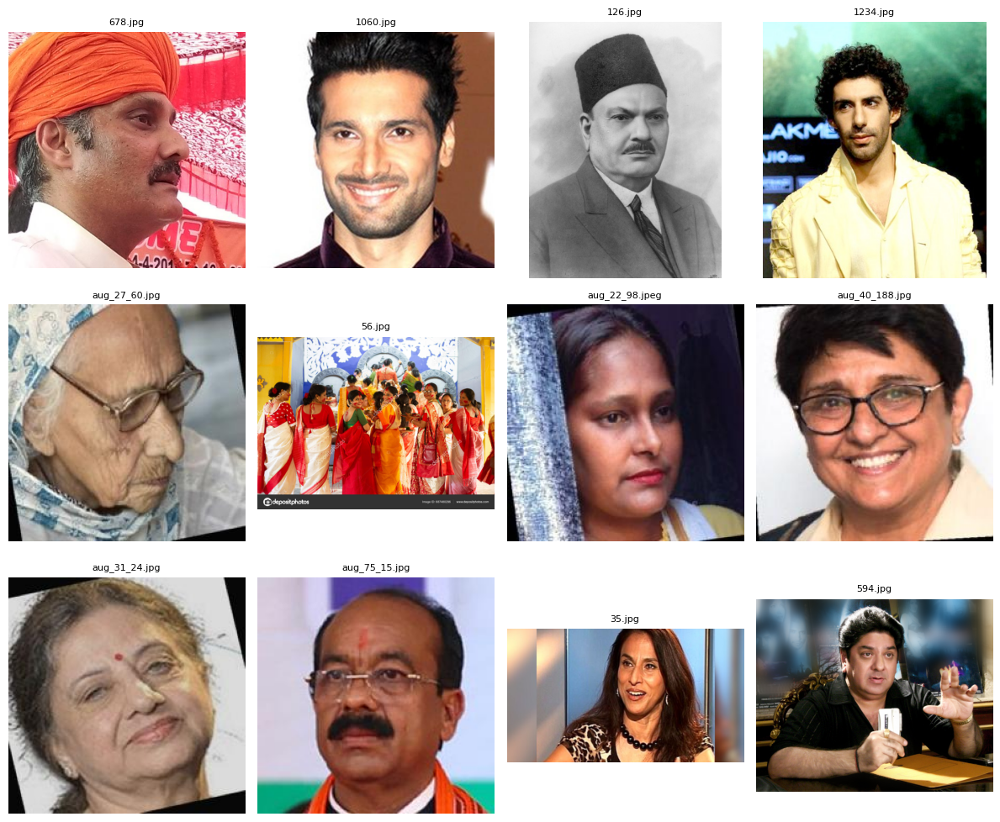

In [ ]:
usable = manifest[
    manifest["status"].eq("ok") &
    ~manifest["exact_duplicate"]
].copy()

if usable.empty:
    raise ValueError("No usable images available.")

sample = usable.sample(
    n=min(12, len(usable)),
    random_state=42,
)

fig, axes = plt.subplots(3, 4, figsize=(12, 10))

for ax in axes.flat:
    ax.axis("off")

for ax, relative_path in zip(axes.flat, sample["image_path"]):
    with Image.open(IMAGE_ROOT / relative_path) as im:
        ax.imshow(ImageOps.exif_transpose(im).convert("RGB"))
    ax.set_title(Path(relative_path).name[:24], fontsize=8)

plt.tight_layout()
plt.show()

In [ ]:
review = usable[
    ["image_path", "width", "height", "pixel_hash"]
].copy()

for column in [
    "person_id",
    "source_group_id",
    "include",
    "exclusion_reason",
    "age_eligibility",
    "notes",
]:
    review[column] = ""

review_path = PROJECT / "annotations" / "image_review.csv"

if review_path.exists():
    print("Existing review preserved:", review_path)
else:
    review.to_csv(review_path, index=False)
    print("Created:", review_path)

Created: /content/drive/MyDrive/Nimesha_Component3/annotations/image_review.csv


In [ ]:
from pathlib import Path, PurePosixPath
import pandas as pd

PROJECT = Path("/content/drive/MyDrive/Nimesha_Component3")
IMAGE_ROOT = Path("/content/indicfairface")

# Reuse the saved manifest without reopening all images.
manifest_path = PROJECT / "metadata" / "image_manifest.csv"

if not manifest_path.exists():
    raise FileNotFoundError(
        f"Manifest not found: {manifest_path}"
    )

audit = pd.read_csv(manifest_path)

# Normalize the stored duplicate flags.
duplicate_flags = (
    audit["exact_duplicate"]
    .astype(str)
    .str.strip()
    .str.lower()
)

if not duplicate_flags.isin(["true", "false", "1", "0"]).all():
    raise ValueError("Unexpected values in exact_duplicate column.")

audit["exact_duplicate"] = duplicate_flags.isin(["true", "1"])

def path_prefix(value, depth):
    parts = PurePosixPath(
        str(value).replace("\\", "/")
    ).parts
    folders = parts[:-1]
    return "/".join(folders[:depth]) or "(root)"

audit["folder_level_1"] = audit["image_path"].map(
    lambda value: path_prefix(value, 1)
)
audit["folder_level_2"] = audit["image_path"].map(
    lambda value: path_prefix(value, 2)
)

audit["filename"] = audit["image_path"].map(
    lambda value: PurePosixPath(
        str(value).replace("\\", "/")
    ).name
)

# This is a filename hint, not verified augmentation provenance.
audit["augmentation_name_hint"] = (
    audit["filename"].str.lower().str.startswith("aug_")
)

readable = audit["status"].eq("ok")
unique_readable = readable & ~audit["exact_duplicate"]

print("TOTAL RECORDS:", len(audit))
print("READABLE:", int(readable.sum()))
print("UNREADABLE:", int((~readable).sum()))
print("EXACT DUPLICATE COPIES:",
      int(audit["exact_duplicate"].sum()))
print("UNIQUE READABLE:", int(unique_readable.sum()))

print("\nTOP-LEVEL FOLDER COUNTS")
print(audit["folder_level_1"].value_counts().to_string())

print("\nSECOND-LEVEL FOLDER COUNTS — TOP 40")
print(
    audit["folder_level_2"]
    .value_counts()
    .head(40)
    .to_string()
)

print("\nMOST COMMON IMAGE DIMENSIONS")
print(
    audit.loc[readable]
    .groupby(["width", "height"])
    .size()
    .sort_values(ascending=False)
    .head(15)
    .to_string()
)

print("\nAUGMENTATION FILENAME HINTS")
print(audit["augmentation_name_hint"].value_counts().to_string())

print("\nEXAMPLE FULL RELATIVE PATHS")
for value in audit["image_path"].head(15):
    print(value)

# List possible metadata files without reading their contents.
metadata_extensions = {".csv", ".json", ".jsonl", ".txt", ".md"}

metadata_files = sorted(
    p.relative_to(IMAGE_ROOT).as_posix()
    for p in IMAGE_ROOT.rglob("*")
    if p.is_file() and p.suffix.lower() in metadata_extensions
)

print("\nMETADATA FILES — FIRST 40")
for value in metadata_files[:40]:
    print(value)

print("\nTotal metadata files:", len(metadata_files))

TOTAL RECORDS: 45039
READABLE: 44892
UNREADABLE: 147
EXACT DUPLICATE COPIES: 12039
UNIQUE READABLE: 32853

TOP-LEVEL FOLDER COUNTS
folder_level_1
final_dataset    45039

SECOND-LEVEL FOLDER COUNTS — TOP 40
folder_level_2
final_dataset/balanced_dataset        13728
final_dataset/wikimedia_extraction    12522
final_dataset/faces512_wikimedia       8641
final_dataset/search_api               5894
final_dataset/faces512_search_api      4254

MOST COMMON IMAGE DIMENSIONS
width   height
512.0   512.0     20600
224.0   224.0      6029
585.0   439.0       225
866.0   1390.0      184
585.0   881.0       163
686.0   386.0       137
390.0   280.0       122
612.0   408.0       121
400.0   225.0       109
1280.0  720.0       103
1300.0  956.0        96
1200.0  675.0        82
600.0   900.0        82
480.0   270.0        73
600.0   400.0        60

AUGMENTATION FILENAME HINTS
augmentation_name_hint
False    39010
True      6029

EXAMPLE FULL RELATIVE PATHS
final_dataset/balanced_dataset/andaman_and_

In [ ]:
from datetime import datetime, timezone
import numpy as np

# Temporary screening limits, not validated quality thresholds.
MIN_SIDE = 128
MAX_PIXELS = 25_000_000

width = pd.to_numeric(audit["width"], errors="coerce")
height = pd.to_numeric(audit["height"], errors="coerce")

invalid_dimensions = (
    width.isna() | height.isna() |
    (width <= 0) | (height <= 0)
)

small_image = (width < MIN_SIDE) | (height < MIN_SIDE)
large_image = (width * height) > MAX_PIXELS

audit["next_action"] = np.select(
    [
        ~audit["status"].eq("ok"),
        audit["exact_duplicate"],
        invalid_dimensions,
        large_image,
        small_image,
        audit["augmentation_name_hint"],
    ],
    [
        "exclude_unreadable",
        "exclude_exact_duplicate",
        "review_dimensions",
        "review_large_image",
        "review_low_resolution",
        "hold_for_augmentation_mapping",
    ],
    default="pending_face_quality_check",
)

# Keep identity fields unresolved until source metadata is checked.
audit["person_id"] = ""
audit["source_group_id"] = ""

output_folder = PROJECT / "annotations"
output_folder.mkdir(parents=True, exist_ok=True)

# Use a timestamp to preserve previous review files.
timestamp = datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S")
output_path = output_folder / f"automatic_review_{timestamp}.csv"

audit.to_csv(output_path, index=False)

print(audit["next_action"].value_counts().to_string())
print("\nSaved:", output_path)
print("\nNo source images were deleted.")

next_action
pending_face_quality_check       26619
exclude_exact_duplicate          12039
hold_for_augmentation_mapping     6029
exclude_unreadable                 147
review_low_resolution              105
review_large_image                 100

Saved: /content/drive/MyDrive/Nimesha_Component3/annotations/automatic_review_20261007_052259.csv

No source images were deleted.


In [ ]:
from pathlib import Path, PurePosixPath
import pandas as pd
from IPython.display import display

PROJECT = Path("/content/drive/MyDrive/Nimesha_Component3")
IMAGE_ROOT = Path("/content/indicfairface")

# Load the latest automatic review.
review_files = sorted(
    (PROJECT / "annotations").glob("automatic_review_*.csv")
)

if not review_files:
    raise FileNotFoundError("No automatic review CSV was found.")

review = pd.read_csv(review_files[-1])

def folder_prefix(value, depth=3):
    parts = PurePosixPath(
        str(value).replace("\\", "/")
    ).parts[:-1]
    return "/".join(parts[:depth]) or "(root)"

review["source_folder"] = review["image_path"].map(folder_prefix)

# Show where the remaining candidates are located.
candidates = review[
    review["next_action"].eq("pending_face_quality_check")
].copy()

print("CANDIDATE FOLDERS — TOP 20")
print(
    candidates["source_folder"]
    .value_counts()
    .head(20)
    .to_string()
)

print("\nEXAMPLE CANDIDATE PATHS")
for value in candidates["image_path"].head(8):
    print(value)

print("\nEXAMPLE AUGMENTED PATHS")
augmented = review[
    review["next_action"].eq("hold_for_augmentation_mapping")
]
for value in augmented["image_path"].head(8):
    print(value)

# Inspect a few metadata rows from each observed source.
for source_name in ["search_api", "wikimedia_extraction"]:
    matches = sorted(
        p for p in IMAGE_ROOT.rglob("*.csv")
        if source_name in p.parts
    )

    print(f"\n{'=' * 50}")
    print(f"METADATA SOURCE: {source_name}")
    print("CSV files found:", len(matches))

    if not matches:
        continue

    # Prefer a non-empty file that can be parsed.
    for metadata_path in matches:
        try:
            preview = pd.read_csv(metadata_path, nrows=3)

            if preview.empty:
                continue

            print("File:", metadata_path.relative_to(IMAGE_ROOT))
            print("Columns:", preview.columns.tolist())

            # Shorten long values for readable notebook output.
            display(
                preview.astype(str).apply(
                    lambda column: column.str.slice(0, 180)
                )
            )
            break

        except Exception as error:
            print(
                f"Could not read {metadata_path.name}: "
                f"{type(error).__name__}"
            )

CANDIDATE FOLDERS — TOP 20
source_folder
final_dataset/wikimedia_extraction/images        9923
final_dataset/search_api/images                  5632
final_dataset/faces512_wikimedia/Maharashtra     1583
final_dataset/faces512_wikimedia/Kerala           413
final_dataset/faces512_wikimedia/West Bengal      390
final_dataset/faces512_wikimedia/Tamil Nadu       378
final_dataset/balanced_dataset/kerala             318
final_dataset/balanced_dataset/maharashtra        314
final_dataset/balanced_dataset/tamil_nadu         312
final_dataset/balanced_dataset/west_bengal        312
final_dataset/balanced_dataset/karnataka          304
final_dataset/faces512_wikimedia/Delhi            298
final_dataset/balanced_dataset/andhra_pradesh     297
final_dataset/faces512_wikimedia/Karnataka        292
final_dataset/balanced_dataset/uttar_pradesh      288
final_dataset/balanced_dataset/delhi              284
final_dataset/balanced_dataset/gujarat            278
final_dataset/balanced_dataset/rajasthan 

,original,Gender,State/UT
0,https://c8.alamy.com/comp/BGAFPY/india-the-and...,female,Andaman and Nicobar Islands
1,https://assets.survivalinternational.org/pictu...,female,Andaman and Nicobar Islands
2,https://blueandamantour.com/wp-content/uploads...,female,Andaman and Nicobar Islands



METADATA SOURCE: wikimedia_extraction
CSV files found: 36
File: final_dataset/wikimedia_extraction/data/Andaman and Nicobar Islands.csv
Columns: ['association', 'person', 'image', 'birthDate', 'personLabel', 'associationLabel', 'Gender']


,association,person,image,birthDate,personLabel,associationLabel,Gender
0,http://www.wikidata.org/entity/Q157286,http://www.wikidata.org/entity/Q44427237,http://commons.wikimedia.org/wiki/Special:File...,1846-01-01T00:00:00Z,Edward Horace Man,Nicobar Islands,male
1,http://www.wikidata.org/entity/Q203476,http://www.wikidata.org/entity/Q56159566,http://commons.wikimedia.org/wiki/Special:File...,2001-03-10T00:00:00Z,Esow Alben,Port Blair,male
2,http://www.wikidata.org/entity/Q203476,http://www.wikidata.org/entity/Q21756488,http://commons.wikimedia.org/wiki/Special:File...,1995-02-18T00:00:00Z,Deborah Herold,Port Blair,female


In [ ]:
from pathlib import Path, PurePosixPath
import pandas as pd

PROJECT = Path("/content/drive/MyDrive/Nimesha_Component3")
IMAGE_ROOT = Path("/content/indicfairface")

manifest = pd.read_csv(
    PROJECT / "metadata" / "image_manifest.csv"
)

paths = manifest["image_path"].astype(str).str.replace(
    "\\", "/", regex=False
)

filenames = paths.map(lambda p: PurePosixPath(p).name)

# Select only the observed balanced dataset folder.
selected = manifest[
    paths.str.startswith("final_dataset/balanced_dataset/")
    & manifest["status"].eq("ok")
    & ~filenames.str.lower().str.startswith("aug_")
].copy()

# Recalculate exact duplicates within this subset.
selected = (
    selected.dropna(subset=["pixel_hash"])
    .sort_values("image_path")
    .drop_duplicates("pixel_hash")
)

# Apply temporary resource and resolution screening limits.
width = pd.to_numeric(selected["width"], errors="coerce")
height = pd.to_numeric(selected["height"], errors="coerce")

selected = selected[
    (width >= 128)
    & (height >= 128)
    & (width * height <= 25_000_000)
].copy()

if selected.empty:
    raise ValueError("No candidates found. Check the folder prefix.")

# Keep the full relative path as the image key, not a person ID.
selected["image_id"] = selected["image_path"]

(PROJECT / "processed").mkdir(parents=True, exist_ok=True)
selected.to_csv(
    PROJECT / "processed" / "balanced_original_candidates.csv",
    index=False,
)

print("Selected original-image candidates:", len(selected))
print("No source images were deleted.")

Selected original-image candidates: 7225
No source images were deleted.


In [ ]:
%pip -q install opencv-python-headless requests tqdm

In [ ]:
import cv2
import requests

MODEL_PATH = Path("/content/face_detection_yunet_2023mar.onnx")

MODEL_URL = (
    "https://media.githubusercontent.com/media/opencv/opencv_zoo/"
    "main/models/face_detection_yunet/"
    "face_detection_yunet_2023mar.onnx"
)

if not MODEL_PATH.exists():
    response = requests.get(MODEL_URL, timeout=120)
    response.raise_for_status()

    if len(response.content) < 10_000:
        raise RuntimeError("The model download appears invalid.")

    MODEL_PATH.write_bytes(response.content)

detector = cv2.FaceDetectorYN.create(
    str(MODEL_PATH),
    "",
    (320, 320),
    0.7,   # Preliminary detection threshold.
    0.3,
    5000,
)

print("OpenCV version:", cv2.__version__)
print("Face detector loaded.")

OpenCV version: 5.0.0
Face detector loaded.


In [ ]:
import numpy as np
import warnings
from PIL import Image, ImageOps
from tqdm.auto import tqdm
from datetime import datetime, timezone

# Start with a reproducible pilot instead of processing everything.
pilot = selected.sample(
    n=min(200, len(selected)),
    random_state=42,
).copy()

def inspect_face(relative_path):
    result = {"image_path": relative_path}

    try:
        # Preserve Pillow's protection against excessively large images.
        with warnings.catch_warnings():
            warnings.simplefilter("error", Image.DecompressionBombWarning)

            with Image.open(IMAGE_ROOT / relative_path) as source:
                rgb = ImageOps.exif_transpose(source).convert("RGB")

                # Resize proportionally for detection; never stretch.
                rgb.thumbnail((1024, 1024))
                bgr = cv2.cvtColor(np.array(rgb), cv2.COLOR_RGB2BGR)

        h, w = bgr.shape[:2]
        detector.setInputSize((w, h))
        _, faces = detector.detect(bgr)

        count = 0 if faces is None else len(faces)
        result["detected_faces"] = count

        if count == 0:
            result["screening_status"] = "review_no_face"
            return result

        if count > 1:
            result["screening_status"] = "review_multiple_faces"
            return result

        face = faces[0]
        x, y, fw, fh = map(float, face[:4])

        x1 = max(0, int(np.floor(x)))
        y1 = max(0, int(np.floor(y)))
        x2 = min(w, int(np.ceil(x + fw)))
        y2 = min(h, int(np.ceil(y + fh)))

        if x2 <= x1 or y2 <= y1:
            raise ValueError("Invalid face bounding box.")

        crop = bgr[y1:y2, x1:x2]
        gray = cv2.cvtColor(crop, cv2.COLOR_BGR2GRAY)

        # Standardize the crop scale for the provisional blur metric.
        normalized = cv2.resize(
            gray, (128, 128), interpolation=cv2.INTER_AREA
        )

        blur = float(cv2.Laplacian(normalized, cv2.CV_64F).var())
        brightness = float(gray.mean())
        dark_fraction = float((gray < 10).mean())
        bright_fraction = float((gray > 245).mean())

        eyes = face[4:8].reshape(2, 2)
        eyes = eyes[np.argsort(eyes[:, 0])]
        delta = eyes[1] - eyes[0]
        roll = float(np.degrees(np.arctan2(delta[1], delta[0])))

        flags = []

        if float(face[14]) < 0.9:
            flags.append("low_detection_score")
        if min(x2 - x1, y2 - y1) < 100:
            flags.append("small_face")
        if blur < 50:
            flags.append("possible_blur")
        if dark_fraction > 0.4 or bright_fraction > 0.4:
            flags.append("possible_exposure_issue")
        if abs(roll) > 15:
            flags.append("tilted_face")

        result.update({
            "detection_score": float(face[14]),
            "face_width_processed": x2 - x1,
            "face_height_processed": y2 - y1,
            "blur_score": blur,
            "brightness": brightness,
            "roll_degrees": roll,
            "flags": "|".join(flags),
            "screening_status": (
                "review_quality" if flags else "preliminary_pass"
            ),
        })

    except Exception as error:
        result.update({
            "screening_status": "processing_error",
            "error": f"{type(error).__name__}: {error}",
        })

    return result

records = []

for relative_path in tqdm(
    pilot["image_path"],
    total=len(pilot),
    desc="Screening pilot images",
):
    records.append(inspect_face(relative_path))

face_review = pd.DataFrame(records)

timestamp = datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S")
output_path = (
    PROJECT / "processed" / f"face_quality_pilot_{timestamp}.csv"
)

face_review.to_csv(output_path, index=False)

print("\nSCREENING RESULTS")
print(face_review["screening_status"].value_counts().to_string())
print("\nSaved:", output_path)

errors = face_review[
    face_review["screening_status"].eq("processing_error")
]

if not errors.empty:
    print("\nFIRST PROCESSING ERRORS")
    print(errors[["image_path", "error"]].head(3).to_string(index=False))

Screening pilot images:   0%|          | 0/200 [00:00<?, ?it/s]


SCREENING RESULTS
screening_status
preliminary_pass         164
review_quality            26
review_multiple_faces      8
review_no_face             2

Saved: /content/drive/MyDrive/Nimesha_Component3/processed/face_quality_pilot_20261007_053017.csv


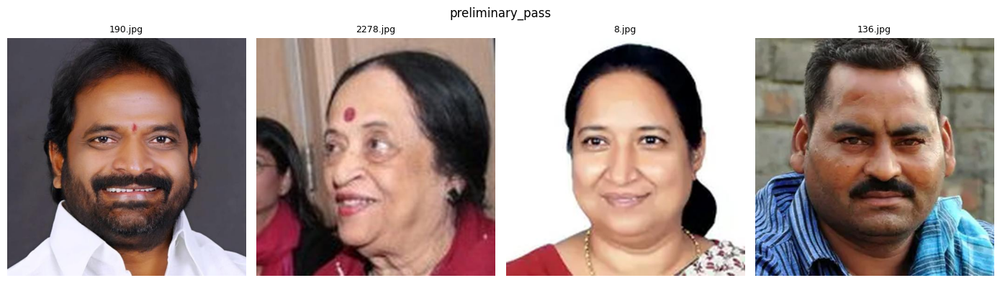

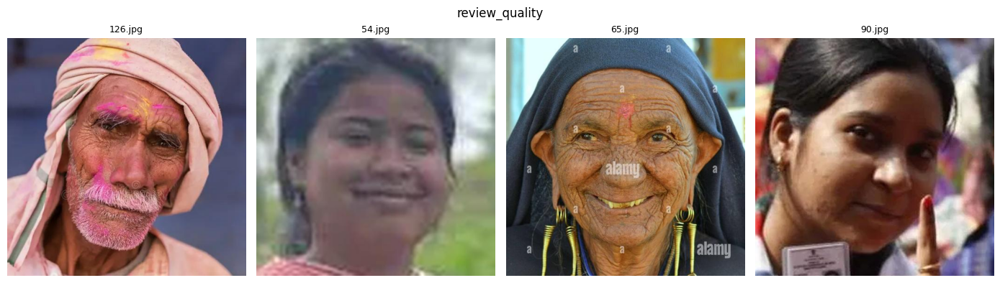

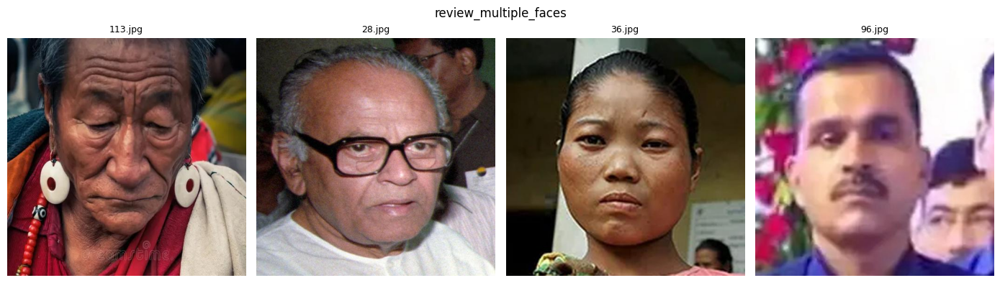

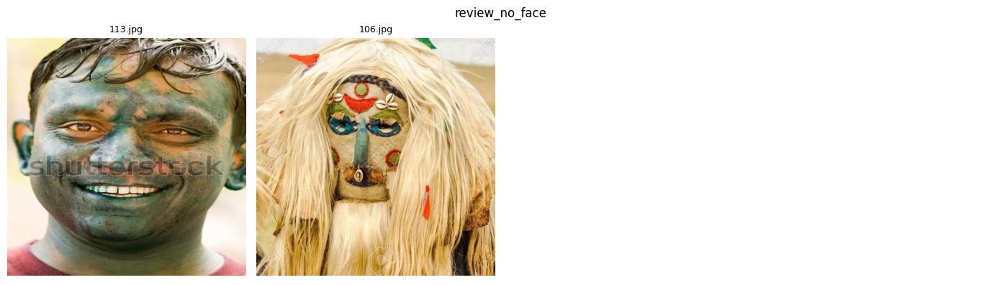

In [ ]:
import matplotlib.pyplot as plt

for status in [
    "preliminary_pass",
    "review_quality",
    "review_multiple_faces",
    "review_no_face",
]:
    group = face_review[
        face_review["screening_status"].eq(status)
    ]

    if group.empty:
        continue

    examples = group.sample(n=min(4, len(group)), random_state=42)

    fig, axes = plt.subplots(1, 4, figsize=(14, 4))
    fig.suptitle(status)

    for ax in axes:
        ax.axis("off")

    for ax, (_, row) in zip(axes, examples.iterrows()):
        with Image.open(IMAGE_ROOT / row["image_path"]) as source:
            preview = ImageOps.exif_transpose(source).convert("RGB")
            preview.thumbnail((500, 500))
            ax.imshow(preview)

        ax.set_title(
            Path(row["image_path"]).name,
            fontsize=9,
        )

    plt.tight_layout()
    plt.show()

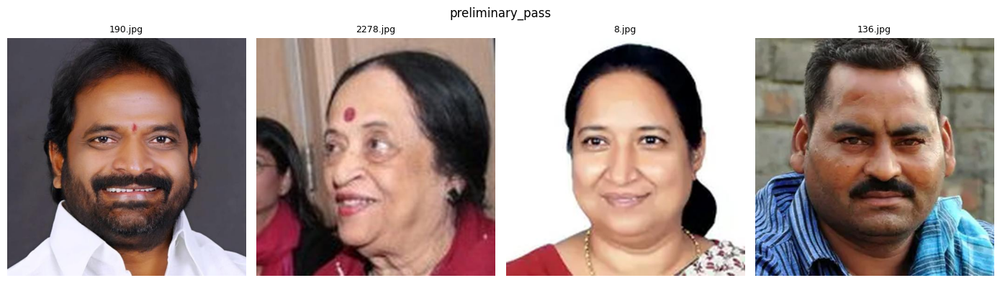

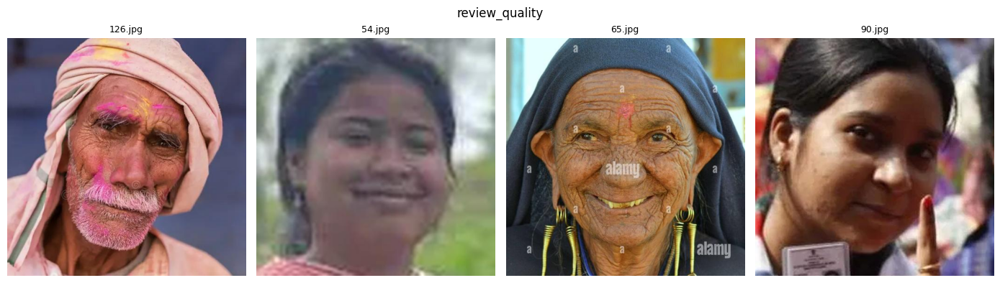

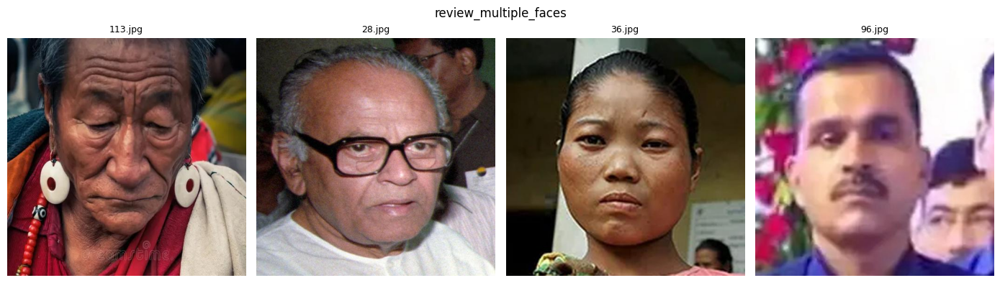

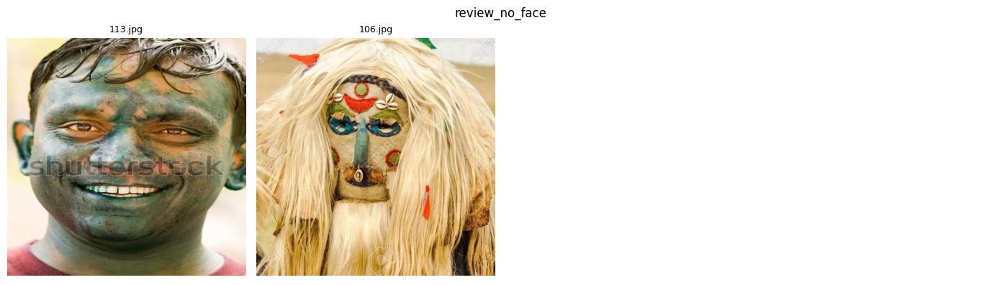

In [ ]:
import matplotlib.pyplot as plt

for status in [
    "preliminary_pass",
    "review_quality",
    "review_multiple_faces",
    "review_no_face",
]:
    group = face_review[
        face_review["screening_status"].eq(status)
    ]

    if group.empty:
        continue

    examples = group.sample(n=min(4, len(group)), random_state=42)

    fig, axes = plt.subplots(1, 4, figsize=(14, 4))
    fig.suptitle(status)

    for ax in axes:
        ax.axis("off")

    for ax, (_, row) in zip(axes, examples.iterrows()):
        with Image.open(IMAGE_ROOT / row["image_path"]) as source:
            preview = ImageOps.exif_transpose(source).convert("RGB")
            preview.thumbnail((500, 500))
            ax.imshow(preview)

        ax.set_title(
            Path(row["image_path"]).name,
            fontsize=9,
        )

    plt.tight_layout()
    plt.show()

In [ ]:
from pathlib import Path
import pandas as pd
from tqdm.auto import tqdm

PROJECT = Path("/content/drive/MyDrive/Nimesha_Component3")
IMAGE_ROOT = Path("/content/indicfairface")

CANDIDATES_PATH = (
    PROJECT / "processed" / "balanced_original_candidates.csv"
)
RESULTS_PATH = (
    PROJECT / "annotations" / "face_quality_full_v1.csv"
)

RESULTS_PATH.parent.mkdir(parents=True, exist_ok=True)

# Check that the previous setup cells are ready.
if not callable(globals().get("inspect_face")):
    raise RuntimeError("Run the inspect_face setup cell first.")

if not IMAGE_ROOT.exists():
    raise FileNotFoundError("Extract the image dataset before continuing.")

# Load the previously selected image candidates.
candidates = pd.read_csv(CANDIDATES_PATH)
candidates = candidates.drop_duplicates(subset=["image_path"])

# Resume from an existing checkpoint.
if RESULTS_PATH.exists():
    previous = pd.read_csv(RESULTS_PATH)
    records = previous.to_dict("records")
    completed = set(previous["image_path"])
else:
    records = []
    completed = set()

pending = candidates.loc[
    ~candidates["image_path"].isin(completed),
    "image_path"
].tolist()

print(f"Total candidates: {len(candidates)}")
print(f"Already processed: {len(completed)}")
print(f"Remaining images: {len(pending)}")

def save_checkpoint():
    # Write a temporary file before replacing the checkpoint.
    temporary_path = RESULTS_PATH.with_suffix(".tmp.csv")
    pd.DataFrame(records).to_csv(temporary_path, index=False)
    temporary_path.replace(RESULTS_PATH)

try:
    for index, relative_path in enumerate(
        tqdm(pending, desc="Screening images"),
        start=1
    ):
        result = inspect_face(relative_path)
        records.append(result)

        if index % 200 == 0:
            save_checkpoint()
finally:
    # Preserve completed work when execution is interrupted.
    if records:
        save_checkpoint()

print(f"Results saved to: {RESULTS_PATH}")

Total candidates: 7225
Already processed: 0
Remaining images: 7225


Screening images:   0%|          | 0/7225 [00:00<?, ?it/s]

Results saved to: /content/drive/MyDrive/Nimesha_Component3/annotations/face_quality_full_v1.csv


In [ ]:
import pandas as pd

results = pd.read_csv(RESULTS_PATH)

# Keep results belonging to the current candidate list.
results = results[
    results["image_path"].isin(candidates["image_path"])
].drop_duplicates(subset=["image_path"], keep="last")

summary = (
    results["screening_status"]
    .value_counts()
    .rename_axis("screening_status")
    .reset_index(name="image_count")
)

summary["percentage"] = (
    summary["image_count"] / len(results) * 100
).round(2)

display(summary)

# These images still require downstream suitability checks.
provisional = results[
    results["screening_status"].eq("preliminary_pass")
].copy()

# Preserve flagged images for later review.
review_queue = results[
    ~results["screening_status"].eq("preliminary_pass")
].copy()

output_dir = PROJECT / "processed"
output_dir.mkdir(parents=True, exist_ok=True)

provisional.to_csv(
    output_dir / "provisional_face_candidates_v1.csv",
    index=False
)

review_queue.to_csv(
    output_dir / "face_review_queue_v1.csv",
    index=False
)

print(f"Screened images: {len(results)}")
print(f"Provisional candidates: {len(provisional)}")
print(f"Flagged images: {len(review_queue)}")
print(f"Unprocessed images: {len(candidates) - len(results)}")

,screening_status,image_count,percentage
0,preliminary_pass,5847,80.93
1,review_quality,1005,13.91
2,review_multiple_faces,292,4.04
3,review_no_face,81,1.12


Screened images: 7225
Provisional candidates: 5847
Flagged images: 1378
Unprocessed images: 0


In [ ]:
from pathlib import Path
import hashlib
import pandas as pd

PROJECT = Path("/content/drive/MyDrive/Nimesha_Component3")
TRAINING_DIR = PROJECT / "training_data"
TRAINING_DIR.mkdir(parents=True, exist_ok=True)

SOURCE_PATH = (
    PROJECT / "processed" / "provisional_face_candidates_v1.csv"
)
PROFILE_PATH = TRAINING_DIR / "pilot_profiles_v1.csv"

# Preserve existing work when this cell is rerun.
if PROFILE_PATH.exists():
    profiles = pd.read_csv(PROFILE_PATH, keep_default_na=False)
    print("Loaded the existing pilot profiles.")
else:
    candidates = pd.read_csv(SOURCE_PATH)
    candidates = candidates.drop_duplicates("image_path")

    profiles = candidates.sample(
        n=min(100, len(candidates)),
        random_state=42
    )[["image_path"]].copy()

    # A profile ID identifies an image record, not a unique person.
    profiles.insert(
        0,
        "profile_id",
        profiles["image_path"].map(
            lambda path: "P_" + hashlib.sha256(
                path.encode("utf-8")
            ).hexdigest()[:16]
        )
    )

    # Leave unverified attributes empty.
    empty_columns = [
        "person_group_id",
        "face_shape",
        "jawline_shape",
        "hair_texture",
        "hair_density",
        "beard_growth_density",
        "attribute_source",
        "reviewer_id",
        "notes"
    ]

    for column in empty_columns:
        profiles[column] = ""

    profiles["profile_status"] = "pending"

    profiles.to_csv(PROFILE_PATH, index=False)
    print("Created the pilot profile template.")

print(f"Profiles: {len(profiles)}")
print(f"Saved at: {PROFILE_PATH}")
display(profiles.head())

Created the pilot profile template.
Profiles: 100
Saved at: /content/drive/MyDrive/Nimesha_Component3/training_data/pilot_profiles_v1.csv


,profile_id,image_path,person_group_id,face_shape,jawline_shape,hair_texture,hair_density,beard_growth_density,attribute_source,reviewer_id,notes,profile_status
5110,P_bda3b1cccd66b71b,final_dataset/balanced_dataset/tripura/female/...,,,,,,,,,,pending
3309,P_96f092bb2ff722cc,final_dataset/balanced_dataset/maharashtra/mal...,,,,,,,,,,pending
4233,P_b8e4a4ab29f94482,final_dataset/balanced_dataset/punjab/male/102...,,,,,,,,,,pending
5527,P_80bca6f64463ee74,final_dataset/balanced_dataset/uttarakhand/mal...,,,,,,,,,,pending
681,P_ec4a26bde733dd6b,final_dataset/balanced_dataset/bihar/female/82...,,,,,,,,,,pending


In [ ]:
STYLE_PATH = TRAINING_DIR / "style_catalogue_v1.csv"

if STYLE_PATH.exists():
    styles = pd.read_csv(STYLE_PATH, keep_default_na=False)
    print("Loaded the existing style catalogue.")
else:
    styles = pd.DataFrame([
        {
            "style_id": "H001",
            "category": "hair",
            "style_name": "Crew cut"
        },
        {
            "style_id": "H002",
            "category": "hair",
            "style_name": "Textured crop"
        },
        {
            "style_id": "H003",
            "category": "hair",
            "style_name": "Side part"
        },
        {
            "style_id": "H004",
            "category": "hair",
            "style_name": "Layered cut"
        },
        {
            "style_id": "B001",
            "category": "beard",
            "style_name": "Clean shaven"
        },
        {
            "style_id": "B002",
            "category": "beard",
            "style_name": "Short stubble"
        },
        {
            "style_id": "B003",
            "category": "beard",
            "style_name": "Short boxed beard"
        },
        {
            "style_id": "B004",
            "category": "beard",
            "style_name": "Goatee"
        }
    ])

    # Complete these definitions before collecting expert ratings.
    styles["definition"] = ""
    styles["reference_image"] = ""
    styles["catalogue_status"] = "draft"

    styles.to_csv(STYLE_PATH, index=False)
    print("Created the draft style catalogue.")

display(styles)

Created the draft style catalogue.


,style_id,category,style_name,definition,reference_image,catalogue_status
0,H001,hair,Crew cut,,,draft
1,H002,hair,Textured crop,,,draft
2,H003,hair,Side part,,,draft
3,H004,hair,Layered cut,,,draft
4,B001,beard,Clean shaven,,,draft
5,B002,beard,Short stubble,,,draft
6,B003,beard,Short boxed beard,,,draft
7,B004,beard,Goatee,,,draft


In [ ]:
RATING_PATH = TRAINING_DIR / "pilot_ratings_v1.csv"

if RATING_PATH.exists():
    ratings = pd.read_csv(RATING_PATH, keep_default_na=False)
    print("Loaded the existing rating table.")
else:
    ratings = profiles[
        ["profile_id", "image_path"]
    ].merge(
        styles[["style_id", "category", "style_name"]],
        how="cross"
    )

    # Rank styles within each profile and recommendation category.
    ratings["query_id"] = (
        ratings["profile_id"] + "_" + ratings["category"]
    )

    # Empty ratings are not zero ratings.
    ratings["compatibility_rating"] = ""
    ratings["rater_id"] = ""
    ratings["label_source"] = ""
    ratings["rating_status"] = "pending"
    ratings["reason"] = ""

    ratings.to_csv(RATING_PATH, index=False)
    print("Created the rating template.")

print(f"Candidate pairs: {len(ratings)}")
print(f"Saved at: {RATING_PATH}")
display(ratings.head(8))

Created the rating template.
Candidate pairs: 800
Saved at: /content/drive/MyDrive/Nimesha_Component3/training_data/pilot_ratings_v1.csv


,profile_id,image_path,style_id,category,style_name,query_id,compatibility_rating,rater_id,label_source,rating_status,reason
0,P_bda3b1cccd66b71b,final_dataset/balanced_dataset/tripura/female/...,H001,hair,Crew cut,P_bda3b1cccd66b71b_hair,,,,pending,
1,P_bda3b1cccd66b71b,final_dataset/balanced_dataset/tripura/female/...,H002,hair,Textured crop,P_bda3b1cccd66b71b_hair,,,,pending,
2,P_bda3b1cccd66b71b,final_dataset/balanced_dataset/tripura/female/...,H003,hair,Side part,P_bda3b1cccd66b71b_hair,,,,pending,
3,P_bda3b1cccd66b71b,final_dataset/balanced_dataset/tripura/female/...,H004,hair,Layered cut,P_bda3b1cccd66b71b_hair,,,,pending,
4,P_bda3b1cccd66b71b,final_dataset/balanced_dataset/tripura/female/...,B001,beard,Clean shaven,P_bda3b1cccd66b71b_beard,,,,pending,
5,P_bda3b1cccd66b71b,final_dataset/balanced_dataset/tripura/female/...,B002,beard,Short stubble,P_bda3b1cccd66b71b_beard,,,,pending,
6,P_bda3b1cccd66b71b,final_dataset/balanced_dataset/tripura/female/...,B003,beard,Short boxed beard,P_bda3b1cccd66b71b_beard,,,,pending,
7,P_bda3b1cccd66b71b,final_dataset/balanced_dataset/tripura/female/...,B004,beard,Goatee,P_bda3b1cccd66b71b_beard,,,,pending,


In [ ]:
profiles = pd.read_csv(PROFILE_PATH, keep_default_na=False)
ratings = pd.read_csv(RATING_PATH, keep_default_na=False)

numeric_ratings = pd.to_numeric(
    ratings["compatibility_rating"],
    errors="coerce"
)

valid_rating = numeric_ratings.isin([0, 1, 2, 3])

has_rater = (
    ratings["rater_id"].astype(str).str.strip().ne("")
)

reviewed_rating = ratings["rating_status"].eq("reviewed")
reviewed_profile = profiles["profile_status"].eq("reviewed")

print(f"Total profiles: {len(profiles)}")
print(f"Reviewed profiles: {reviewed_profile.sum()}")
print(f"Candidate pairs: {len(ratings)}")
print(
    "Reviewed pairs with valid ratings and a rater:",
    (valid_rating & has_rater & reviewed_rating).sum()
)
print(f"Unrated pairs: {numeric_ratings.isna().sum()}")

Total profiles: 100
Reviewed profiles: 0
Candidate pairs: 800
Reviewed pairs with valid ratings and a rater: 0
Unrated pairs: 800


In [ ]:
%pip -q install mediapipe requests tqdm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.6/40.6 MB 17.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.4/137.4 kB 9.4 MB/s eta 0:00:00


In [ ]:
from pathlib import Path
import hashlib
import json
import math
import warnings

import numpy as np
import pandas as pd
import requests
import mediapipe as mp

from PIL import Image, ImageOps
from tqdm.auto import tqdm
from mediapipe.tasks import python
from mediapipe.tasks.python import vision

PROJECT = Path("/content/drive/MyDrive/Nimesha_Component3")
IMAGE_ROOT = Path("/content/indicfairface")
AUTO_DIR = PROJECT / "training_data" / "automatic_v1"
AUTO_DIR.mkdir(parents=True, exist_ok=True)

# Load the existing pilot without changing its manual-review fields.
profiles = pd.read_csv(
    PROJECT / "training_data" / "pilot_profiles_v1.csv",
    keep_default_na=False
)

# Check that the dataset is still available in this runtime.
missing = [
    path for path in profiles["image_path"]
    if not (IMAGE_ROOT / path).is_file()
]

if missing:
    raise FileNotFoundError(
        f"{len(missing)} pilot images are missing. "
        "Run the previous dataset extraction cell again."
    )

MODEL_PATH = Path("/content/nimesha_face_landmarker.task")

MODEL_URL = (
    "https://storage.googleapis.com/mediapipe-models/"
    "face_landmarker/face_landmarker/float16/latest/"
    "face_landmarker.task"
)

# Download the pretrained landmark model.
if not MODEL_PATH.exists():
    response = requests.get(MODEL_URL, timeout=120)
    response.raise_for_status()

    if len(response.content) < 1_000_000:
        raise RuntimeError("The downloaded model file is unexpectedly small.")

    MODEL_PATH.write_bytes(response.content)

options = vision.FaceLandmarkerOptions(
    base_options=python.BaseOptions(
        model_asset_path=str(MODEL_PATH)
    ),
    running_mode=vision.RunningMode.IMAGE,
    num_faces=2,
    min_face_detection_confidence=0.7,
    min_face_presence_confidence=0.7
)

print(f"Pilot profiles loaded: {len(profiles)}")
print("Landmark model ready.")

Pilot profiles loaded: 100
Landmark model ready.


In [ ]:
def extract_geometry(row, landmarker):
    result = {
        "profile_id": row["profile_id"],
        "image_path": row["image_path"],
        "attribute_source": "mediapipe_geometry_proxy_v1"
    }

    try:
        # Read the image and apply its orientation metadata.
        with warnings.catch_warnings():
            warnings.simplefilter(
                "error",
                Image.DecompressionBombWarning
            )

            with Image.open(IMAGE_ROOT / row["image_path"]) as source:
                if source.width * source.height > 25_000_000:
                    result["geometry_status"] = "excluded_large_image"
                    return result

                rgb = ImageOps.exif_transpose(source).convert("RGB")
                rgb.thumbnail((1024, 1024))
                array = np.ascontiguousarray(rgb, dtype=np.uint8)

        image = mp.Image(
            image_format=mp.ImageFormat.SRGB,
            data=array
        )
        detected = landmarker.detect(image)

        count = len(detected.face_landmarks)
        result["detected_faces"] = count

        # Avoid selecting an arbitrary face from a group photo.
        if count != 1:
            result["geometry_status"] = (
                "excluded_no_face"
                if count == 0
                else "excluded_multiple_faces"
            )
            return result

        height, width = array.shape[:2]

        points = np.array([
            [point.x * width, point.y * height]
            for point in detected.face_landmarks[0]
        ])

        required = [
            10, 152, 234, 454, 172, 397,
            127, 356, 2, 1, 33, 263
        ]
        selected_points = points[required]

        # Reject invalid or clipped measurements.
        if (
            not np.isfinite(selected_points).all()
            or (selected_points < 0).any()
            or (selected_points[:, 0] >= width).any()
            or (selected_points[:, 1] >= height).any()
        ):
            result["geometry_status"] = "excluded_landmarks"
            return result

        def distance(first, second):
            return float(
                np.linalg.norm(points[first] - points[second])
            )

        face_width = distance(234, 454)
        face_length = distance(10, 152)

        if min(face_width, face_length) < 100:
            result["geometry_status"] = "excluded_small_face"
            return result

        # Estimate roll and a simple off-centre pose indicator.
        eyes = points[[33, 263]]
        eyes = eyes[np.argsort(eyes[:, 0])]

        eye_vector = eyes[1] - eyes[0]
        eye_distance = np.linalg.norm(eye_vector)

        if eye_distance < 1:
            result["geometry_status"] = "excluded_landmarks"
            return result

        roll = math.degrees(
            math.atan2(eye_vector[1], eye_vector[0])
        )

        cheek_midpoint = (points[234] + points[454]) / 2
        nose_offset = abs(
            float(np.dot(
                points[1] - cheek_midpoint,
                eye_vector / eye_distance
            ))
        ) / face_width

        result.update({
            "face_length_ratio": face_length / face_width,
            "jaw_width_ratio": distance(172, 397) / face_width,
            "upper_width_ratio": distance(127, 356) / face_width,
            "lower_face_ratio": distance(2, 152) / face_length,
            "roll_degrees": roll,
            "nose_offset_ratio": nose_offset
        })

        # These thresholds are provisional screening heuristics.
        if abs(roll) > 20 or nose_offset > 0.12:
            result["geometry_status"] = "excluded_pose_heuristic"
        else:
            result["geometry_status"] = "geometry_proxy_pass"

    except Exception as error:
        result["geometry_status"] = "processing_error"
        result["error"] = f"{type(error).__name__}: {error}"

    return result


records = []

with vision.FaceLandmarker.create_from_options(options) as landmarker:
    for row in tqdm(
        profiles.to_dict("records"),
        desc="Extracting pilot geometry"
    ):
        records.append(extract_geometry(row, landmarker))

geometry = pd.DataFrame(records)

OUTPUT_PATH = AUTO_DIR / "pilot_geometry_v1.csv"
geometry.to_csv(OUTPUT_PATH, index=False)

# Record the extractor version and the downloaded model identity.
metadata = {
    "extractor": "mediapipe_geometry_proxy_v1",
    "mediapipe_version": mp.__version__,
    "model_sha256": hashlib.sha256(
        MODEL_PATH.read_bytes()
    ).hexdigest(),
    "max_abs_roll_degrees": 20,
    "max_nose_offset_ratio": 0.12,
    "expert_validated": False
}

(AUTO_DIR / "geometry_metadata.json").write_text(
    json.dumps(metadata, indent=2)
)

print(f"Saved to: {OUTPUT_PATH}")

Extracting pilot geometry:   0%|          | 0/100 [00:00<?, ?it/s]

Saved to: /content/drive/MyDrive/Nimesha_Component3/training_data/automatic_v1/pilot_geometry_v1.csv


In [ ]:
display(
    geometry["geometry_status"]
    .value_counts()
    .rename_axis("status")
    .to_frame("image_count")
)

feature_columns = [
    "face_length_ratio",
    "jaw_width_ratio",
    "upper_width_ratio",
    "lower_face_ratio"
]

usable = geometry[
    geometry["geometry_status"].eq("geometry_proxy_pass")
].copy()

print(f"Processed profiles: {len(geometry)}")
print(f"Usable geometry profiles: {len(usable)}")

if not usable.empty:
    display(
        usable[
            ["profile_id"] + feature_columns
        ].head(10)
    )

errors = geometry[
    geometry["geometry_status"].eq("processing_error")
]

if not errors.empty:
    display(errors[["image_path", "error"]].head(5))

,image_count
status,
geometry_proxy_pass,55
excluded_pose_heuristic,44
excluded_landmarks,1


Processed profiles: 100
Usable geometry profiles: 55


,profile_id,face_length_ratio,jaw_width_ratio,upper_width_ratio,lower_face_ratio
0,P_bda3b1cccd66b71b,1.182484,0.778909,1.004450,0.400203
2,P_b8e4a4ab29f94482,1.091349,0.811736,1.000167,0.431790
4,P_ec4a26bde733dd6b,1.111377,0.815700,1.004423,0.409339
10,P_b2123ba1f8433891,1.137726,0.846344,1.003443,0.428736
11,P_2904ef2a79afd3e4,1.342313,0.835057,0.987222,0.459447
13,P_0a79a6c526092832,1.199107,0.764408,1.011939,0.330489
14,P_8d8132d4f3b03bbe,1.146345,0.786523,1.010734,0.392876
16,P_ff3ecfd012f27b75,1.136805,0.857319,0.989744,0.424097
17,P_f31d7159d37c7ada,1.198950,0.795134,0.997838,0.397440
18,P_089697a5a1265073,1.224232,0.801361,1.009290,0.371875


In [ ]:
from pathlib import Path
import json
import numpy as np
import pandas as pd

PROJECT = Path("/content/drive/MyDrive/Nimesha_Component3")

C3_DIR = PROJECT / "component3_prototype_v1"
C3_DIR.mkdir(parents=True, exist_ok=True)

INPUT_PATH = (
    PROJECT / "training_data" / "automatic_v1"
    / "pilot_geometry_v1.csv"
)

FEATURES = [
    "face_length_ratio",
    "jaw_width_ratio",
    "upper_width_ratio",
    "lower_face_ratio"
]

geometry = pd.read_csv(INPUT_PATH)

# Use existing measurements as temporary Component 2 inputs.
c3_profiles = geometry[
    geometry["geometry_status"].eq("geometry_proxy_pass")
][["profile_id"] + FEATURES].copy()

c3_profiles = c3_profiles.drop_duplicates("profile_id")

# Stop instead of silently training on invalid inputs.
values = c3_profiles[FEATURES].to_numpy(dtype=float)

if not np.isfinite(values).all():
    raise ValueError("Input profiles contain missing or invalid measurements.")

if len(c3_profiles) < 20:
    raise ValueError("Too few profiles for this prototype split.")

print(f"Component 3 input profiles: {len(c3_profiles)}")
display(c3_profiles.head())

Component 3 input profiles: 55


,profile_id,face_length_ratio,jaw_width_ratio,upper_width_ratio,lower_face_ratio
0,P_bda3b1cccd66b71b,1.182484,0.778909,1.004450,0.400203
2,P_b8e4a4ab29f94482,1.091349,0.811736,1.000167,0.431790
4,P_ec4a26bde733dd6b,1.111377,0.815700,1.004423,0.409339
10,P_b2123ba1f8433891,1.137726,0.846344,1.003443,0.428736
11,P_2904ef2a79afd3e4,1.342313,0.835057,0.987222,0.459447


In [ ]:
# These target values are illustrative assumptions, not expert labels.
style_rows = [
    ("H001", "hair", "Crew cut",          1.45, 0.80, 0.96, 0.43),
    ("H002", "hair", "Textured crop",     1.38, 0.86, 0.95, 0.43),
    ("H003", "hair", "Side part",         1.25, 0.90, 0.96, 0.44),
    ("H004", "hair", "Layered cut",       1.30, 0.76, 0.91, 0.42),
    ("B001", "beard", "Clean shaven",     1.45, 0.90, 0.95, 0.45),
    ("B002", "beard", "Short stubble",    1.35, 0.84, 0.95, 0.43),
    ("B003", "beard", "Short boxed beard",1.22, 0.78, 0.94, 0.40),
    ("B004", "beard", "Goatee",           1.20, 0.91, 0.95, 0.40)
]

TARGET_COLUMNS = ["target_" + name for name in FEATURES]

c3_styles = pd.DataFrame(
    style_rows,
    columns=[
        "style_id", "category", "style_name",
        *TARGET_COLUMNS
    ]
)

RULE_CONFIG = {
    "version": "illustrative_rules_v1",
    "features": FEATURES,
    "weights": [0.45, 0.25, 0.20, 0.10],
    "scales": [0.20, 0.12, 0.10, 0.12],
    "expert_validated": False
}

def calculate_rule_scores(frame):
    actual = frame[FEATURES].to_numpy(dtype=float)
    targets = frame[TARGET_COLUMNS].to_numpy(dtype=float)

    # Convert each feature difference into a similarity term.
    differences = (
        (actual - targets)
        / np.array(RULE_CONFIG["scales"])
    )

    similarities = np.exp(-0.5 * differences ** 2)

    # Combine the four similarity terms using fixed weights.
    return similarities @ np.array(RULE_CONFIG["weights"])


c3_styles.to_csv(C3_DIR / "style_catalogue.csv", index=False)

(C3_DIR / "rule_config.json").write_text(
    json.dumps(RULE_CONFIG, indent=2)
)

display(c3_styles[["style_id", "category", "style_name"]])

,style_id,category,style_name
0,H001,hair,Crew cut
1,H002,hair,Textured crop
2,H003,hair,Side part
3,H004,hair,Layered cut
4,B001,beard,Clean shaven
5,B002,beard,Short stubble
6,B003,beard,Short boxed beard
7,B004,beard,Goatee


In [ ]:
# Split profiles before creating candidate pairs.
profile_ids = np.array(
    sorted(c3_profiles["profile_id"].unique())
)

rng = np.random.default_rng(42)
rng.shuffle(profile_ids)

train_end = int(len(profile_ids) * 0.70)
validation_end = train_end + int(len(profile_ids) * 0.15)

split_map = {}

for index, profile_id in enumerate(profile_ids):
    if index < train_end:
        split_map[profile_id] = "train"
    elif index < validation_end:
        split_map[profile_id] = "validation"
    else:
        split_map[profile_id] = "test"

c3_profiles["split"] = c3_profiles["profile_id"].map(split_map)

# Create every profile-style combination.
c3_pairs = c3_profiles.merge(c3_styles, how="cross")

c3_pairs["query_id"] = (
    c3_pairs["profile_id"] + "_" + c3_pairs["category"]
)

# Generate explicit pseudo-labels, not human-reviewed ratings.
c3_pairs["teacher_score"] = calculate_rule_scores(c3_pairs)
c3_pairs["label_source"] = "illustrative_rules_v1"
c3_pairs["expert_validated"] = False

c3_profiles.to_csv(
    C3_DIR / "input_profiles_with_splits.csv",
    index=False
)

c3_pairs.to_csv(
    C3_DIR / "weak_training_pairs.csv",
    index=False
)

display(
    c3_profiles.groupby("split").size().to_frame("profiles")
)

print(f"Profile-style pairs: {len(c3_pairs)}")

,profiles
split,
test,9
train,38
validation,8


Profile-style pairs: 440


In [ ]:
%pip -q install catboost

In [ ]:
from catboost import CatBoostRanker, Pool

MODEL_DIR = C3_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Exclude teacher scores, rule targets, IDs and split labels from inputs.
MODEL_FEATURES = FEATURES + ["style_id"]

c3_models = {}
training_summary = []

def create_ranking_pool(frame):
    # CatBoost requires each ranking group to occupy consecutive rows.
    ordered = frame.sort_values(
        ["query_id", "style_id"]
    ).copy()

    return Pool(
        data=ordered[MODEL_FEATURES],
        label=ordered["teacher_score"],
        group_id=ordered["query_id"].tolist(),
        cat_features=["style_id"]
    )


for category in ["hair", "beard"]:
    category_pairs = c3_pairs[
        c3_pairs["category"].eq(category)
    ]

    train_rows = category_pairs[
        category_pairs["split"].eq("train")
    ]

    validation_rows = category_pairs[
        category_pairs["split"].eq("validation")
    ]

    model = CatBoostRanker(
        iterations=400,
        depth=5,
        learning_rate=0.05,
        loss_function="YetiRank",
        eval_metric="NDCG:top=3",
        random_seed=42,
        task_type="CPU",
        thread_count=2,
        allow_writing_files=False
    )

    print(f"Training {category} rule-imitation model...")

    model.fit(
        create_ranking_pool(train_rows),
        eval_set=create_ranking_pool(validation_rows),
        early_stopping_rounds=50,
        use_best_model=True,
        verbose=100
    )

    model_path = MODEL_DIR / f"{category}_ranker.cbm"
    model.save_model(str(model_path))

    c3_models[category] = model

    training_summary.append({
        "category": category,
        "training_rows": len(train_rows),
        "validation_rows": len(validation_rows),
        "trees": model.tree_count_,
        "saved_model": str(model_path),
        "label_source": "illustrative_rules_v1",
        "expert_validated": False
    })

summary = pd.DataFrame(training_summary)

summary.to_csv(
    C3_DIR / "training_summary.csv",
    index=False
)

display(summary)
print("Component 3 prototype ranking models saved.")

Training hair rule-imitation model...
Groupwise loss function. OneHotMaxSize set to 10
0:	test: 0.9996712	best: 0.9996712 (0)	total: 55.2ms	remaining: 22s
Stopped by overfitting detector  (50 iterations wait)

bestTest = 0.9999640974
bestIteration = 2

Shrink model to first 3 iterations.
Training beard rule-imitation model...
Groupwise loss function. OneHotMaxSize set to 10
0:	test: 0.9889770	best: 0.9889770 (0)	total: 1.16ms	remaining: 463ms
Stopped by overfitting detector  (50 iterations wait)

bestTest = 1
bestIteration = 3

Shrink model to first 4 iterations.


,category,training_rows,validation_rows,trees,saved_model,label_source,expert_validated
0,hair,152,32,3,/content/drive/MyDrive/Nimesha_Component3/comp...,illustrative_rules_v1,False
1,beard,152,32,4,/content/drive/MyDrive/Nimesha_Component3/comp...,illustrative_rules_v1,False


Component 3 prototype ranking models saved.


In [ ]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from catboost import CatBoostRanker

C3_DIR = Path(
    "/content/drive/MyDrive/Nimesha_Component3/"
    "component3_prototype_v1"
)

RULE_CONFIG = json.loads(
    (C3_DIR / "rule_config.json").read_text()
)

FEATURES = RULE_CONFIG["features"]
TARGET_COLUMNS = ["target_" + name for name in FEATURES]
MODEL_FEATURES = FEATURES + ["style_id"]

c3_styles = pd.read_csv(C3_DIR / "style_catalogue.csv")
c3_profiles = pd.read_csv(
    C3_DIR / "input_profiles_with_splits.csv"
)

c3_models = {}

for category in ["hair", "beard"]:
    model = CatBoostRanker()
    model.load_model(
        str(C3_DIR / "models" / f"{category}_ranker.cbm")
    )
    c3_models[category] = model

print("Hair and beard models loaded.")

Hair and beard models loaded.


In [ ]:
def recommend_styles(
    profile,
    category="hair",
    top_n=3,
    allowed_style_ids=None,
    beard_available=None
):
    def abstain(reason):
        return {
            "status": "insufficient_information",
            "category": category,
            "reason": reason,
            "recommendations": []
        }

    if category not in c3_models:
        return abstain("Unsupported recommendation category.")

    if not isinstance(top_n, int) or top_n < 1:
        return abstain("top_n must be a positive integer.")

    # Do not infer beard availability from a photo or gender.
    if category == "beard" and beard_available is not True:
        return abstain(
            "Beard growth availability has not been confirmed."
        )

    try:
        values = np.array(
            [float(profile[name]) for name in FEATURES]
        )
    except (KeyError, TypeError, ValueError):
        return abstain("Required facial measurements are missing.")

    if (
        not np.isfinite(values).all()
        or (values <= 0).any()
        or (values >= 3).any()
    ):
        return abstain("Facial measurements are invalid.")

    if isinstance(allowed_style_ids, str):
        return abstain("allowed_style_ids must be a list, not a string.")

    rows = c3_styles[
        c3_styles["category"].eq(category)
    ].copy()

    for name, value in zip(FEATURES, values):
        rows[name] = float(value)

    # Calculate the weighted rule score.
    targets = rows[TARGET_COLUMNS].to_numpy(dtype=float)

    differences = (
        (values - targets)
        / np.array(RULE_CONFIG["scales"])
    )

    similarity_terms = np.exp(-0.5 * differences ** 2)

    weighted_terms = (
        similarity_terms
        * np.array(RULE_CONFIG["weights"])
    )

    rows["rule_score"] = weighted_terms.sum(axis=1)

    # Predict ranking scores for the complete category catalogue.
    raw_scores = np.asarray(
        c3_models[category].predict(rows[MODEL_FEATURES]),
        dtype=float
    )

    # Scale against the full catalogue before applying preferences.
    # These values are relative scores, not probabilities.
    score_range = float(np.ptp(raw_scores))

    if score_range < 1e-12:
        relative_scores = np.full(len(rows), 0.5)
    else:
        relative_scores = (
            (raw_scores - raw_scores.min()) / score_range
        )

    rows["model_relative_score"] = relative_scores
    rows["hybrid_score"] = (
        0.5 * rows["rule_score"]
        + 0.5 * rows["model_relative_score"]
    )

    rows["rule_contributions"] = [
        {
            name: float(contribution)
            for name, contribution in zip(FEATURES, contributions)
        }
        for contributions in weighted_terms
    ]

    # Apply the caller's allowed-style constraint.
    excluded_ids = []

    if allowed_style_ids is not None:
        keep = rows["style_id"].isin(allowed_style_ids)
        excluded_ids = rows.loc[~keep, "style_id"].tolist()
        rows = rows[keep].copy()

    if rows.empty:
        return abstain("No styles remain after filtering.")

    ranked = rows.sort_values(
        ["hybrid_score", "style_id"],
        ascending=[False, True]
    ).head(top_n)

    recommendations = []

    for position, (_, row) in enumerate(ranked.iterrows(), start=1):
        recommendations.append({
            "rank": position,
            "style_id": row["style_id"],
            "style_name": row["style_name"],
            "rule_score": float(row["rule_score"]),
            "model_relative_score": float(row["model_relative_score"]),
            "hybrid_score": float(row["hybrid_score"]),
            "explanation": {
                "source": "illustrative_rules_v1",
                "weighted_rule_contributions": row["rule_contributions"],
                "note": (
                    "These contributions describe the rule score, "
                    "not the internal ML prediction."
                )
            }
        })

    return {
        "status": "prototype_unvalidated",
        "profile_id": str(profile.get("profile_id", "")),
        "category": category,
        "excluded_style_ids": excluded_ids,
        "confidence": None,
        "confidence_status": "not_calibrated",
        "score_meaning": "Relative ranking score, not a probability.",
        "expert_validated": False,
        "recommendations": recommendations
    }


print("Hybrid recommendation function ready.")

Hybrid recommendation function ready.


In [ ]:
# Select a profile that was not used for training or early stopping.
test_profiles = c3_profiles[
    c3_profiles["split"].eq("test")
]

if test_profiles.empty:
    raise ValueError("No held-out profiles are available.")

demo_profile = test_profiles.iloc[0].to_dict()

hair_result = recommend_styles(
    profile=demo_profile,
    category="hair",
    top_n=3
)

print(f"Profile: {demo_profile['profile_id']}")
print(f"Status: {hair_result['status']}")

display(
    pd.DataFrame(hair_result["recommendations"])[[
        "rank",
        "style_id",
        "style_name",
        "rule_score",
        "model_relative_score",
        "hybrid_score"
    ]]
)

OUTPUT_PATH = C3_DIR / "demo_hair_recommendations.json"

OUTPUT_PATH.write_text(
    json.dumps(hair_result, indent=2)
)

print(f"Recommendation JSON saved to: {OUTPUT_PATH}")

Profile: P_b8e4a4ab29f94482
Status: prototype_unvalidated


,rank,style_id,style_name,rule_score,model_relative_score,hybrid_score
0,1,H003,Side part,0.803542,1.000000,0.901771
1,2,H004,Layered cut,0.721666,0.683521,0.702593
2,3,H002,Textured crop,0.665733,0.168471,0.417102


Recommendation JSON saved to: /content/drive/MyDrive/Nimesha_Component3/component3_prototype_v1/demo_hair_recommendations.json


In [ ]:
# Test an explicit style allowlist.
filtered_result = recommend_styles(
    profile=demo_profile,
    category="hair",
    top_n=3,
    allowed_style_ids=["H001", "H003"]
)

assert {
    item["style_id"]
    for item in filtered_result["recommendations"]
}.issubset({"H001", "H003"})

# Missing measurements must not produce recommendations.
missing_result = recommend_styles({}, category="hair")
assert not missing_result["recommendations"]

# Unknown beard availability must not be silently assumed.
beard_result = recommend_styles(
    demo_profile,
    category="beard",
    beard_available=None
)
assert not beard_result["recommendations"]

print("PASS: style allowlist filtering")
print("PASS: missing-input handling")
print("PASS: unknown beard-availability handling")

print("\nRecommendation JSON:")
print(json.dumps(hair_result, indent=2))

PASS: style allowlist filtering
PASS: missing-input handling
PASS: unknown beard-availability handling

Recommendation JSON:
{
  "status": "prototype_unvalidated",
  "profile_id": "P_b8e4a4ab29f94482",
  "category": "hair",
  "excluded_style_ids": [],
  "confidence": null,
  "confidence_status": "not_calibrated",
  "score_meaning": "Relative ranking score, not a probability.",
  "expert_validated": false,
  "recommendations": [
    {
      "rank": 1,
      "style_id": "H003",
      "style_name": "Side part",
      "rule_score": 0.8035418423457428,
      "model_relative_score": 1.0,
      "hybrid_score": 0.9017709211728714,
      "explanation": {
        "source": "illustrative_rules_v1",
        "weighted_rule_contributions": {
          "face_length_ratio": 0.32852767137090716,
          "jaw_width_ratio": 0.19074820170004678,
          "upper_width_ratio": 0.18449975649975522,
          "lower_face_ratio": 0.09976621277503357
        },
        "note": "These contributions describe t

In [ ]:
import numpy as np
import pandas as pd

pairs = pd.read_csv(C3_DIR / "weak_training_pairs.csv")

def teacher_ndcg_at_3(truth, scores):
    truth = np.asarray(truth, dtype=float)
    scores = np.asarray(scores, dtype=float)

    # Use exponential relevance gains.
    gains = np.exp2(truth) - 1
    k = min(3, len(gains))
    discounts = np.log2(np.arange(2, k + 2))

    # Average gains within predicted ties to avoid arbitrary tie ordering.
    ranked_gains = []

    for score in np.unique(scores)[::-1]:
        tied = gains[scores == score]
        ranked_gains.extend([float(tied.mean())] * len(tied))

    dcg = np.sum(np.array(ranked_gains[:k]) / discounts)
    ideal_dcg = np.sum(np.sort(gains)[::-1][:k] / discounts)

    return float(dcg / ideal_dcg) if ideal_dcg > 0 else 1.0


evaluation_rows = []
prediction_frames = []

for category in ["hair", "beard"]:
    category_pairs = pairs[pairs["category"].eq(category)]

    training_rows = category_pairs[
        category_pairs["split"].eq("train")
    ]

    test_rows = category_pairs[
        category_pairs["split"].eq("test")
    ].copy()

    if test_rows.empty:
        raise ValueError(f"No test rows found for {category}.")

    # This baseline uses the same style ordering for every profile.
    # Its scores are learned only from the training split.
    fixed_style_scores = training_rows.groupby(
        "style_id"
    )["teacher_score"].mean()

    test_rows["fixed_baseline_score"] = (
        test_rows["style_id"].map(fixed_style_scores)
    )

    test_rows["ml_score"] = c3_models[category].predict(
        test_rows[MODEL_FEATURES]
    )

    def relative_scale(series):
        span = float(series.max() - series.min())

        if span < 1e-12:
            return np.full(len(series), 0.5)

        return (series - series.min()) / span

    test_rows["ml_relative_score"] = (
        test_rows.groupby("query_id")["ml_score"]
        .transform(relative_scale)
    )

    test_rows["hybrid_score"] = (
        0.5 * test_rows["teacher_score"]
        + 0.5 * test_rows["ml_relative_score"]
    )

    methods = {
        "Rules teacher": "teacher_score",
        "Fixed style baseline": "fixed_baseline_score",
        "ML only": "ml_score",
        "Hybrid": "hybrid_score"
    }

    for method, score_column in methods.items():
        ndcg_results = []
        top1_results = []

        for _, group in test_rows.groupby("query_id"):
            truth = group["teacher_score"].to_numpy(float)
            scores = group[score_column].to_numpy(float)

            ndcg_results.append(
                teacher_ndcg_at_3(truth, scores)
            )

            # Report expected agreement when the predicted top score ties.
            predicted_top = scores == scores.max()

            top1_results.append(
                float(
                    np.isclose(
                        truth[predicted_top],
                        truth.max()
                    ).mean()
                )
            )

        evaluation_rows.append({
            "category": category,
            "method": method,
            "test_profiles": len(ndcg_results),
            "teacher_ndcg_at_3": np.mean(ndcg_results),
            "teacher_top1_agreement": np.mean(top1_results)
        })

    prediction_frames.append(test_rows)

evaluation = pd.DataFrame(evaluation_rows)
test_predictions = pd.concat(
    prediction_frames,
    ignore_index=True
)

evaluation.to_csv(
    C3_DIR / "teacher_agreement_evaluation.csv",
    index=False
)

test_predictions.to_csv(
    C3_DIR / "heldout_test_predictions.csv",
    index=False
)

display(evaluation.round(4))

print("Evaluation saved.")
print("These metrics measure agreement with automatic rules.")
print("They do not measure expert-rated hairstyle suitability.")

,category,method,test_profiles,teacher_ndcg_at_3,teacher_top1_agreement
0,hair,Rules teacher,9,1.0000,1.0000
1,hair,Fixed style baseline,9,0.9949,0.7778
2,hair,ML only,9,0.9949,0.7778
3,hair,Hybrid,9,0.9949,0.7778
4,beard,Rules teacher,9,1.0000,1.0000
5,beard,Fixed style baseline,9,0.9927,0.8889
6,beard,ML only,9,0.9927,0.8889
7,beard,Hybrid,9,0.9927,0.8889


Evaluation saved.
These metrics measure agreement with automatic rules.
They do not measure expert-rated hairstyle suitability.


In [ ]:
# Add facial grooming candidates for Component 3.
grooming_rows = [
    ("G001", "grooming", "Eyebrow shaping", 1.20, 0.82, 0.96, 0.40),
    ("G002", "grooming", "Natural eyebrow style", 1.15, 0.78, 0.94, 0.42),
    ("G003", "grooming", "Light cheek grooming", 1.30, 0.80, 0.95, 0.43),
    ("G004", "grooming", "Defined cheek grooming", 1.25, 0.86, 0.96, 0.41),
]

grooming_styles = pd.DataFrame(
    grooming_rows,
    columns=[
        "style_id",
        "category",
        "style_name",
        *TARGET_COLUMNS
    ]
)

grooming_styles["label_source"] = "illustrative_rules_v1"
grooming_styles["expert_validated"] = False

# Add grooming styles to the existing catalogue.
c3_styles = pd.concat(
    [c3_styles, grooming_styles],
    ignore_index=True
)

c3_styles.to_csv(
    C3_DIR / "style_catalogue.csv",
    index=False
)

# Create profile-grooming candidate pairs.
grooming_pairs = c3_profiles.merge(
    grooming_styles,
    how="cross"
)

grooming_pairs["query_id"] = (
    grooming_pairs["profile_id"] + "_grooming"
)

grooming_pairs["teacher_score"] = calculate_rule_scores(
    grooming_pairs
)

grooming_pairs["label_source"] = "illustrative_rules_v1"
grooming_pairs["expert_validated"] = False

# Add grooming pairs to the complete training table.
c3_pairs = pd.concat(
    [
        c3_pairs,
        grooming_pairs
    ],
    ignore_index=True
)

c3_pairs.to_csv(
    C3_DIR / "weak_training_pairs.csv",
    index=False
)

print(f"Grooming training rows: {len(grooming_pairs)}")
print(f"All training rows: {len(c3_pairs)}")

Grooming training rows: 220
All training rows: 660


In [ ]:
# Train the facial grooming ranking model.
category = "grooming"

train_rows = grooming_pairs[
    grooming_pairs["split"].eq("train")
]

validation_rows = grooming_pairs[
    grooming_pairs["split"].eq("validation")
]

grooming_model = CatBoostRanker(
    iterations=400,
    depth=5,
    learning_rate=0.05,
    loss_function="YetiRank",
    eval_metric="NDCG:top=3",
    random_seed=42,
    task_type="CPU",
    thread_count=2,
    allow_writing_files=False
)

print("Training the grooming rule-imitation model...")

grooming_model.fit(
    create_ranking_pool(train_rows),
    eval_set=create_ranking_pool(validation_rows),
    early_stopping_rounds=50,
    use_best_model=True,
    verbose=100
)

grooming_model.save_model(
    str(MODEL_DIR / "grooming_ranker.cbm")
)

c3_models["grooming"] = grooming_model

print("Grooming ranking model saved.")

Training the grooming rule-imitation model...
Groupwise loss function. OneHotMaxSize set to 10
0:	test: 0.9942025	best: 0.9942025 (0)	total: 1.24ms	remaining: 494ms
Stopped by overfitting detector  (50 iterations wait)

bestTest = 0.9998722737
bestIteration = 11

Shrink model to first 12 iterations.
Grooming ranking model saved.


In [ ]:
import os

required_models = [
    "hair_ranker.cbm",
    "beard_ranker.cbm",
    "grooming_ranker.cbm"
]

model_check = pd.DataFrame([
    {
        "model": model_name,
        "exists": (MODEL_DIR / model_name).exists(),
        "size_bytes": (
            (MODEL_DIR / model_name).stat().st_size
            if (MODEL_DIR / model_name).exists()
            else 0
        )
    }
    for model_name in required_models
])

display(model_check)

assert model_check["exists"].all()
print("All Component 3 ranking models are saved.")

,model,exists,size_bytes
0,hair_ranker.cbm,True,12520
1,beard_ranker.cbm,True,12528
2,grooming_ranker.cbm,True,18248


All Component 3 ranking models are saved.


In [ ]:
# Reload all three Component 3 ranking models from Drive.

from catboost import CatBoostRanker

c3_models = {}

for category in ["hair", "beard", "grooming"]:
    model = CatBoostRanker()

    model.load_model(
        str(MODEL_DIR / f"{category}_ranker.cbm")
    )

    c3_models[category] = model

print("Hair, beard and grooming models loaded successfully.")

Hair, beard and grooming models loaded successfully.


In [ ]:
grooming_result = recommend_styles(
    profile=demo_profile,
    category="grooming",
    top_n=3
)

print("Grooming recommendations:")

display(
    pd.DataFrame(
        grooming_result["recommendations"]
    )[[
        "rank",
        "style_id",
        "style_name",
        "rule_score",
        "model_relative_score",
        "hybrid_score"
    ]]
)

Grooming recommendations:


,rank,style_id,style_name,rule_score,model_relative_score,hybrid_score
0,1,G002,Natural eyebrow style,0.938874,1.000000,0.969437
1,2,G001,Eyebrow shaping,0.918723,0.967141,0.942932
2,3,G004,Defined cheek grooming,0.841968,0.332655,0.587311


In [ ]:
print("Available trained models:")
print(list(c3_models.keys()))

assert set(c3_models.keys()) == {
    "hair",
    "beard",
    "grooming"
}

print("All Component 3 models are ready.")

Available trained models:
['hair', 'beard', 'grooming']
All Component 3 models are ready.


In [ ]:
import numpy as np
import pandas as pd

def top_k_hit_rate(frame, score_column, k=3):
    hits = []

    for _, group in frame.groupby("query_id"):
        predicted = group.sort_values(
            score_column,
            ascending=False
        ).head(k)

        best_teacher_score = group["teacher_score"].max()

        hit = np.isclose(
            predicted["teacher_score"].max(),
            best_teacher_score
        )

        hits.append(float(hit))

    return float(np.mean(hits))


def pairwise_accuracy(frame, score_column):
    correct = 0
    total = 0

    for _, group in frame.groupby("query_id"):
        rows = group.reset_index(drop=True)

        for i in range(len(rows)):
            for j in range(i + 1, len(rows)):
                teacher_difference = (
                    rows.loc[i, "teacher_score"]
                    - rows.loc[j, "teacher_score"]
                )

                prediction_difference = (
                    rows.loc[i, score_column]
                    - rows.loc[j, score_column]
                )

                # Ignore exact teacher ties.
                if abs(teacher_difference) < 1e-12:
                    continue

                total += 1

                if teacher_difference * prediction_difference > 0:
                    correct += 1

    return correct / total if total else 0.0


metric_rows = []

for category in ["hair", "beard", "grooming"]:
    test = test_predictions[
        test_predictions["category"].eq(category)
    ].copy()

    if test.empty:
        continue

    for method, column in [
        ("Rules teacher", "teacher_score"),
        ("ML only", "ml_score"),
        ("Hybrid", "hybrid_score"),
        ("Fixed baseline", "fixed_baseline_score")
    ]:
        metric_rows.append({
            "category": category,
            "method": method,
            "top1_hit_rate": top_k_hit_rate(
                test,
                column,
                k=1
            ),
            "top3_hit_rate": top_k_hit_rate(
                test,
                column,
                k=3
            ),
            "pairwise_accuracy": pairwise_accuracy(
                test,
                column
            )
        })

metrics = pd.DataFrame(metric_rows)

display(
    metrics.round(4)
)

metrics.to_csv(
    C3_DIR / "ranking_quality_metrics.csv",
    index=False
)

,category,method,top1_hit_rate,top3_hit_rate,pairwise_accuracy
0,hair,Rules teacher,1.0000,1.0,1.0000
1,hair,ML only,0.7778,1.0,0.8704
2,hair,Hybrid,0.7778,1.0,0.8704
3,hair,Fixed baseline,0.7778,1.0,0.8704
4,beard,Rules teacher,1.0000,1.0,1.0000
5,beard,ML only,0.8889,1.0,0.9259
6,beard,Hybrid,0.8889,1.0,0.9259
7,beard,Fixed baseline,0.8889,1.0,0.9259


In [ ]:
train_ids = set(
    c3_profiles.loc[
        c3_profiles["split"].eq("train"),
        "profile_id"
    ]
)

validation_ids = set(
    c3_profiles.loc[
        c3_profiles["split"].eq("validation"),
        "profile_id"
    ]
)

test_ids = set(
    c3_profiles.loc[
        c3_profiles["split"].eq("test"),
        "profile_id"
    ]
)

print("Train/validation overlap:", train_ids & validation_ids)
print("Train/test overlap:", train_ids & test_ids)
print("Validation/test overlap:", validation_ids & test_ids)

assert not train_ids & validation_ids
assert not train_ids & test_ids
assert not validation_ids & test_ids

print("PASS: no profile ID overlap between splits.")

Train/validation overlap: set()
Train/test overlap: set()
Validation/test overlap: set()
PASS: no profile ID overlap between splits.


In [ ]:
# Use PredictionValuesChange so a training Pool is not required
for category in ["hair", "beard", "grooming"]:
    model = c3_models[category]

    importance = pd.DataFrame({
        "feature": MODEL_FEATURES,
        "importance": model.get_feature_importance(
            type="PredictionValuesChange"
        )
    }).sort_values(
        "importance",
        ascending=False
    )

    print(f"\nFeature importance: {category}")
    display(importance)


Feature importance: hair


,feature,importance
4,style_id,94.636636
1,jaw_width_ratio,4.225401
2,upper_width_ratio,1.137962
0,face_length_ratio,0.000000
3,lower_face_ratio,0.000000



Feature importance: beard


,feature,importance
4,style_id,98.178611
2,upper_width_ratio,0.749430
0,face_length_ratio,0.742942
1,jaw_width_ratio,0.261308
3,lower_face_ratio,0.067710



Feature importance: grooming


,feature,importance
4,style_id,79.569553
0,face_length_ratio,17.995322
1,jaw_width_ratio,1.519562
2,upper_width_ratio,0.689657
3,lower_face_ratio,0.225906


In [ ]:
from pathlib import Path
import pandas as pd

# Use the existing project folder
PROJECT_DIR = Path("/content/drive/MyDrive/Nimesha_Component3")

if not PROJECT_DIR.is_dir():
    raise FileNotFoundError(
        f"Project folder not found: {PROJECT_DIR}. "
        "Check that the correct Google account is mounted."
    )

STYLE_DIR = PROJECT_DIR / "training_data" / "style_images"

# Keep the existing catalogue IDs and names
styles = {
    "H001": "Crew cut",
    "H002": "Textured crop",
    "H003": "Side part",
    "H004": "Layered cut",
    "B001": "Clean shaven",
    "B002": "Short stubble",
    "B003": "Short boxed beard",
    "B004": "Goatee",
}

image_extensions = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}
rows = []

# Create missing folders without changing existing files
for style_id, style_name in styles.items():
    folder = STYLE_DIR / style_id
    folder.mkdir(parents=True, exist_ok=True)

    images = [
        path for path in folder.rglob("*")
        if path.is_file() and path.suffix.lower() in image_extensions
    ]

    rows.append({
        "style_id": style_id,
        "style_name": style_name,
        "image_count": len(images),
        "status": "Images available" if images else "Reference images needed",
    })

display(pd.DataFrame(rows))
print("Style image folder:", STYLE_DIR)

# Display existing catalogue definitions before assigning attributes
catalogue_path = PROJECT_DIR / "training_data" / "style_catalogue_v1.csv"

if catalogue_path.exists():
    print("\nExisting style catalogue:")
    display(pd.read_csv(catalogue_path).fillna(""))

,style_id,style_name,image_count,status
0,H001,Crew cut,0,Reference images needed
1,H002,Textured crop,0,Reference images needed
2,H003,Side part,0,Reference images needed
3,H004,Layered cut,0,Reference images needed
4,B001,Clean shaven,0,Reference images needed
5,B002,Short stubble,0,Reference images needed
6,B003,Short boxed beard,0,Reference images needed
7,B004,Goatee,0,Reference images needed


Style image folder: /content/drive/MyDrive/Nimesha_Component3/training_data/style_images

Existing style catalogue:


,style_id,category,style_name,definition,reference_image,catalogue_status
0,H001,hair,Crew cut,,,draft
1,H002,hair,Textured crop,,,draft
2,H003,hair,Side part,,,draft
3,H004,hair,Layered cut,,,draft
4,B001,beard,Clean shaven,,,draft
5,B002,beard,Short stubble,,,draft
6,B003,beard,Short boxed beard,,,draft
7,B004,beard,Goatee,,,draft


In [ ]:
from pathlib import Path
import pandas as pd

# Display the style catalogue used by the current training session
active_styles = globals().get("c3_styles")

if isinstance(active_styles, pd.DataFrame):
    print("Active Component 3 style catalogue:")
    with pd.option_context(
        "display.max_columns", None,
        "display.max_colwidth", 150
    ):
        display(active_styles)

    print("\nColumns:", active_styles.columns.tolist())

else:
    # Locate saved catalogue files if the runtime was restarted
    project_dir = Path("/content/drive/MyDrive/Nimesha_Component3")
    candidates = sorted(
        path for path in project_dir.rglob("*.csv")
        if "style" in path.name.lower()
        or "catalog" in path.name.lower()
    )

    print("The c3_styles variable is not available in this runtime.")
    print("Saved catalogue files:")
    for path in candidates:
        print(path)

    if not candidates:
        print("No saved style catalogue CSV files were found.")

Active Component 3 style catalogue:


,style_id,category,style_name,target_face_length_ratio,target_jaw_width_ratio,target_upper_width_ratio,target_lower_face_ratio,label_source,expert_validated
0,H001,hair,Crew cut,1.45,0.80,0.96,0.43,NaN,NaN
1,H002,hair,Textured crop,1.38,0.86,0.95,0.43,NaN,NaN
2,H003,hair,Side part,1.25,0.90,0.96,0.44,NaN,NaN
3,H004,hair,Layered cut,1.30,0.76,0.91,0.42,NaN,NaN
4,B001,beard,Clean shaven,1.45,0.90,0.95,0.45,NaN,NaN
5,B002,beard,Short stubble,1.35,0.84,0.95,0.43,NaN,NaN
6,B003,beard,Short boxed beard,1.22,0.78,0.94,0.40,NaN,NaN
7,B004,beard,Goatee,1.20,0.91,0.95,0.40,NaN,NaN
8,G001,grooming,Eyebrow shaping,1.20,0.82,0.96,0.40,illustrative_rules_v1,False
9,G002,grooming,Natural eyebrow style,1.15,0.78,0.94,0.42,illustrative_rules_v1,False



Columns: ['style_id', 'category', 'style_name', 'target_face_length_ratio', 'target_jaw_width_ratio', 'target_upper_width_ratio', 'target_lower_face_ratio', 'label_source', 'expert_validated']


In [ ]:
from pathlib import Path
from io import BytesIO
import json
import requests
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

# Store candidates separately until visual review is complete
ROOT = Path("/content/drive/MyDrive/Nimesha_Component3")
if not ROOT.exists():
    raise FileNotFoundError("Mount the correct Google Drive first.")

OUT = ROOT / "training_data" / "style_reference_candidates_v1"
OUT.mkdir(parents=True, exist_ok=True)

# Search terms are candidate retrieval hints, not verified labels
styles = {
    "H001": ("Crew cut", '"crew cut"'),
    "H002": ("Textured crop", '"textured crop" haircut'),
    "H003": ("Side part", '"side part" hairstyle'),
    "H004": ("Layered cut", '"layered hair"'),
    "B001": ("Clean shaven", '"clean shaven" portrait'),
    "B002": ("Short stubble", 'stubble portrait'),
    "B003": ("Short boxed beard", '"short boxed beard"'),
    "B004": ("Goatee", 'goatee portrait'),
    "G001": ("Eyebrow shaping", '"eyebrow shaping"'),
    "G002": ("Natural eyebrow style", '"natural eyebrows"'),
    "G003": ("Light cheek grooming", '"beard cheek line"'),
    "G004": ("Defined cheek grooming", '"beard line up"'),
}

API = "https://commons.wikimedia.org/w/api.php"
session = requests.Session()
session.headers["User-Agent"] = "Component3ReferenceReview/1.0"

# This reference has already been visually inspected
selected_titles = {
    "H001": "File:Crew Cut, Semi Short Taper.jpg"
}

# Exclude a visually unsuitable microscopy image
rejected_titles = {"File:Beard stubble close up.jpg"}

records = []
status_rows = []

for style_id, (style_name, query) in styles.items():
    folder = OUT / style_id
    folder.mkdir(exist_ok=True)
    downloaded = 0
    errors = []

    params = {
        "action": "query",
        "format": "json",
        "prop": "imageinfo",
        "iiprop": "url|extmetadata",
        "iiurlwidth": 640,
    }

    if style_id in selected_titles:
        params["titles"] = selected_titles[style_id]
    else:
        params.update({
            "generator": "search",
            "gsrsearch": query,
            "gsrnamespace": 6,
            "gsrlimit": 5,
        })

    try:
        response = session.get(API, params=params, timeout=45)
        response.raise_for_status()
        payload = response.json()
        if "error" in payload:
            raise RuntimeError(str(payload["error"]))

        pages = payload.get("query", {}).get("pages", {}).values()
        pages = sorted(pages, key=lambda p: p.get("index", 0))

        for page in pages:
            title = page.get("title", "")
            if title in rejected_titles:
                continue

            info_list = page.get("imageinfo", [])
            if not info_list:
                continue

            info = info_list[0]
            original_url = info.get("url", "")
            if not original_url.lower().endswith((".jpg", ".jpeg", ".png")):
                continue

            metadata = info.get("extmetadata", {})
            license_name = metadata.get(
                "LicenseShortName", {}
            ).get("value", "")

            # Keep only explicitly identified open-license candidates
            if not any(term in license_name.lower()
                       for term in ["cc by", "cc0", "public domain"]):
                continue

            url = info.get("thumburl", original_url)
            image_path = folder / f"{page['pageid']}.jpg"

            try:
                if not image_path.exists():
                    image_response = session.get(url, timeout=45)
                    image_response.raise_for_status()
                    with Image.open(BytesIO(image_response.content)) as source:
                        picture = ImageOps.exif_transpose(source).convert("RGB")
                        picture.thumbnail((900, 900))
                        picture.save(image_path, quality=90)

                # Confirm that the saved file is readable
                with Image.open(image_path) as picture:
                    picture.verify()

            except Exception as exc:
                errors.append(f"{title}: {exc}")
                continue

            reviewed = selected_titles.get(style_id) == title
            records.append({
                "style_id": style_id,
                "style_name": style_name,
                "file_title": title,
                "image_path": str(image_path),
                "source_page": info.get("descriptionurl", ""),
                "source_image": original_url,
                "license": license_name,
                "license_url": metadata.get(
                    "LicenseUrl", {}
                ).get("value", ""),
                "artist_html": metadata.get(
                    "Artist", {}
                ).get("value", ""),
                "review_status": (
                    "assistant_visual_reviewed_reference"
                    if reviewed else "pending_visual_review"
                ),
                "attributes": (
                    {
                        "top_length": "short",
                        "sides_length": "very_short",
                        "sides_finish": "tapered",
                        "annotation_source": "assistant_visual_estimate",
                    }
                    if reviewed else {}
                ),
                "expert_validated": False,
                "changes": "Resized and converted to JPEG",
            })

            downloaded += 1
            if downloaded >= 2:
                break

    except Exception as exc:
        errors.append(str(exc))

    status_rows.append({
        "style_id": style_id,
        "style_name": style_name,
        "downloaded": downloaded,
        "status": (
            "Candidates available"
            if downloaded else "No candidate downloaded"
        ),
        "errors": " | ".join(errors),
    })
    print(f"{style_id}: {downloaded} image(s)")

# Save source, license and review information
(OUT / "reference_manifest.json").write_text(
    json.dumps(records, ensure_ascii=False, indent=2),
    encoding="utf-8",
)
pd.DataFrame(status_rows).to_csv(OUT / "download_status.csv", index=False)
display(pd.DataFrame(status_rows))

# Display small labelled sheets for review in this chat
for start in range(0, len(records), 6):
    batch = records[start:start + 6]
    fig, axes = plt.subplots(2, 3, figsize=(12, 9))
    for ax in axes.flat:
        ax.axis("off")

    for ax, item in zip(axes.flat, batch):
        with Image.open(item["image_path"]) as picture:
            ax.imshow(picture)
        ax.set_title(
            f"{item['style_id']} | {item['style_name']}\n"
            f"{Path(item['image_path']).name}",
            fontsize=10,
        )

    plt.tight_layout()
    fig.savefig(
        OUT / f"contact_sheet_{start // 6 + 1}.jpg",
        dpi=130,
        bbox_inches="tight",
    )
    plt.show()
    plt.close(fig)

print("\nSaved to:", OUT)
print("Candidates are not suitability labels. Do not retrain yet.")

H001: 0 image(s)
H002: 0 image(s)
H003: 0 image(s)
H004: 0 image(s)
B001: 0 image(s)
B002: 0 image(s)
B003: 0 image(s)
B004: 0 image(s)
G001: 0 image(s)
G002: 0 image(s)
G003: 0 image(s)
G004: 0 image(s)


,style_id,style_name,downloaded,status,errors
0,H001,Crew cut,0,No candidate downloaded,
1,H002,Textured crop,0,No candidate downloaded,
2,H003,Side part,0,No candidate downloaded,
3,H004,Layered cut,0,No candidate downloaded,
4,B001,Clean shaven,0,No candidate downloaded,
5,B002,Short stubble,0,No candidate downloaded,
6,B003,Short boxed beard,0,No candidate downloaded,
7,B004,Goatee,0,No candidate downloaded,
8,G001,Eyebrow shaping,0,No candidate downloaded,
9,G002,Natural eyebrow style,0,No candidate downloaded,



Saved to: /content/drive/MyDrive/Nimesha_Component3/training_data/style_reference_candidates_v1
Candidates are not suitability labels. Do not retrain yet.


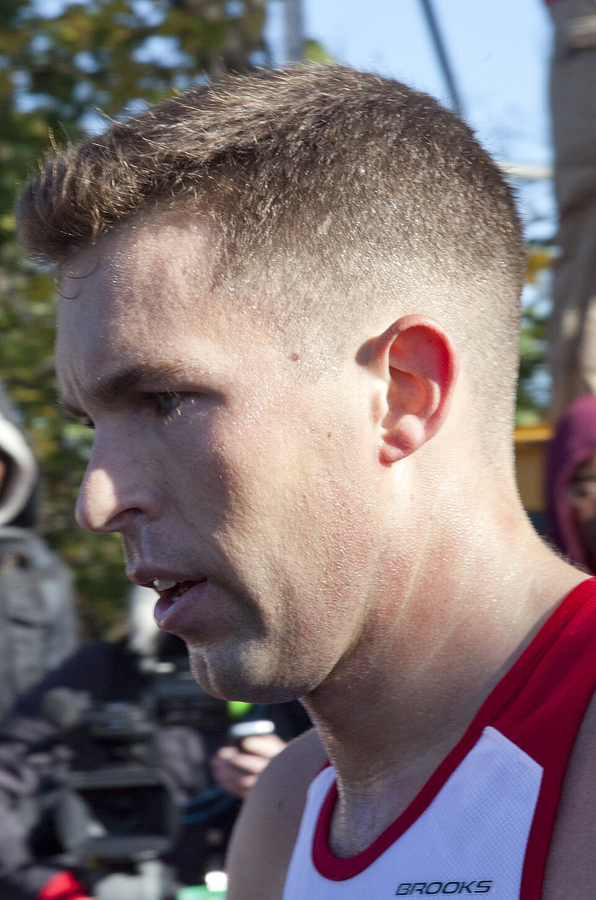

SUCCESS: H001 reference image and metadata saved.
/content/drive/MyDrive/Nimesha_Component3/training_data/style_reference_candidates_v1/H001/crew_cut_reference.jpg


In [ ]:
from pathlib import Path
from io import BytesIO
import json
import requests
from PIL import Image, ImageOps
from IPython.display import display

ROOT = Path("/content/drive/MyDrive/Nimesha_Component3")
if not ROOT.is_dir():
    raise FileNotFoundError("Mount the correct Google Drive first.")

OUT = ROOT / "training_data" / "style_reference_candidates_v1"
FOLDER = OUT / "H001"
FOLDER.mkdir(parents=True, exist_ok=True)

session = requests.Session()
session.headers["User-Agent"] = "Component3ReferenceReview/1.0"

def checked_get(url, **kwargs):
    response = session.get(url, timeout=60, **kwargs)

    # Respect rate limits without automatic retries
    if response.status_code == 429:
        retry_after = response.headers.get("Retry-After", "not specified")
        raise RuntimeError(
            f"Wikimedia rate limit reached. Retry-After: {retry_after}. "
            "Stop here and try later; do not repeatedly rerun."
        )

    response.raise_for_status()
    return response

def download_crew_reference():
    destination = FOLDER / "crew_cut_reference.jpg"

    # Reuse a valid existing download
    if destination.exists():
        with Image.open(destination) as existing:
            existing.load()
            display(existing.copy())
        print("Using existing image:", destination)
        return

    response = checked_get(
        "https://commons.wikimedia.org/w/api.php",
        params={
            "action": "query",
            "format": "json",
            "titles": "File:Crew Cut, Semi Short Taper.jpg",
            "prop": "imageinfo",
            "iiprop": "url|mime|extmetadata",
            "iiurlwidth": 640,
        },
    )
    payload = response.json()

    if "error" in payload:
        raise RuntimeError(str(payload["error"]))

    pages = payload.get("query", {}).get("pages", {})
    matches = [
        page["imageinfo"][0]
        for page in pages.values()
        if page.get("imageinfo")
    ]

    if not matches:
        raise RuntimeError(f"No image information returned: {payload}")

    info = matches[0]

    # Validate MIME type instead of checking the URL ending
    if info.get("mime") not in {"image/jpeg", "image/png"}:
        raise RuntimeError(f"Unexpected image type: {info.get('mime')}")

    image_response = checked_get(info.get("thumburl") or info["url"])

    with Image.open(BytesIO(image_response.content)) as source:
        picture = ImageOps.exif_transpose(source).convert("RGB")
        picture.thumbnail((900, 900))
        picture.save(destination, quality=90)

    # Preserve source and license information alongside the image
    metadata = {
        "style_id": "H001",
        "style_name": "Crew cut",
        "image_path": str(destination),
        "source_page": info.get("descriptionurl"),
        "source_image": info["url"],
        "license_metadata": info.get("extmetadata", {}),
        "attributes": {
            "top_length": "short",
            "sides_length": "very_short",
            "sides_finish": "tapered",
        },
        "annotation_source": "assistant_visual_estimate",
        "expert_validated": False,
        "changes": "Resized and converted to JPEG",
    }

    (FOLDER / "crew_cut_reference_metadata.json").write_text(
        json.dumps(metadata, ensure_ascii=False, indent=2),
        encoding="utf-8",
    )

    display(picture)
    print("SUCCESS: H001 reference image and metadata saved.")
    print(destination)

download_crew_reference()

H002: searching for Textured crop...
  Saved: 0 | Search results: 0 | Filtered: 0
H003: searching for Side part...
  Saved: 2 | Search results: 8 | Filtered: 1
H004: searching for Layered cut...
  Saved: 1 | Search results: 1 | Filtered: 0
B001: searching for Clean shaven...
  Saved: 2 | Search results: 8 | Filtered: 0
B002: searching for Short stubble...
  Saved: 2 | Search results: 8 | Filtered: 0
B003: searching for Short boxed beard...
  Saved: 2 | Search results: 8 | Filtered: 0
B004: searching for Goatee...
  Saved: 2 | Search results: 8 | Filtered: 1
G001: searching for Eyebrow shaping...
  Saved: 0 | Search results: 0 | Filtered: 0
G002: searching for Natural eyebrow style...
  Saved: 1 | Search results: 5 | Filtered: 4
G003: searching for Light cheek grooming...
  Saved: 0 | Search results: 0 | Filtered: 0
G004: searching for Defined cheek grooming...
  Saved: 1 | Search results: 8 | Filtered: 7


,style_id,style_name,candidate_count,status
0,H002,Textured crop,0,Still missing
1,H003,Side part,2,Pending visual review
2,H004,Layered cut,1,Pending visual review
3,B001,Clean shaven,2,Pending visual review
4,B002,Short stubble,2,Pending visual review
5,B003,Short boxed beard,2,Pending visual review
6,B004,Goatee,2,Pending visual review
7,G001,Eyebrow shaping,0,Still missing
8,G002,Natural eyebrow style,1,Pending visual review
9,G003,Light cheek grooming,0,Still missing


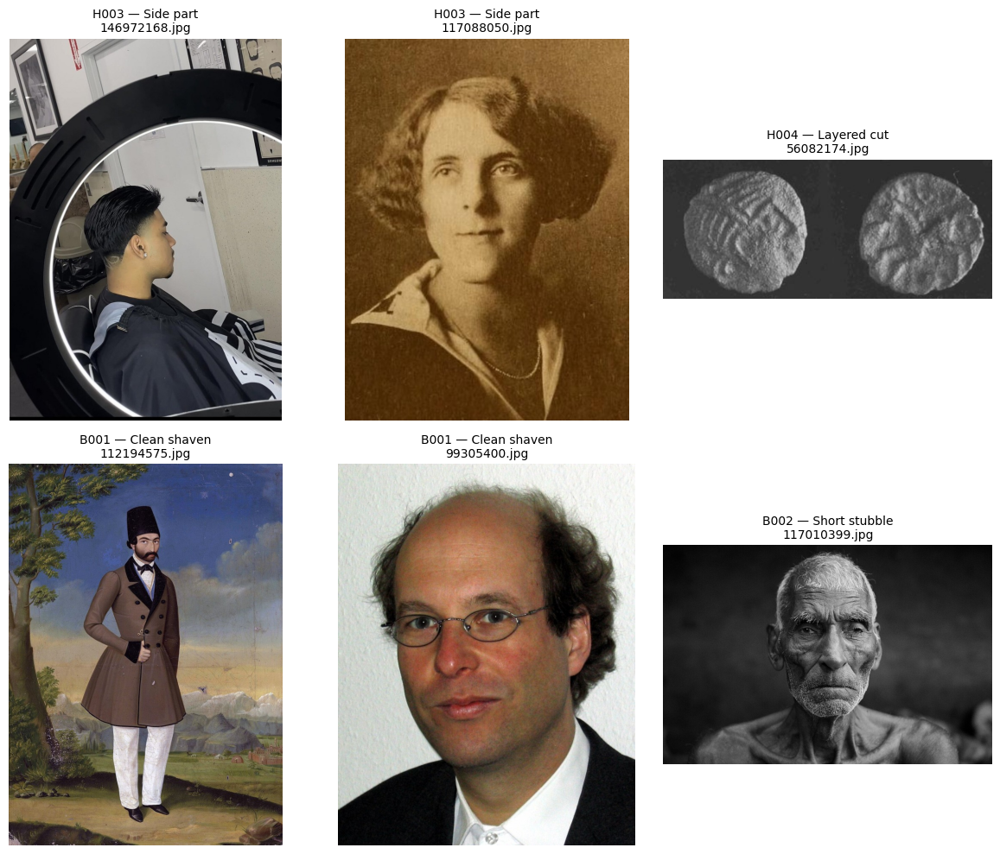

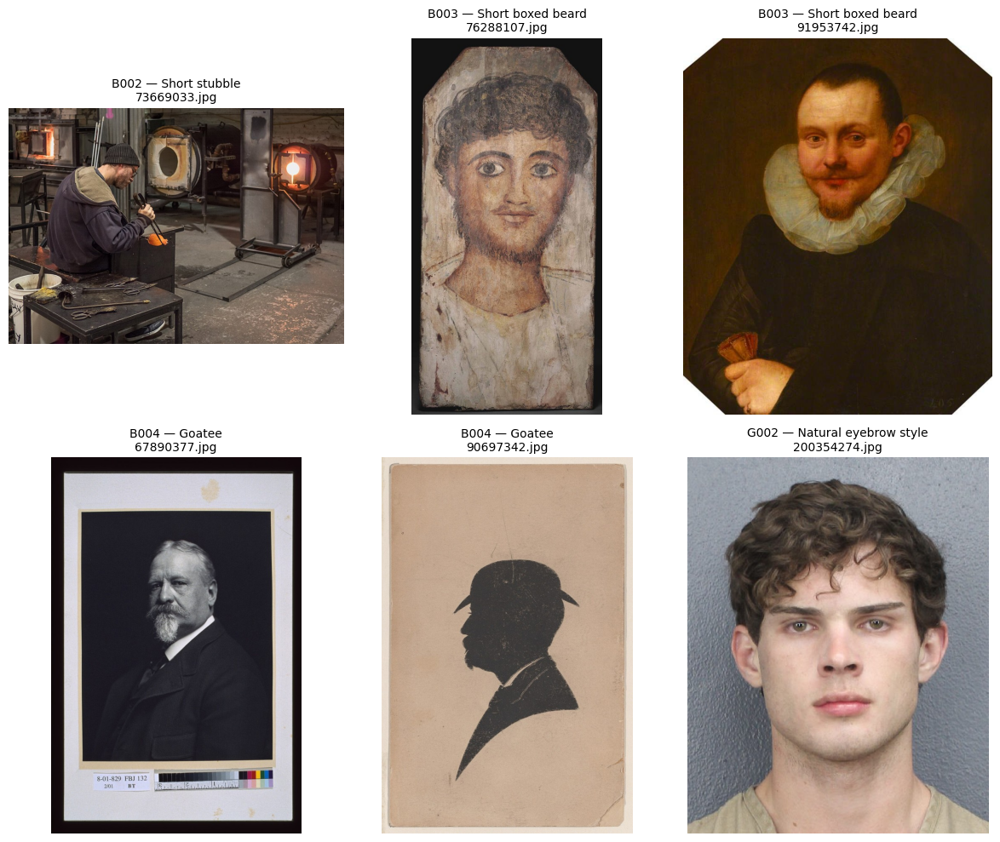

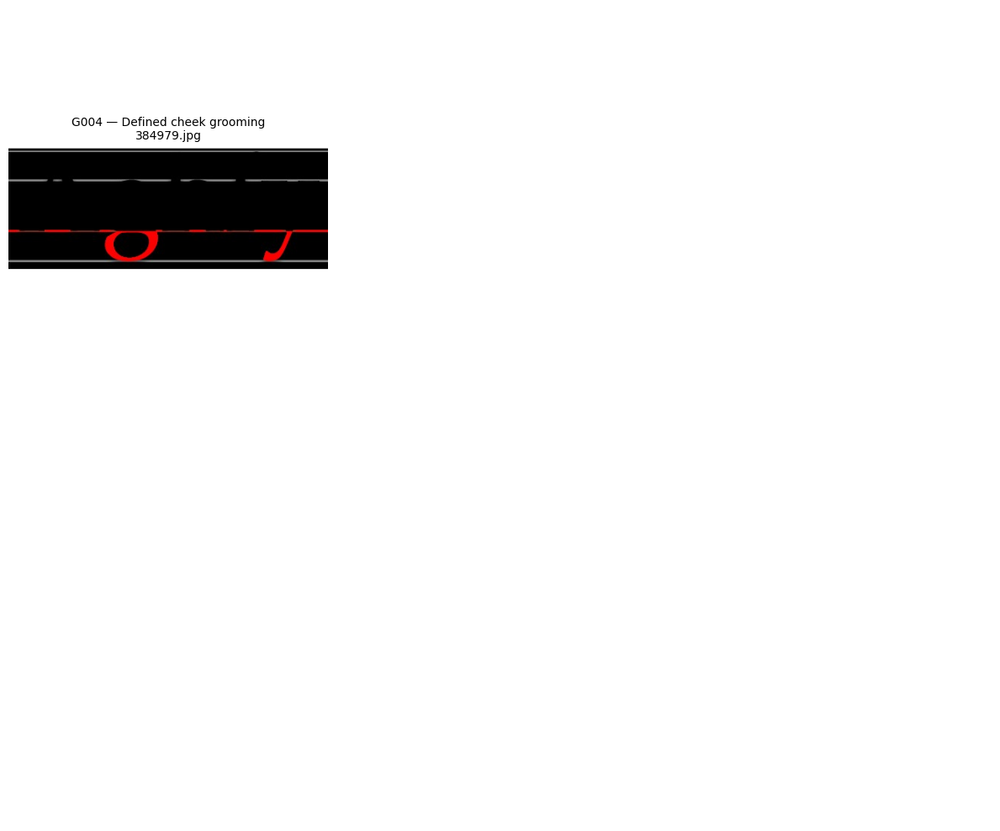

Saved folder: /content/drive/MyDrive/Nimesha_Component3/training_data/style_reference_candidates_v1


In [ ]:
from pathlib import Path
from io import BytesIO
import json
import time
import requests
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

ROOT = Path("/content/drive/MyDrive/Nimesha_Component3")
if not ROOT.is_dir():
    raise FileNotFoundError("Mount the correct Google Drive first.")

OUT = ROOT / "training_data" / "style_reference_candidates_v1"
OUT.mkdir(parents=True, exist_ok=True)
MANIFEST = OUT / "remaining_candidates.json"

# These queries find candidates; they do not establish verified labels
STYLES = {
    "H002": ("Textured crop", '"textured crop" haircut'),
    "H003": ("Side part", '"side part" hairstyle'),
    "H004": ("Layered cut", '"layered hair"'),
    "B001": ("Clean shaven", '"clean-shaven" portrait'),
    "B002": ("Short stubble", 'stubble portrait'),
    "B003": ("Short boxed beard", '"short beard" portrait'),
    "B004": ("Goatee", 'goatee portrait'),
    "G001": ("Eyebrow shaping", '"eyebrow shaping"'),
    "G002": ("Natural eyebrow style", 'eyebrows closeup'),
    "G003": ("Light cheek grooming", '"beard cheek"'),
    "G004": ("Defined cheek grooming", '"beard line"'),
}

# Resume previously saved candidates
records = json.loads(MANIFEST.read_text()) if MANIFEST.exists() else []
records = [r for r in records if Path(r["image_path"]).is_file()]

session = requests.Session()
session.headers["User-Agent"] = "Component3ReferenceReview/1.0"
API = "https://commons.wikimedia.org/w/api.php"

class RateLimitReached(Exception):
    pass

def get_response(url, **kwargs):
    # Space requests and stop immediately if the service rate-limits them
    time.sleep(2)
    response = session.get(url, timeout=60, **kwargs)
    if response.status_code == 429:
        delay = response.headers.get("Retry-After", "not specified")
        raise RateLimitReached(f"Retry-After: {delay}")
    response.raise_for_status()
    return response

def checkpoint():
    MANIFEST.write_text(
        json.dumps(records, ensure_ascii=False, indent=2),
        encoding="utf-8",
    )

for style_id, (name, query) in STYLES.items():
    existing = [r for r in records if r["style_id"] == style_id]
    if len(existing) >= 2:
        print(f"{style_id}: using saved candidates")
        continue

    print(f"{style_id}: searching for {name}...", flush=True)
    folder = OUT / style_id
    folder.mkdir(exist_ok=True)

    try:
        payload = get_response(API, params={
            "action": "query",
            "format": "json",
            "generator": "search",
            "gsrsearch": query,
            "gsrnamespace": 6,
            "gsrlimit": 8,
            "prop": "imageinfo",
            "iiprop": "url|mime|extmetadata",
            "iiurlwidth": 640,
        }).json()

        if "error" in payload:
            raise RuntimeError(str(payload["error"]))

        pages = sorted(
            payload.get("query", {}).get("pages", {}).values(),
            key=lambda p: p.get("index", 0),
        )
        skipped = 0

        for page in pages:
            if len(existing) >= 2:
                break

            title = page.get("title", "")
            if title == "File:Beard stubble close up.jpg":
                continue

            if any(r["file_title"] == title for r in existing):
                continue

            info_list = page.get("imageinfo", [])
            if not info_list:
                skipped += 1
                continue

            info = info_list[0]
            if info.get("mime") not in {"image/jpeg", "image/png"}:
                skipped += 1
                continue

            meta = info.get("extmetadata", {})
            license_name = meta.get(
                "LicenseShortName", {}
            ).get("value", "")

            if not any(value in license_name.lower()
                       for value in ["cc by", "cc0", "public domain"]):
                skipped += 1
                continue

            image_path = folder / f"{page['pageid']}.jpg"

            try:
                response = get_response(info.get("thumburl") or info["url"])
                with Image.open(BytesIO(response.content)) as source:
                    picture = ImageOps.exif_transpose(source).convert("RGB")
                    picture.thumbnail((900, 900))
                    picture.save(image_path, quality=90)
            except RateLimitReached:
                raise
            except Exception as exc:
                print(f"  Image skipped: {exc}")
                continue

            record = {
                "style_id": style_id,
                "style_name": name,
                "file_title": title,
                "image_path": str(image_path),
                "source_page": info.get("descriptionurl", ""),
                "source_image": info["url"],
                "license_metadata": meta,
                "review_status": "pending_visual_review",
                "attributes": {},
                "expert_validated": False,
                "changes": "Resized and converted to JPEG",
            }
            records.append(record)
            existing.append(record)
            checkpoint()

        print(
            f"  Saved: {len(existing)} | "
            f"Search results: {len(pages)} | Filtered: {skipped}"
        )

    except RateLimitReached as exc:
        print(f"\nStopped because of a rate limit: {exc}")
        print("Progress is saved. Resume later with this same cell.")
        break
    except Exception as exc:
        print(f"  Could not complete {style_id}: {exc}")

checkpoint()

# Show coverage without treating missing styles as completed
summary = []
for style_id, (name, _) in STYLES.items():
    count = sum(r["style_id"] == style_id for r in records)
    summary.append({
        "style_id": style_id,
        "style_name": name,
        "candidate_count": count,
        "status": "Pending visual review" if count else "Still missing",
    })
display(pd.DataFrame(summary))

# Create labelled contact sheets for review
for start in range(0, len(records), 6):
    batch = records[start:start + 6]
    fig, axes = plt.subplots(2, 3, figsize=(12, 10))

    for ax in axes.flat:
        ax.axis("off")

    for ax, record in zip(axes.flat, batch):
        with Image.open(record["image_path"]) as picture:
            ax.imshow(picture)
        ax.set_title(
            f"{record['style_id']} — {record['style_name']}\n"
            f"{Path(record['image_path']).name}",
            fontsize=10,
        )

    plt.tight_layout()
    fig.savefig(
        OUT / f"remaining_contact_sheet_{start // 6 + 1}.jpg",
        dpi=130,
        bbox_inches="tight",
    )
    plt.show()
    plt.close(fig)

print("Saved folder:", OUT)

In [ ]:
from pathlib import Path
import json
import shutil
import pandas as pd

ROOT = Path("/content/drive/MyDrive/Nimesha_Component3")
SOURCE = ROOT / "training_data" / "style_reference_candidates_v1"
DEST = ROOT / "training_data" / "style_images"
MANIFEST = SOURCE / "remaining_candidates.json"

if not MANIFEST.exists():
    raise FileNotFoundError(f"Candidate manifest not found: {MANIFEST}")

records = json.loads(MANIFEST.read_text(encoding="utf-8"))

# Decisions are based on the contact-sheet screenshots
decisions = {
    ("H003", "146972168.jpg"): ("hold", "Parting line not clearly visible"),
    ("H003", "117088050.jpg"): ("reject", "Not selected for this catalogue"),
    ("H004", "56082174.jpg"): ("reject", "Coins, not a hairstyle photograph"),
    ("B001", "112194575.jpg"): ("reject", "Painting with visible facial hair"),
    ("B001", "99305400.jpg"): ("selected_reference", "Clean-shaven appearance"),
    ("B002", "117010399.jpg"): ("selected_reference", "Visible short stubble"),
    ("B002", "73669033.jpg"): ("reject", "Insufficient facial detail"),
    ("B003", "76288107.jpg"): ("reject", "Painting, not a photographic reference"),
    ("B003", "91953742.jpg"): ("reject", "Painting, not a photographic reference"),
    ("B004", "67890377.jpg"): ("hold", "Beard boundaries need closer inspection"),
    ("B004", "90697342.jpg"): ("reject", "Silhouette lacks necessary detail"),
    ("G002", "200354274.jpg"): ("hold", "Grooming history cannot be determined"),
    ("G004", "384979.jpg"): ("reject", "Unrelated diagram"),
}

# Record only visible qualitative attributes, without invented measurements
attributes = {
    ("B001", "99305400.jpg"): {
        "facial_hair_appearance": "clean_shaven",
        "visible_beard": "not_visible",
        "visible_moustache": "not_visible",
    },
    ("B002", "117010399.jpg"): {
        "facial_hair_appearance": "stubble",
        "visible_length_category": "very_short",
        "visible_regions": ["upper_lip", "chin", "jaw"],
    },
}

reviewed = []

for record in records:
    item = dict(record)
    source_path = Path(item["image_path"])
    key = (item["style_id"], source_path.name)

    status, reason = decisions.get(
        key, ("pending_visual_review", "Not reviewed in supplied screenshots")
    )

    item.update({
        "review_status": status,
        "review_reason": reason,
        "review_source": "assistant_review_of_contact_sheet",
        "expert_validated": False,
        "attributes": attributes.get(key, {}),
    })

    if status == "selected_reference":
        if not source_path.is_file():
            item["review_status"] = "selected_but_file_missing"
        else:
            target = DEST / item["style_id"] / source_path.name
            target.parent.mkdir(parents=True, exist_ok=True)
            shutil.copy2(source_path, target)
            item["selected_image_path"] = str(target)

    reviewed.append(item)

# Preserve the original manifest and save the review separately
review_path = SOURCE / "reviewed_candidates_v1.json"
review_path.write_text(
    json.dumps(reviewed, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

display(pd.DataFrame([
    {
        "style_id": r["style_id"],
        "file": Path(r["image_path"]).name,
        "status": r["review_status"],
        "reason": r["review_reason"],
    }
    for r in reviewed
]))

print("Review saved:", review_path)
print("Selected references copied to:", DEST)

,style_id,file,status,reason
0,H003,146972168.jpg,hold,Parting line not clearly visible
1,H003,117088050.jpg,reject,Not selected for this catalogue
2,H004,56082174.jpg,reject,"Coins, not a hairstyle photograph"
3,B001,112194575.jpg,reject,Painting with visible facial hair
4,B001,99305400.jpg,selected_reference,Clean-shaven appearance
5,B002,117010399.jpg,selected_reference,Visible short stubble
6,B002,73669033.jpg,reject,Insufficient facial detail
7,B003,76288107.jpg,reject,"Painting, not a photographic reference"
8,B003,91953742.jpg,reject,"Painting, not a photographic reference"
9,B004,67890377.jpg,hold,Beard boundaries need closer inspection


Review saved: /content/drive/MyDrive/Nimesha_Component3/training_data/style_reference_candidates_v1/reviewed_candidates_v1.json
Selected references copied to: /content/drive/MyDrive/Nimesha_Component3/training_data/style_images


In [ ]:
%pip -q install "transformers>=4.45,<5" safetensors pillow pandas tqdm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 93.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 40.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 126.9 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.29.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [ ]:

from pathlib import Path
import shutil
import zipfile
import json
import hashlib
import torch
from transformers import CLIPModel, CLIPProcessor

ROOT = Path("/content/drive/MyDrive/Nimesha_Component3")
SOURCE_ZIP = ROOT / "raw" / "indicfairface.zip"
OUT = ROOT / "training_data" / "auto_style_labels_v1"

if not SOURCE_ZIP.is_file():
    raise FileNotFoundError(f"Dataset ZIP not found: {SOURCE_ZIP}")

if not torch.cuda.is_available():
    raise RuntimeError("Select a GPU runtime before continuing.")

OUT.mkdir(parents=True, exist_ok=True)

# Read the archive locally to avoid repeated random reads from Drive
LOCAL_ZIP = Path("/content/component3_indicfairface.zip")
if not LOCAL_ZIP.exists() or LOCAL_ZIP.stat().st_size != SOURCE_ZIP.stat().st_size:
    required = SOURCE_ZIP.stat().st_size + 2 * 1024**3
    if shutil.disk_usage("/content").free < required:
        raise RuntimeError("Not enough local disk space to copy the ZIP.")
    print("Copying the ZIP from Drive to Colab...")
    shutil.copy2(SOURCE_ZIP, LOCAL_ZIP)

MODEL_ID = "openai/clip-vit-base-patch32"
processor = CLIPProcessor.from_pretrained(MODEL_ID)
model = CLIPModel.from_pretrained(
    MODEL_ID, use_safetensors=True
).to("cuda").eval()

# These are experimental descriptions, not validated class definitions
PROMPTS = {
    "hair": {
        "H001": "A portrait photo with a crew cut, short upright top hair and very short tapered sides.",
        "H002": "A portrait photo with a textured crop haircut, short choppy top hair and a forward fringe.",
        "H003": "A portrait photo with a side part hairstyle, a visible off-centre part and hair combed to one side.",
        "H004": "A portrait photo with a layered haircut, visibly different lengths of hair forming layers.",
        "other": "A portrait photo with another hairstyle, such as long straight hair, braids, a bun or a shaved head.",
        "not_visible": "A photo where the hairstyle is hidden, cropped out, covered by a hat or too unclear to see.",
        "not_portrait": "A picture of an object, a landscape, a painting or a drawing rather than a clear portrait photograph.",
    },
    "beard": {
        "B001": "A close-up portrait photo with a clean-shaven face, no visible beard and no moustache.",
        "B002": "A close-up portrait photo with very short beard stubble across the chin, jaw and upper lip.",
        "B003": "A close-up portrait photo with a short boxed beard, short facial hair along the cheeks, jaw and chin with trimmed edges.",
        "B004": "A close-up portrait photo with a goatee, facial hair concentrated on the chin and around the mouth with mostly shaved cheeks.",
        "other": "A portrait photo with another facial hair style, such as a long full beard, a moustache alone or long sideburns.",
        "not_visible": "A photo where the mouth, chin and cheeks are hidden, cropped out or too unclear to see.",
        "not_portrait": "A picture of an object, a landscape, a painting or a drawing rather than a clear portrait photograph.",
    },
}

# Heuristic screening thresholds; these are not calibrated confidence levels
MIN_SIMILARITY = 0.25
MIN_MARGIN = 0.025
BATCH_SIZE = 32

config = {
    "model": MODEL_ID,
    "model_revision": getattr(model.config, "_commit_hash", None),
    "prompts": PROMPTS,
    "min_similarity": MIN_SIMILARITY,
    "min_margin": MIN_MARGIN,
    "source_zip_size": SOURCE_ZIP.stat().st_size,
    "source_zip_mtime": SOURCE_ZIP.stat().st_mtime,
}
config_path = OUT / "config.json"

# Prevent mixing results produced using different settings
if config_path.exists():
    if json.loads(config_path.read_text()) != config:
        raise RuntimeError(
            "Settings or dataset changed. Use a new output folder version."
        )
else:
    config_path.write_text(json.dumps(config, indent=2))

text_features = {}
class_names = {}

with torch.inference_mode():
    for task, descriptions in PROMPTS.items():
        class_names[task] = list(descriptions)
        tokens = processor(
            text=list(descriptions.values()),
            padding=True,
            return_tensors="pt",
        ).to("cuda")

        features = model.get_text_features(**tokens)
        text_features[task] = features / features.norm(dim=-1, keepdim=True)

print("GPU:", torch.cuda.get_device_name(0))
print("Output folder:", OUT)
print("Setup complete.")

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

AttributeError: 'BaseModelOutputWithPooling' object has no attribute 'norm'

In [ ]:
import torch
import torch.nn.functional as F
import transformers

print("Transformers version:", transformers.__version__)

def normalize_clip_features(output):
    # Support both tensor outputs and structured CLIP outputs.
    if isinstance(output, torch.Tensor):
        features = output
    elif hasattr(output, "pooler_output"):
        features = output.pooler_output
    else:
        raise TypeError(f"Unsupported CLIP output type: {type(output)}")

    if not isinstance(features, torch.Tensor):
        raise TypeError("CLIP embeddings must be a tensor.")

    return F.normalize(features.float(), p=2, dim=-1)


# Rebuild all text embeddings after the interrupted setup.
model.eval()
device = next(model.parameters()).device

text_features = {}
class_names = {}

with torch.inference_mode():
    for task, descriptions in PROMPTS.items():
        class_names[task] = list(descriptions)

        tokens = processor(
            text=list(descriptions.values()),
            padding=True,
            return_tensors="pt",
        ).to(device)

        output = model.get_text_features(**tokens)
        text_features[task] = normalize_clip_features(output)

        print(f"{task}: {tuple(text_features[task].shape)}")

    # Check image embedding compatibility before processing the dataset.
    image_size = model.config.vision_config.image_size
    test_pixels = torch.zeros(
        1, 3, image_size, image_size,
        device=device,
        dtype=next(model.parameters()).dtype,
    )

    image_output = model.get_image_features(pixel_values=test_pixels)
    test_features = normalize_clip_features(image_output)

    for task, references in text_features.items():
        assert test_features.shape[-1] == references.shape[-1], (
            f"Embedding dimension mismatch: {task}"
        )

print("Text and image embedding checks passed.")
print("Setup complete. Ready for batch processing.")

Transformers version: 5.18.0
hair: (7, 512)
beard: (7, 512)
Text and image embedding checks passed.
Setup complete. Ready for batch processing.


In [ ]:
from pathlib import Path
from io import BytesIO
import hashlib
import json
import zipfile

import pandas as pd
import torch
from PIL import Image, ImageOps
from tqdm.auto import tqdm
from IPython.display import display


# Check that the setup and compatibility fix have been run.
required_variables = [
    "model",
    "processor",
    "text_features",
    "class_names",
    "normalize_clip_features",
    "LOCAL_ZIP",
    "OUT",
    "MIN_SIMILARITY",
    "MIN_MARGIN",
    "BATCH_SIZE",
]

missing = [
    name for name in required_variables
    if name not in globals()
]

if missing:
    raise RuntimeError(
        "Run the setup and compatibility fix cells first. "
        f"Missing variables: {missing}"
    )

if not torch.cuda.is_available():
    raise RuntimeError("Connect to a GPU runtime first.")

LOCAL_ZIP = Path(LOCAL_ZIP)
OUT = Path(OUT)

if not LOCAL_ZIP.is_file():
    raise FileNotFoundError(f"Dataset ZIP not found: {LOCAL_ZIP}")

OUT.mkdir(parents=True, exist_ok=True)

LOG = OUT / "predictions.jsonl"
ERROR_LOG = OUT / "image_errors.jsonl"
CSV_PATH = OUT / "predictions.csv"

device = next(model.parameters()).device

if device.type != "cuda":
    raise RuntimeError("Run the setup cell to load the model on the GPU.")

model.eval()


def read_records(path):
    # Recover complete records from a previous run.
    records = []

    if path.exists():
        with path.open("r", encoding="utf-8") as handle:
            for line in handle:
                if not line.strip():
                    continue

                try:
                    records.append(json.loads(line))
                except json.JSONDecodeError:
                    # Ignore an incomplete record from an interrupted write.
                    continue

    return records


def append_records(path, records):
    if not records:
        return

    with path.open("a", encoding="utf-8") as handle:
        # Separate new records from any interrupted final line.
        handle.write("\n")

        for record in records:
            handle.write(json.dumps(record, ensure_ascii=False) + "\n")

        handle.flush()


def get_source_key(member):
    # Identify each source ZIP entry consistently across reruns.
    value = f"{member.filename}|{member.CRC}|{member.file_size}"
    return hashlib.sha256(value.encode("utf-8")).hexdigest()


completed = {}

for record in read_records(LOG):
    if "source_key" in record:
        completed[record["source_key"]] = record

print("GPU:", torch.cuda.get_device_name(0))
print("Previously completed images:", len(completed))
print("Output folder:", OUT)


def process_batch(batch):
    images = [item["image"] for item in batch]

    inputs = processor(
        images=images,
        return_tensors="pt",
        do_center_crop=False,
    ).to(device)

    with torch.inference_mode():
        # Handle both tensor and structured CLIP outputs.
        features = normalize_clip_features(
            model.get_image_features(**inputs)
        )

        scores = {
            task: (
                features @ references.to(
                    device=features.device,
                    dtype=features.dtype,
                ).T
            ).cpu()
            for task, references in text_features.items()
        }

    records = []

    for index, item in enumerate(batch):
        record = {
            "source_key": item["source_key"],
            "source_member": item["source_member"],
            "image_sha256": item["image_sha256"],
            "label_source": "clip_zero_shot_pseudo_label",
            "expert_validated": False,
            "grooming_status": "not_assigned",
        }

        for task, task_scores in scores.items():
            values, indices = torch.topk(task_scores[index], k=2)

            predicted_class = class_names[task][indices[0].item()]
            similarity = values[0].item()
            margin = (values[0] - values[1]).item()

            accepted = (
                predicted_class not in {
                    "other",
                    "not_visible",
                    "not_portrait",
                }
                and similarity >= MIN_SIMILARITY
                and margin >= MIN_MARGIN
            )

            folder_name = (
                predicted_class if accepted
                else "uncertain_or_other"
            )

            destination = OUT / task / folder_name
            destination.mkdir(parents=True, exist_ok=True)

            image_path = destination / f"{item['image_sha256']}.jpg"

            if not image_path.exists():
                item["image"].save(
                    image_path,
                    format="JPEG",
                    quality=95,
                )

            record[f"{task}_predicted_class"] = predicted_class
            record[f"{task}_folder"] = folder_name
            record[f"{task}_similarity"] = similarity
            record[f"{task}_margin"] = margin
            record[f"{task}_image_path"] = str(image_path)

        records.append(record)

    # Checkpoint after every successful batch.
    append_records(LOG, records)

    for record in records:
        completed[record["source_key"]] = record


extensions = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}
batch = []
read_errors = 0
processed_this_run = 0

with zipfile.ZipFile(LOCAL_ZIP, "r") as archive:
    members = [
        member
        for member in archive.infolist()
        if (
            not member.is_dir()
            and Path(member.filename).suffix.lower() in extensions
            and "__MACOSX" not in Path(member.filename).parts
            and not Path(member.filename).name.startswith("._")
        )
    ]

    source_keys = {
        get_source_key(member) for member in members
    }

    pending_count = sum(
        get_source_key(member) not in completed
        for member in members
    )

    print("Image entries found in ZIP:", len(members))
    print("Images remaining:", pending_count)

    progress = tqdm(
        total=pending_count,
        desc="Processing images",
        unit="image",
    )

    try:
        for member in members:
            source_key = get_source_key(member)

            if source_key in completed:
                continue

            try:
                raw_bytes = archive.read(member)

                image_hash = hashlib.sha256(raw_bytes).hexdigest()

                with Image.open(BytesIO(raw_bytes)) as original:
                    image = ImageOps.exif_transpose(original).convert("RGB")

                    if min(image.size) < 80:
                        raise ValueError(
                            f"Image is too small: {image.size}"
                        )

                    # Preserve the full image without cropping hair or chin.
                    image = ImageOps.pad(
                        image,
                        (448, 448),
                        method=Image.Resampling.LANCZOS,
                        color=(127, 127, 127),
                    )

            except Exception as error:
                read_errors += 1

                append_records(
                    ERROR_LOG,
                    [{
                        "source_key": source_key,
                        "source_member": member.filename,
                        "error": str(error),
                    }],
                )

                progress.update(1)
                continue

            batch.append({
                "source_key": source_key,
                "source_member": member.filename,
                "image_sha256": image_hash,
                "image": image,
            })

            if len(batch) >= BATCH_SIZE:
                process_batch(batch)

                processed_this_run += len(batch)
                progress.update(len(batch))

                for item in batch:
                    item["image"].close()

                batch = []

        if batch:
            process_batch(batch)

            processed_this_run += len(batch)
            progress.update(len(batch))

            for item in batch:
                item["image"].close()

            batch = []

    finally:
        progress.close()


# Export records belonging to the current dataset.
current_records = [
    record
    for key, record in completed.items()
    if key in source_keys
]

df = pd.DataFrame(current_records)

print("\nProcessing finished.")
print("Successfully processed this run:", processed_this_run)
print("Read errors this run:", read_errors)
print("Total completed source entries:", len(df))

if not df.empty:
    df.to_csv(CSV_PATH, index=False)

    print("Unique image byte hashes:", df["image_sha256"].nunique())

    for task in text_features:
        folder_column = f"{task}_folder"

        # Count unique saved files rather than duplicate ZIP entries.
        counts = (
            df.drop_duplicates(
                subset=["image_sha256", folder_column]
            )[folder_column]
            .value_counts()
            .rename_axis("folder")
            .reset_index(name="unique_images")
        )

        print(f"\n{task.upper()} folder counts:")
        display(counts)

    print("\nCSV saved to:", CSV_PATH)
else:
    print("No successful predictions were saved.")

print("Prediction checkpoint:", LOG)
print("Image error log:", ERROR_LOG)
print("Image folders:", OUT)

GPU: Tesla T4
Previously completed images: 0
Output folder: /content/drive/MyDrive/Nimesha_Component3/training_data/auto_style_labels_v1
Image entries found in ZIP: 45039
Images remaining: 45039


Processing images:   0%|          | 0/45039 [00:00<?, ?image/s]

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:3452: DecompressionBombWarning: Image size (108576768 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/PIL/TiffImagePlugin.py:950: UserWarning: Corrupt EXIF data.  Expecting to read 2 bytes but only got 0. 
  warnings.warn(str(msg))



Processing finished.
Successfully processed this run: 44886
Read errors this run: 153
Total completed source entries: 44886
Unique image byte hashes: 32848

HAIR folder counts:


,folder,unique_images
0,uncertain_or_other,32358
1,H004,318
2,H001,95
3,H003,56
4,H002,21



BEARD folder counts:


,folder,unique_images
0,uncertain_or_other,32725
1,B001,120
2,B004,3



CSV saved to: /content/drive/MyDrive/Nimesha_Component3/training_data/auto_style_labels_v1/predictions.csv
Prediction checkpoint: /content/drive/MyDrive/Nimesha_Component3/training_data/auto_style_labels_v1/predictions.jsonl
Image error log: /content/drive/MyDrive/Nimesha_Component3/training_data/auto_style_labels_v1/image_errors.jsonl
Image folders: /content/drive/MyDrive/Nimesha_Component3/training_data/auto_style_labels_v1


In [ ]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display

# Read the saved predictions without running the model again.
output_dir = Path(
    "/content/drive/MyDrive/Nimesha_Component3/"
    "training_data/auto_style_labels_v1"
)

prediction_path = output_dir / "predictions.csv"
config_path = output_dir / "config.json"

if not prediction_path.is_file():
    raise FileNotFoundError(
        "Predictions CSV not found. Mount Google Drive first "
        f"and check this path: {prediction_path}"
    )

df = pd.read_csv(prediction_path)

# Remove exact byte duplicates for this diagnostic.
unique_df = df.drop_duplicates(
    subset="image_sha256"
).copy()

config = json.loads(config_path.read_text())

min_similarity = float(config["min_similarity"])
min_margin = float(config["min_margin"])

print("Source entries:", len(df))
print("Unique image byte hashes:", len(unique_df))
print("Minimum similarity:", min_similarity)
print("Minimum margin:", min_margin)

target_classes = {
    "hair": ["H001", "H002", "H003", "H004"],
    "beard": ["B001", "B002", "B003", "B004"],
}

for task, classes in target_classes.items():
    predicted_col = f"{task}_predicted_class"
    folder_col = f"{task}_folder"
    similarity_col = f"{task}_similarity"
    margin_col = f"{task}_margin"

    print(f"\n{'=' * 45}")
    print(f"{task.upper()} DIAGNOSTIC")
    print(f"{'=' * 45}")

    # Show predictions before threshold filtering.
    print("\nTop predicted classes BEFORE filtering:")
    display(
        unique_df[predicted_col]
        .value_counts(dropna=False)
        .rename_axis("predicted_class")
        .reset_index(name="images")
    )

    is_target = unique_df[predicted_col].isin(classes)
    similarity_ok = unique_df[similarity_col] >= min_similarity
    margin_ok = unique_df[margin_col] >= min_margin

    # Assign mutually exclusive reasons for rejection.
    reasons = pd.Series(
        "non_target_prediction",
        index=unique_df.index,
    )

    reasons.loc[is_target & similarity_ok & margin_ok] = "accepted"
    reasons.loc[is_target & ~similarity_ok & margin_ok] = (
        "similarity_too_low_only"
    )
    reasons.loc[is_target & similarity_ok & ~margin_ok] = (
        "margin_too_low_only"
    )
    reasons.loc[is_target & ~similarity_ok & ~margin_ok] = (
        "both_similarity_and_margin_too_low"
    )

    print("\nFiltering results:")
    display(
        reasons.value_counts()
        .rename_axis("reason")
        .reset_index(name="images")
    )

    # Compare candidate counts with accepted counts per target class.
    summary = pd.DataFrame(index=classes)
    summary.index.name = "class"

    summary["top_predictions"] = (
        unique_df[predicted_col]
        .value_counts()
        .reindex(classes, fill_value=0)
    )

    summary["accepted_images"] = (
        unique_df[folder_col]
        .value_counts()
        .reindex(classes, fill_value=0)
    )

    print("\nTarget class coverage:")
    display(summary)

    print("\nScore distribution for target predictions:")
    display(
        unique_df.loc[
            is_target,
            [similarity_col, margin_col],
        ].describe(
            percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]
        ).round(4)
    )

print("\nDiagnostic complete. No labels or images were changed.")

Source entries: 44886
Unique image byte hashes: 32848
Minimum similarity: 0.25
Minimum margin: 0.025

HAIR DIAGNOSTIC

Top predicted classes BEFORE filtering:


,predicted_class,images
0,not_visible,14114
1,H004,6675
2,H003,5561
3,H001,3590
4,not_portrait,1427
5,other,1129
6,H002,352



Filtering results:


,reason,images
0,non_target_prediction,16670
1,both_similarity_and_margin_too_low,8662
2,margin_too_low_only,6955
3,accepted,490
4,similarity_too_low_only,71



Target class coverage:


...


Target class coverage:


,top_predictions,accepted_images
class,,
B001,2509,120
B002,1173,0
B003,511,0
B004,249,3



Score distribution for target predictions:


,beard_similarity,beard_margin
count,4442.0000,4442.0000
mean,0.2516,0.0080
std,0.0175,0.0071
min,0.1992,0.0000
10%,0.2298,0.0009
25%,0.2392,0.0026
50%,0.2508,0.0059
75%,0.2632,0.0114
90%,0.2744,0.0182
max,0.3175,0.0468



Diagnostic complete. No labels or images were changed.


In [ ]:
from pathlib import Path
import json
import zipfile
import pandas as pd

# Read existing predictions without running CLIP again.
output_dir = Path(
    "/content/drive/MyDrive/Nimesha_Component3/"
    "training_data/auto_style_labels_v1"
)

csv_path = output_dir / "predictions.csv"

if not csv_path.is_file():
    raise FileNotFoundError(
        f"Mount Google Drive and check this file: {csv_path}"
    )

df = pd.read_csv(csv_path).drop_duplicates(
    subset="image_sha256"
).copy()

selected = []

for task in ["hair", "beard"]:
    predicted_col = f"{task}_predicted_class"
    folder_col = f"{task}_folder"

    # Sample each predicted class separately for accepted and rejected images.
    for (predicted_class, folder), group in df.groupby(
        [predicted_col, folder_col]
    ):
        sample = group.sample(
            n=min(4, len(group)),
            random_state=42,
        )

        for _, row in sample.iterrows():
            selected.append({
                "task": task,
                "predicted_class": predicted_class,
                "assigned_folder": folder,
                "similarity": float(row[f"{task}_similarity"]),
                "margin": float(row[f"{task}_margin"]),
                "image_sha256": row["image_sha256"],
                "source_member": row["source_member"],
                "saved_image_path": row[f"{task}_image_path"],
            })

# Create a compact inspection package without changing training folders.
zip_path = output_dir / "label_diagnostic_sample_v1.zip"
manifest = []
missing_files = []

with zipfile.ZipFile(
    zip_path,
    mode="w",
    compression=zipfile.ZIP_DEFLATED,
) as archive:

    for index, record in enumerate(selected, start=1):
        image_path = Path(record["saved_image_path"])

        if not image_path.is_file():
            missing_files.append(str(image_path))
            continue

        archive_name = f"images/sample_{index:03d}.jpg"
        archive.write(image_path, arcname=archive_name)

        manifest.append({
            **record,
            "sample_file": archive_name,
        })

    archive.writestr(
        "sample_predictions.csv",
        pd.DataFrame(manifest).to_csv(index=False),
    )

    config_path = output_dir / "config.json"

    if config_path.is_file():
        archive.write(config_path, arcname="config.json")

    archive.writestr(
        "README.txt",
        "Diagnostic sample of CLIP pseudo-labels.\n"
        "Sampling: up to four images per predicted class and "
        "assigned-folder combination, separately for hair and beard.\n"
        "Predictions are not verified labels.\n"
        "This sample is for error analysis, not an accuracy estimate.\n",
    )

print("Diagnostic ZIP created.")
print("Sample records:", len(manifest))
print("Missing image files:", len(missing_files))
print("ZIP size (MB):", round(zip_path.stat().st_size / 1024**2, 2))
print("Saved to:", zip_path)

if manifest:
    print("\nSample coverage:")
    print(
        pd.DataFrame(manifest)
        .groupby(["task", "predicted_class", "assigned_folder"])
        .size()
        .to_string()
    )

Diagnostic ZIP created.
Sample records: 79
Missing image files: 0
ZIP size (MB): 4.2
Saved to: /content/drive/MyDrive/Nimesha_Component3/training_data/auto_style_labels_v1/label_diagnostic_sample_v1.zip

Sample coverage:
task   predicted_class  assigned_folder   
beard  B001             B001                  4
                        uncertain_or_other    4
       B002             uncertain_or_other    4
       B003             uncertain_or_other    4
       B004             B004                  3
                        uncertain_or_other    4
       not_portrait     uncertain_or_other    4
       not_visible      uncertain_or_other    4
       other            uncertain_or_other    4
hair   H001             H001                  4
                        uncertain_or_other    4
       H002             H002                  4
                        uncertain_or_other    4
       H003             H003                  4
                        uncertain_or_other    4
       H004     

In [ ]:
from pathlib import Path
import shutil
from google.colab import files

# Locate the ZIP created by the previous cell.
source = Path(
    "/content/drive/MyDrive/Nimesha_Component3/"
    "training_data/auto_style_labels_v1/"
    "label_diagnostic_sample_v1.zip"
)

if not source.is_file():
    raise FileNotFoundError(
        "The ZIP is not visible in this Colab session. "
        "Run the diagnostic ZIP creation cell again, "
        "then run this cell."
    )

# Download a local copy without waiting for the Drive web listing.
local_zip = Path("/content/label_diagnostic_sample_v1.zip")
shutil.copy2(source, local_zip)

print("ZIP size (MB):", round(local_zip.stat().st_size / 1024**2, 2))
files.download(str(local_zip))

ZIP size (MB): 4.2


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
%pip -q install catboost==1.2.10 pandas numpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 8.9 MB/s eta 0:00:00


In [ ]:
from google.colab import files
from pathlib import Path
from datetime import datetime, timezone
import zipfile
import subprocess
import sys

uploaded = files.upload()
zip_names = [
    name for name in uploaded
    if name.lower().endswith(".zip")
]

if len(zip_names) != 1:
    raise ValueError("Upload exactly one training package ZIP.")

with zipfile.ZipFile(zip_names[0]) as archive:
    trainer = archive.read("c3_synthetic.py")

# Keep each run separate from previous models.
run_name = datetime.now(timezone.utc).strftime(
    "%Y%m%dT%H%M%S_%fZ"
)

C3_RUN = Path(
    "/content/drive/MyDrive/Nimesha_Component3/"
    "component3_synthetic_v2"
) / run_name

C3_RUN.mkdir(parents=True, exist_ok=False)

C3_SCRIPT = C3_RUN / "c3_synthetic.py"
C3_SCRIPT.write_bytes(trainer)

def run_c3_stage(stage):
    # Run each stage independently of earlier notebook variables.
    subprocess.run(
        [
            sys.executable,
            str(C3_SCRIPT),
            "--stage", stage,
            "--root", str(C3_RUN),
        ],
        check=True,
    )

print("Output folder:", C3_RUN)

Saving Nimesha_Component3_Synthetic_Training_v2.zip to Nimesha_Component3_Synthetic_Training_v2.zip
Output folder: /content/drive/MyDrive/Nimesha_Component3/component3_synthetic_v2/20261008T092609_354596Z


In [ ]:
run_c3_stage("generate")

In [ ]:
run_c3_stage("train")

In [ ]:
run_c3_stage("evaluate")
run_c3_stage("verify")

import json
import pandas as pd
from IPython.display import display

display(pd.read_csv(C3_RUN / "training_summary.csv"))
display(
    pd.read_csv(C3_RUN / "teacher_agreement.csv").round(4)
)

verification = json.loads(
    (C3_RUN / "verification.json").read_text()
)

print("Verification:", verification["status"])
print("Saved models:", C3_RUN / "models")

,category,train_pairs,validation_pairs,trees,reload_verified,label_source
0,hair,8400,1800,292,True,synthetic_rules_v2
1,beard,8400,1800,319,True,synthetic_rules_v2
2,grooming,8400,1800,407,True,synthetic_rules_v2


,category,method,test_profiles,teacher_ndcg_at_3,teacher_top1_agreement,teacher_pairwise_agreement
0,hair,Rules teacher,450,1.0000,1.0000,1.0000
1,hair,Fixed style,450,0.9123,0.1133,0.5256
2,hair,ML,450,0.9999,0.9733,0.9852
3,hair,Hybrid,450,0.9999,0.9778,0.9870
4,hair,ML shuffled profiles,450,0.9037,0.2600,0.5044
5,beard,Rules teacher,450,1.0000,1.0000,1.0000
6,beard,Fixed style,450,0.8975,0.1556,0.5515
7,beard,ML,450,1.0000,0.9889,0.9930
8,beard,Hybrid,450,1.0000,0.9911,0.9937
9,beard,ML shuffled profiles,450,0.8847,0.2311,0.4981


Verification: PASS
Saved models: /content/drive/MyDrive/Nimesha_Component3/component3_synthetic_v2/20261008T092609_354596Z/models


In [ ]:
from pathlib import Path
import json
import shutil
import zipfile
from google.colab import files

# Reuse the successfully verified training run.
if "C3_RUN" not in globals():
    raise RuntimeError(
        "C3_RUN is missing. Restore it to the exact training folder "
        "shown in your previous 'Saved models' output, excluding '/models'."
    )

run_dir = Path(C3_RUN)

required_files = [
    "c3_synthetic.py",
    "config.json",
    "style_catalogue.csv",
    "environment.json",
    "training_summary.csv",
    "teacher_agreement.csv",
    "verification.json",
    "demo_recommendations.json",
    "models/hair_ranker.cbm",
    "models/beard_ranker.cbm",
    "models/grooming_ranker.cbm",
]

missing = [
    name for name in required_files
    if not (run_dir / name).is_file()
]

if missing:
    raise FileNotFoundError(f"Required files are missing: {missing}")

verification = json.loads(
    (run_dir / "verification.json").read_text()
)

if verification.get("status") != "PASS":
    raise RuntimeError("This training run has not passed verification.")

# Package the full run, including data and evaluation evidence.
archive_base = Path("/content") / (
    "Nimesha_Component3_Trained_" + run_dir.name
)

zip_path = Path(
    shutil.make_archive(
        str(archive_base),
        "zip",
        root_dir=run_dir,
    )
)

# Check archive integrity before saving the backup.
with zipfile.ZipFile(zip_path) as archive:
    damaged_file = archive.testzip()
    if damaged_file is not None:
        raise RuntimeError(f"Archive integrity error: {damaged_file}")

drive_zip = run_dir.parent / zip_path.name
shutil.copy2(zip_path, drive_zip)

print("Synthetic prototype training: COMPLETE")
print("Models: hair, beard, grooming")
print("Verification: PASS")
print("Drive backup:", drive_zip)
print("Package size (MB):", round(zip_path.stat().st_size / 1024**2, 2))

files.download(str(zip_path))

Synthetic prototype training: COMPLETE
Models: hair, beard, grooming
Verification: PASS
Drive backup: /content/drive/MyDrive/Nimesha_Component3/component3_synthetic_v2/Nimesha_Component3_Trained_20261008T092609_354596Z.zip
Package size (MB): 1.92


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import drive
from pathlib import Path
from collections import Counter
import os
import csv
import json



# Locate existing dataset folders and relevant metadata files.
root = Path("/content/drive/MyDrive")
image_extensions = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}
keywords = (
    "nimesha", "component3", "component_3", "component 3",
    "dataset", "facial", "face", "profile", "attribute",
    "rating", "label", "feature", "review", "manifest"
)

image_counts = Counter()
metadata_files = []
archive_files = []

for current, directories, filenames in os.walk(root):
    directories[:] = [
        name for name in directories
        if not name.startswith(".") and name != "__pycache__"
    ]

    for filename in filenames:
        path = Path(current) / filename
        extension = path.suffix.lower()

        if extension in image_extensions:
            image_counts[str(path.parent)] += 1

        relevant = any(word in str(path).lower() for word in keywords)

        if relevant and extension == ".csv":
            metadata_files.append(path)
        elif relevant and extension == ".zip":
            archive_files.append(path)

print("IMAGE FOLDERS — largest first")
for folder, count in image_counts.most_common(15):
    print(f"{count:,} images | {folder}")

print("\nRELEVANT CSV FILES — newest first")
metadata_files.sort(key=lambda path: path.stat().st_mtime, reverse=True)

for path in metadata_files[:25]:
    print(f"\nFILE: {path}")
    try:
        # Read column names only; do not expose personal row values.
        with path.open("r", encoding="utf-8-sig", newline="") as handle:
            columns = next(csv.reader(handle), [])
        print("COLUMNS:", json.dumps(columns, ensure_ascii=False))
    except Exception as error:
        print("READ ERROR:", type(error).__name__)

print("\nDATASET ZIP FILES")
for path in sorted(archive_files)[:15]:
    print(path)

print("\nDiscovery complete. No source files were changed.")

IMAGE FOLDERS — largest first
32,358 images | /content/drive/MyDrive/Nimesha_Component3/training_data/auto_style_labels_v1/hair/uncertain_or_other
318 images | /content/drive/MyDrive/Nimesha_Component3/training_data/auto_style_labels_v1/hair/H004
136 images | /content/drive/MyDrive
120 images | /content/drive/MyDrive/Nimesha_Component3/training_data/auto_style_labels_v1/beard/B001
102 images | /content/drive/MyDrive/Drama
95 images | /content/drive/MyDrive/Nimesha_Component3/training_data/auto_style_labels_v1/hair/H001
90 images | /content/drive/MyDrive/My friend 
88 images | /content/drive/MyDrive/Private 
63 images | /content/drive/MyDrive/Dewani Inima 
58 images | /content/drive/MyDrive/My family 
56 images | /content/drive/MyDrive/Nimesha_Component3/training_data/auto_style_labels_v1/hair/H003
51 images | /content/drive/MyDrive/Dansal
43 images | /content/drive/MyDrive/Birthday 
27 images | /content/drive/MyDrive/Last day 
24 images | /content/drive/MyDrive/Id

RELEVANT CSV FILES —

In [ ]:
from pathlib import Path
import pandas as pd
import json

BASE = Path("/content/drive/MyDrive/Nimesha_Component3")

# Use the file locations confirmed in your screenshot.
paths = {
    "profiles": BASE / "training_data/pilot_profiles_v1.csv",
    "geometry": BASE / "training_data/automatic_v1/pilot_geometry_v1.csv",
    "styles": BASE / "training_data/style_catalogue_v1.csv",
    "ratings": BASE / "training_data/pilot_ratings_v1.csv",
}

tables = {}

# Load existing files without changing their contents.
for name, path in paths.items():
    if not path.is_file():
        raise FileNotFoundError(f"Missing {name} file: {path}")
    tables[name] = pd.read_csv(path)

profiles = tables["profiles"]
geometry = tables["geometry"]
styles = tables["styles"]
ratings = tables["ratings"]

# Accept either the existing column name or the requested name.
rating_column = next(
    (name for name in ["rating", "compatibility_rating"]
     if name in ratings.columns),
    None
)

if rating_column is None:
    raise ValueError("No rating column was found in the ratings file.")

numeric_ratings = pd.to_numeric(
    ratings[rating_column], errors="coerce"
)
valid_ratings = numeric_ratings.between(1, 5)

report = {
    "file_rows": {
        name: int(len(table))
        for name, table in tables.items()
    },
    "rating_column": rating_column,
    "ratings_with_numeric_values_1_to_5": int(valid_ratings.sum()),
    "ratings_missing_or_invalid": int((~valid_ratings).sum()),
}

# Check whether profile and style references match the source tables.
for key, source in [
    ("profile_id", profiles),
    ("style_id", styles),
]:
    if key in ratings.columns and key in source.columns:
        known_ids = set(source[key].dropna().astype(str))
        report[f"ratings_with_unknown_{key}"] = int(
            (~ratings[key].astype(str).isin(known_ids)).sum()
        )

# Count duplicate profile-style pairs.
if {"profile_id", "style_id"}.issubset(ratings.columns):
    report["duplicate_profile_style_rows"] = int(
        ratings.duplicated(["profile_id", "style_id"]).sum()
    )

# Summarize existing provenance and processing status.
for name, table in tables.items():
    for column in [
        "label_source", "rating_status", "profile_status",
        "geometry_status", "attribute_source", "catalogue_status"
    ]:
        if column in table.columns:
            counts = (
                table[column].fillna("MISSING")
                .astype(str).value_counts()
            )
            report[f"{name}.{column}"] = {
                key: int(value) for key, value in counts.items()
            }

# Check whether the measured facial ratios are present and numeric.
ratio_columns = [
    "face_length_ratio",
    "jaw_width_ratio",
    "upper_width_ratio",
    "lower_face_ratio",
]

report["geometry_numeric_values"] = {
    column: (
        int(pd.to_numeric(
            geometry[column], errors="coerce"
        ).notna().sum())
        if column in geometry.columns else "COLUMN_MISSING"
    )
    for column in ratio_columns
}

# Check existing categorical attributes without inventing replacements.
report["profile_attribute_values"] = {}
for column in [
    "face_shape", "jawline_shape",
    "hair_texture", "hair_density", "beard_growth_density"
]:
    if column in profiles.columns:
        counts = (
            profiles[column].fillna("MISSING")
            .astype(str).value_counts()
        )
        report["profile_attribute_values"][column] = {
            key: int(value) for key, value in counts.items()
        }

print(json.dumps(report, indent=2, ensure_ascii=False))
print("\nCHECK COMPLETE — original files were not changed.")

{
  "file_rows": {
    "profiles": 100,
    "geometry": 100,
    "styles": 8,
    "ratings": 800
  },
  "rating_column": "compatibility_rating",
  "ratings_with_numeric_values_1_to_5": 0,
  "ratings_missing_or_invalid": 800,
  "ratings_with_unknown_profile_id": 0,
  "ratings_with_unknown_style_id": 0,
  "duplicate_profile_style_rows": 0,
  "profiles.profile_status": {
    "pending": 100
  },
  "profiles.attribute_source": {
    "MISSING": 100
  },
  "geometry.geometry_status": {
    "geometry_proxy_pass": 55,
    "excluded_pose_heuristic": 44,
    "excluded_landmarks": 1
  },
  "geometry.attribute_source": {
    "mediapipe_geometry_proxy_v1": 100
  },
  "styles.catalogue_status": {
    "draft": 8
  },
  "ratings.label_source": {
    "MISSING": 800
  },
  "ratings.rating_status": {
    "pending": 800
  },
  "geometry_numeric_values": {
    "face_length_ratio": 99,
    "jaw_width_ratio": 99,
    "upper_width_ratio": 99,
    "lower_face_ratio": 99
  },
  "profile_attribute_values": {
    

In [ ]:
from pathlib import Path
import pandas as pd

# Read the actual eight styles used by this dataset.
path = Path(
    "/content/drive/MyDrive/Nimesha_Component3/"
    "training_data/style_catalogue_v1.csv"
)

styles = pd.read_csv(path).fillna("")

columns = [
    column for column in
    ["style_id", "category", "style_name", "definition"]
    if column in styles.columns
]

print(styles[columns].to_json(
    orient="records",
    indent=2,
    force_ascii=False
))

[
  {
    "style_id":"H001",
    "category":"hair",
    "style_name":"Crew cut",
    "definition":""
  },
  {
    "style_id":"H002",
    "category":"hair",
    "style_name":"Textured crop",
    "definition":""
  },
  {
    "style_id":"H003",
    "category":"hair",
    "style_name":"Side part",
    "definition":""
  },
  {
    "style_id":"H004",
    "category":"hair",
    "style_name":"Layered cut",
    "definition":""
  },
  {
    "style_id":"B001",
    "category":"beard",
    "style_name":"Clean shaven",
    "definition":""
  },
  {
    "style_id":"B002",
    "category":"beard",
    "style_name":"Short stubble",
    "definition":""
  },
  {
    "style_id":"B003",
    "category":"beard",
    "style_name":"Short boxed beard",
    "definition":""
  },
  {
    "style_id":"B004",
    "category":"beard",
    "style_name":"Goatee",
    "definition":""
  }
]


In [ ]:
from pathlib import Path
from datetime import datetime, timezone
import pandas as pd
import numpy as np
import json
import shutil

BASE = Path("/content/drive/MyDrive/Nimesha_Component3")
SOURCE = BASE / "training_data"

profiles = pd.read_csv(SOURCE / "pilot_profiles_v1.csv")
geometry = pd.read_csv(
    SOURCE / "automatic_v1/pilot_geometry_v1.csv"
)
styles = pd.read_csv(SOURCE / "style_catalogue_v1.csv")

FEATURES = [
    "face_length_ratio",
    "jaw_width_ratio",
    "upper_width_ratio",
    "lower_face_ratio",
]

# Define provisional style descriptions and simulation targets.
# These targets are engineering assumptions, not validated styling advice.
STYLE_RULES = {
    "H001": {
        "definition": "Short hair on top with closely cut sides.",
        "target": [1.45, 0.80, 0.96, 0.43],
    },
    "H002": {
        "definition": "Short textured top with a forward fringe.",
        "target": [1.38, 0.86, 0.95, 0.43],
    },
    "H003": {
        "definition": "Hair styled with a visible side part.",
        "target": [1.25, 0.90, 0.96, 0.44],
    },
    "H004": {
        "definition": "Haircut with multiple lengths or layers.",
        "target": [1.30, 0.76, 0.91, 0.42],
    },
    "B001": {
        "definition": "Beard and moustache hair removed.",
        "target": [1.45, 0.90, 0.95, 0.45],
    },
    "B002": {
        "definition": "Very short visible facial-hair stubble.",
        "target": [1.35, 0.84, 0.95, 0.43],
    },
    "B003": {
        "definition": "Short beard covering the jaw and chin with defined edges.",
        "target": [1.22, 0.78, 0.94, 0.40],
    },
    "B004": {
        "definition": "Facial hair concentrated around the chin and mouth.",
        "target": [1.20, 0.91, 0.95, 0.40],
    },
}

WEIGHTS = np.array([0.35, 0.30, 0.15, 0.20])
SCALES = np.array([0.20, 0.12, 0.10, 0.12])

# Validate source identifiers and required columns.
for name, table in [("profiles", profiles), ("geometry", geometry)]:
    if "profile_id" not in table:
        raise ValueError(f"{name}: profile_id is missing.")
    if table["profile_id"].isna().any():
        raise ValueError(f"{name}: profile_id contains missing values.")
    table["profile_id"] = table["profile_id"].astype(str)
    if table["profile_id"].duplicated().any():
        raise ValueError(f"{name}: duplicate profile IDs found.")

required_geometry = FEATURES + ["geometry_status"]
missing = [c for c in required_geometry if c not in geometry]
if missing:
    raise ValueError(f"Missing geometry columns: {missing}")

if styles["style_id"].isna().any():
    raise ValueError("The catalogue contains missing style IDs.")

styles["style_id"] = styles["style_id"].astype(str)

if styles["style_id"].duplicated().any():
    raise ValueError("The catalogue contains duplicate style IDs.")

if set(styles["style_id"]) != set(STYLE_RULES):
    raise ValueError("The catalogue does not match the confirmed eight styles.")

if not set(geometry["profile_id"]).issubset(set(profiles["profile_id"])):
    raise ValueError("Some geometry records have unknown profile IDs.")

# Keep only records that passed the existing geometry screening.
numeric = geometry[FEATURES].apply(pd.to_numeric, errors="coerce")
valid_numbers = (
    np.isfinite(numeric.to_numpy()).all(axis=1)
    & numeric.gt(0).all(axis=1).to_numpy()
)
screen_pass = geometry["geometry_status"].eq("geometry_proxy_pass")
usable = screen_pass & valid_numbers

selected_geometry = geometry.loc[usable].copy()
selected_geometry[FEATURES] = numeric.loc[usable]

if selected_geometry.empty:
    raise ValueError("No usable geometry records remain.")

# Preserve existing profile fields, including missing attributes and status.
# Use the measured ratios from the geometry table.
selected_profiles = profiles.drop(
    columns=FEATURES, errors="ignore"
).merge(
    selected_geometry[["profile_id"] + FEATURES],
    on="profile_id",
    how="inner",
    validate="one_to_one",
)

selected_profiles["geometry_screening"] = "geometry_proxy_pass"

# Retain catalogue provenance and mark new definitions as provisional.
styles["definition"] = styles["style_id"].map(
    lambda sid: STYLE_RULES[sid]["definition"]
)
styles["definition_status"] = "provisional"

# Generate one row for each usable profile and each catalogue style.
pairs = selected_profiles[["profile_id"] + FEATURES].merge(
    styles[["style_id", "category", "style_name"]],
    how="cross",
)

values = pairs[FEATURES].to_numpy(dtype=float)
targets = np.array([
    STYLE_RULES[sid]["target"]
    for sid in pairs["style_id"]
])

# Calculate a deterministic weighted compatibility index.
terms = np.exp(-0.5 * ((values - targets) / SCALES) ** 2)
compatibility = terms @ WEIGHTS

# Map the index to a continuous 1–5 rating.
pairs["rating"] = np.round(1.0 + 4.0 * compatibility, 4)
pairs["query_id"] = (
    pairs["profile_id"] + "_" + pairs["category"].astype(str)
)

assert pairs["rating"].between(1, 5).all()
assert not pairs.duplicated(["profile_id", "style_id"]).any()
assert len(pairs) == len(selected_profiles) * 8

ratings = pairs[
    ["profile_id", "style_id", "category", "query_id", "rating"]
].copy()

# Record excluded profiles without deleting original source data.
excluded = geometry.loc[~usable, ["profile_id", "geometry_status"]].copy()
excluded["exclusion_reason"] = np.where(
    ~screen_pass.loc[excluded.index],
    "geometry_screening_not_passed",
    "invalid_numeric_geometry",
)

# Save into a new timestamped directory.
stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
OUT = BASE / "exports" / f"Component3_Dataset_{stamp}"
OUT.mkdir(parents=True, exist_ok=False)

selected_profiles.to_csv(OUT / "profiles.csv", index=False)
styles.to_csv(OUT / "style_catalogue.csv", index=False)
ratings.to_csv(OUT / "ratings.csv", index=False)
pairs.to_csv(OUT / "training_pairs.csv", index=False)
excluded.to_csv(OUT / "excluded_profiles.csv", index=False)

# Keep label provenance outside the main ratings table.
metadata = {
    "created_at": stamp,
    "scope": ["hair", "beard"],
    "profile_count": len(selected_profiles),
    "style_count": len(styles),
    "rating_count": len(ratings),
    "rating_column": "rating",
    "rating_range": [1, 5],
    "rating_type": "continuous",
    "rating_source": "rule_generated",
    "human_reviewed": False,
    "expert_validated": False,
    "image_review_performed_by_this_cell": False,
    "attribute_source": "existing_mediapipe_geometry_proxy",
    "parameters_status": "illustrative_engineering_assumptions",
    "missing_attributes": "Preserved as missing; not inferred or imputed.",
    "split_status": "Not split; identity and duplicate checks required before evaluation.",
    "limitations": [
        "Geometry screening is not complete image-quality validation.",
        "Labels do not represent observed human preferences.",
        "Four measured ratios are used; other facial attributes are not used.",
        "Hair texture, hair availability and beard availability are not assessed.",
        "Grooming recommendations are not included.",
    ],
}

parameters = {
    "feature_order": FEATURES,
    "weights": WEIGHTS.tolist(),
    "scales": SCALES.tolist(),
    "style_rules": STYLE_RULES,
    "formula": "rating = 1 + 4 * sum(weight * exp(-0.5 * ((value-target)/scale)^2))",
}

for filename, content in [
    ("dataset_metadata.json", metadata),
    ("rating_parameters.json", parameters),
]:
    (OUT / filename).write_text(
        json.dumps(content, indent=2, allow_nan=False),
        encoding="utf-8",
    )

(OUT / "README.txt").write_text(
    "Component 3: provisional hair and beard training dataset.\n"
    "Ratings are rule-generated from existing measured facial ratios.\n"
    "They are not human-reviewed or expert-validated ratings.\n"
    "See dataset_metadata.json and rating_parameters.json for provenance.\n"
    "Check duplicate images and person overlap before splitting for evaluation.\n"
    "Only the four ratio columns and candidate style information are model inputs.\n"
    "Original files were not modified. No models were trained by this cell.\n",
    encoding="utf-8",
)

zip_path = shutil.make_archive(str(OUT), "zip", root_dir=OUT)

print("DATASET EXPORT COMPLETE")
print("Profiles:", len(selected_profiles))
print("Styles:", len(styles))
print("Ratings:", len(ratings))
print("Excluded geometry records:", len(excluded))
print("Folder:", OUT)
print("ZIP:", zip_path)

print("\nRating summary:")
print(
    pairs.groupby(["category", "style_name"])["rating"]
    .agg(["count", "min", "mean", "max"])
    .round(3)
    .to_string()
)

DATASET EXPORT COMPLETE
Profiles: 55
Styles: 8
Ratings: 440
Excluded geometry records: 45
Folder: /content/drive/MyDrive/Nimesha_Component3/exports/Component3_Dataset_20261008T105212_031274Z
ZIP: /content/drive/MyDrive/Nimesha_Component3/exports/Component3_Dataset_20261008T105212_031274Z.zip

Rating summary:
                            count    min   mean    max
category style_name                                   
beard    Clean shaven          55  2.837  3.617  4.605
         Goatee                55  3.837  4.402  4.794
         Short boxed beard     55  3.905  4.617  4.890
         Short stubble         55  3.528  4.233  4.934
hair     Crew cut              55  3.441  3.932  4.715
         Layered cut           55  3.425  4.224  4.740
         Side part             55  3.567  4.349  4.819
         Textured crop         55  3.326  4.066  4.886


In [ ]:
from pathlib import Path
from datetime import datetime, timezone
import pandas as pd
import numpy as np
import json
import shutil

# Use the export that already exists in your Drive.
SOURCE = Path(
    "/content/drive/MyDrive/Nimesha_Component3/exports/"
    "Component3_Dataset_20261008T105212_031274Z"
)

required_files = [
    "profiles.csv",
    "style_catalogue.csv",
    "rating_parameters.json",
    "dataset_metadata.json",
]

for filename in required_files:
    if not (SOURCE / filename).is_file():
        raise FileNotFoundError(SOURCE / filename)

styles = pd.read_csv(SOURCE / "style_catalogue.csv")
previous_parameters = json.loads(
    (SOURCE / "rating_parameters.json").read_text()
)

N_PROFILES = 6000
SEED = 20261008
rng = np.random.default_rng(SEED)

RATIOS = [
    "face_length_ratio",
    "jaw_width_ratio",
    "upper_width_ratio",
    "lower_face_ratio",
]

# All ranges and category mappings are provisional simulation assumptions.
BOUNDS = {
    "face_length_ratio": [1.00, 1.65],
    "jaw_width_ratio": [0.65, 1.02],
    "upper_width_ratio": [0.82, 1.10],
    "lower_face_ratio": [0.32, 0.55],
    "symmetry": [0.00, 1.00],
}

CATEGORIES = {
    "face_shape": [
        "oval", "round", "square", "heart", "oblong", "diamond"
    ],
    "jawline": ["soft", "angular", "rounded"],
    "forehead": ["low", "medium", "high"],
    "hairline": [
        "straight", "rounded", "widows_peak", "receding"
    ],
}

FEATURES = list(BOUNDS) + list(CATEGORIES)

# Each row contains four illustrative preferred categories and a symmetry target.
# These preferences have not been validated by a stylist.
PREFERENCES = {
    "H001": ["oval", "soft", "low", "straight", 0.85],
    "H002": ["oblong", "angular", "high", "receding", 0.65],
    "H003": ["round", "rounded", "medium", "widows_peak", 0.75],
    "H004": ["square", "angular", "high", "rounded", 0.55],
    "B001": ["oval", "angular", "medium", "straight", 0.90],
    "B002": ["heart", "soft", "high", "rounded", 0.75],
    "B003": ["round", "rounded", "low", "receding", 0.55],
    "B004": ["square", "angular", "medium", "widows_peak", 0.65],
}

# Weights follow this exact term order.
TERM_ORDER = RATIOS + list(CATEGORIES) + ["symmetry"]

WEIGHTS = {
    "hair": [0.16, 0.08, 0.08, 0.05, 0.22, 0.08, 0.12, 0.14, 0.07],
    "beard": [0.12, 0.17, 0.05, 0.12, 0.16, 0.16, 0.05, 0.05, 0.12],
}

RATIO_SCALES = np.array([0.20, 0.12, 0.10, 0.12])
SYMMETRY_SCALE = 0.25

assert styles["style_id"].is_unique
assert set(styles["style_id"]) == set(PREFERENCES)
assert set(styles["category"]) == {"hair", "beard"}
assert all(np.isclose(sum(w), 1.0) for w in WEIGHTS.values())

for sid in PREFERENCES:
    if sid not in previous_parameters["style_rules"]:
        raise ValueError(f"Missing numeric targets for {sid}")

# Generate separate simulation profiles.
profiles = pd.DataFrame({
    "profile_id": [
        f"SIM9_{i:06d}" for i in range(1, N_PROFILES + 1)
    ]
})

# Spread numeric inputs across their provisional support ranges.
for feature, (low, high) in BOUNDS.items():
    unit_values = (
        rng.permutation(N_PROFILES) + rng.random(N_PROFILES)
    ) / N_PROFILES
    profiles[feature] = low + unit_values * (high - low)

# Balance each categorical attribute across the generated dataset.
# Independent sampling does not establish anatomical realism.
for feature, options in CATEGORIES.items():
    values = np.resize(np.array(options), N_PROFILES)
    rng.shuffle(values)
    profiles[feature] = values

# Split profiles before generating candidate-style pairs.
split_values = np.array(
    ["train"] * 4200
    + ["validation"] * 900
    + ["test"] * 900
)
rng.shuffle(split_values)
profiles["split"] = split_values

pairs = profiles.merge(
    styles[["style_id", "category", "style_name"]],
    how="cross",
)

# Compute the four numeric-ratio compatibility terms.
ratio_targets = np.array([
    previous_parameters["style_rules"][sid]["target"]
    for sid in pairs["style_id"]
], dtype=float)

ratio_values = pairs[RATIOS].to_numpy(dtype=float)

terms = [
    np.exp(
        -0.5 * ((ratio_values - ratio_targets) / RATIO_SCALES) ** 2
    )
]

# Add categorical compatibility terms.
for position, feature in enumerate(CATEGORIES):
    preferred = np.array([
        PREFERENCES[sid][position]
        for sid in pairs["style_id"]
    ])
    match_score = np.where(
        pairs[feature].to_numpy() == preferred,
        1.0,
        0.35,
    )
    terms.append(match_score[:, None])

# Add the symmetry compatibility term.
symmetry_targets = np.array([
    PREFERENCES[sid][4]
    for sid in pairs["style_id"]
])

symmetry_term = np.exp(
    -0.5 * (
        (pairs["symmetry"].to_numpy() - symmetry_targets)
        / SYMMETRY_SCALE
    ) ** 2
)
terms.append(symmetry_term[:, None])

all_terms = np.concatenate(terms, axis=1)
row_weights = np.array([
    WEIGHTS[category]
    for category in pairs["category"]
])

compatibility = (all_terms * row_weights).sum(axis=1)

# Use the requested neutral rating column name.
pairs["rating"] = np.round(1.0 + 4.0 * compatibility, 4)
pairs["query_id"] = (
    pairs["profile_id"] + "_" + pairs["category"].astype(str)
)

# Validate the generated dataset.
assert len(profiles) == 6000
assert len(pairs) == 48000
assert not profiles[FEATURES].isna().any().any()
assert not profiles.duplicated(FEATURES).any()
assert pairs["rating"].between(1, 5).all()
assert not pairs.duplicated(["profile_id", "style_id"]).any()
assert pairs.groupby("profile_id")["split"].nunique().eq(1).all()
assert pairs.groupby("query_id").size().eq(4).all()

for feature, options in CATEGORIES.items():
    assert profiles[feature].isin(options).all()

for feature, (low, high) in BOUNDS.items():
    assert profiles[feature].between(low, high).all()

split_ids = {
    split: set(profiles.loc[
        profiles["split"].eq(split), "profile_id"
    ])
    for split in ["train", "validation", "test"]
}

assert not split_ids["train"] & split_ids["validation"]
assert not split_ids["train"] & split_ids["test"]
assert not split_ids["validation"] & split_ids["test"]

# Save to a new folder without overwriting previous work.
stamp = datetime.now(timezone.utc).strftime(
    "%Y%m%dT%H%M%S_%fZ"
)
OUT = SOURCE.parent / f"Component3_9Attributes_{stamp}"
DATA = OUT / "generated_data"
SPLITS = DATA / "splits"

SPLITS.mkdir(parents=True, exist_ok=False)

profiles.to_csv(DATA / "profiles.csv", index=False)
styles.to_csv(DATA / "style_catalogue.csv", index=False)
pairs.to_csv(DATA / "training_pairs.csv", index=False)

pairs[
    ["profile_id", "style_id", "category",
     "query_id", "rating", "split"]
].to_csv(DATA / "ratings.csv", index=False)

for split in ["train", "validation", "test"]:
    pairs.loc[pairs["split"].eq(split)].to_csv(
        SPLITS / f"{split}.csv",
        index=False,
    )

# Preserve the measured pilot without filling its missing attributes.
PILOT = OUT / "measured_pilot"
PILOT.mkdir()

for path in SOURCE.iterdir():
    if path.is_file() and path.suffix.lower() in {
        ".csv", ".json", ".txt"
    }:
        shutil.copy2(path, PILOT / path.name)

schema = {
    "required_numeric": BOUNDS,
    "required_categories": CATEGORIES,
    "model_input_features": FEATURES + ["style_id", "category"],
    "target": "rating",
    "target_range": [1, 5],
    "ranking_group": "query_id",
    "excluded_model_inputs": [
        "profile_id", "query_id", "split", "rating"
    ],
    "definitions": {
        "symmetry": (
            "Provisional normalized symmetry input: "
            "0 lower, 1 higher. No upstream measurement algorithm defined."
        ),
        "forehead": (
            "Provisional relative-height category; "
            "measurement thresholds are not defined."
        ),
        "jawline": (
            "Provisional visual category; "
            "no validated angle thresholds."
        ),
        "hairline": "Provisional visible hairline-shape category.",
        "face_shape": "Provisional six-class face-shape input.",
    },
    "attribute_confidence": None,
    "confidence_status": "not_estimated",
    "integration_note": (
        "Confirm upstream measurement definitions, names and scales "
        "before using actual component outputs."
    ),
}

metadata = {
    "created_at": stamp,
    "seed": SEED,
    "profile_count": len(profiles),
    "rating_count": len(pairs),
    "style_count": len(styles),
    "facial_attribute_count": len(FEATURES),
    "scope": ["hair", "beard"],
    "profile_source": "synthetic_simulation",
    "rating_source": "rule_generated",
    "human_reviewed": False,
    "expert_validated": False,
    "real_image_attributes_extracted_by_this_cell": False,
    "measured_pilot_missing_attributes_filled": False,
    "split_profile_counts": {
        name: len(ids) for name, ids in split_ids.items()
    },
    "limitations": [
        "Generated profiles are not observed people.",
        "Independently sampled attributes may form unrealistic combinations.",
        "Preferences, targets and weights are illustrative assumptions.",
        "Test scores measure agreement with the same rule generator.",
        "Grooming styles and calibrated confidence are not included.",
    ],
}

rating_parameters = {
    "term_order": TERM_ORDER,
    "weights": WEIGHTS,
    "ratio_scales": RATIO_SCALES.tolist(),
    "symmetry_scale": SYMMETRY_SCALE,
    "categorical_match_score": 1.0,
    "categorical_nonmatch_score": 0.35,
    "preference_order": list(CATEGORIES) + ["symmetry"],
    "style_preferences": PREFERENCES,
    "style_ratio_targets": {
        sid: previous_parameters["style_rules"][sid]["target"]
        for sid in PREFERENCES
    },
    "formula": "rating = 1 + 4 * weighted_compatibility",
    "parameter_status": "provisional_unvalidated",
}

for filename, content in [
    ("input_schema.json", schema),
    ("dataset_metadata.json", metadata),
    ("rating_parameters.json", rating_parameters),
]:
    (OUT / filename).write_text(
        json.dumps(content, indent=2, allow_nan=False),
        encoding="utf-8",
    )

(OUT / "README.txt").write_text(
    "Component 3: nine-attribute simulation dataset\n\n"
    "6,000 generated profiles, 8 styles, 48,000 ratings.\n"
    "Scope: hair and beard recommendation experiments.\n"
    "Ratings are rule-generated, not human-reviewed preferences.\n"
    "All nine facial inputs are populated in generated_data only.\n"
    "The measured pilot remains unchanged, including missing attributes.\n\n"
    "Use generated_data/splits for training, validation and testing.\n"
    "Fit preprocessing on training data only.\n"
    "Categorical facial attributes and style identifiers require encoding.\n"
    "Keep complete query groups together for ranking training.\n"
    "Do not use IDs, split or rating as predictive input features.\n"
    "Confidence is not estimated.\n"
    "See input_schema.json and dataset_metadata.json before integration.\n",
    encoding="utf-8",
)

zip_path = shutil.make_archive(
    str(OUT), "zip", root_dir=OUT
)

print("DATASET EXPORT COMPLETE")
print("Generated profiles:", len(profiles))
print("Facial attributes:", len(FEATURES))
print("Missing generated attribute values:",
      int(profiles[FEATURES].isna().sum().sum()))
print("Styles:", len(styles))
print("Ratings:", len(pairs))

print("\nSplit summary:")
print(
    pairs.groupby("split").agg(
        profiles=("profile_id", "nunique"),
        ratings=("rating", "size"),
    ).to_string()
)

print("\nFolder:", OUT)
print("ZIP:", zip_path)
print("\nOriginal measured data was not modified.")

DATASET EXPORT COMPLETE
Generated profiles: 6000
Facial attributes: 9
Missing generated attribute values: 0
Styles: 8
Ratings: 48000

Split summary:
            profiles  ratings
split                        
test             900     7200
train           4200    33600
validation       900     7200

Folder: /content/drive/MyDrive/Nimesha_Component3/exports/Component3_9Attributes_20261008T105912_235276Z
ZIP: /content/drive/MyDrive/Nimesha_Component3/exports/Component3_9Attributes_20261008T105912_235276Z.zip

Original measured data was not modified.


In [ ]:
%pip install -q catboost==1.2.10

In [ ]:
from pathlib import Path
from datetime import datetime, timezone
import json
import numpy as np
import pandas as pd
import catboost
from catboost import CatBoostRanker, CatBoostRegressor, Pool

DATASET = Path(
    "/content/drive/MyDrive/Nimesha_Component3/exports/"
    "Component3_9Attributes_20261008T105912_235276Z"
)

schema = json.loads(
    (DATASET / "input_schema.json").read_text()
)

FEATURES = schema["model_input_features"]
CAT_FEATURES = list(schema["required_categories"]) + [
    "style_id", "category"
]

frames = {
    split: pd.read_csv(
        DATASET / "generated_data/splits" / f"{split}.csv"
    )
    for split in ["train", "validation", "test"]
}

# Check data before training.
for split, frame in frames.items():
    required = FEATURES + ["rating", "query_id", "profile_id", "split"]
    missing = [column for column in required if column not in frame]
    if missing:
        raise ValueError(f"{split}: missing columns {missing}")

    assert frame["split"].eq(split).all()
    assert not frame[FEATURES + ["rating"]].isna().any().any()
    assert frame["rating"].between(1, 5).all()
    assert not frame.duplicated(["profile_id", "style_id"]).any()
    assert frame.groupby("query_id").size().eq(4).all()

    for column in CAT_FEATURES:
        frame[column] = frame[column].astype(str)

    for column in schema["required_numeric"]:
        frame[column] = pd.to_numeric(frame[column], errors="raise")
        assert np.isfinite(frame[column]).all()

# Confirm profile separation across splits.
ids = {
    split: set(frame["profile_id"])
    for split, frame in frames.items()
}
assert not ids["train"] & ids["validation"]
assert not ids["train"] & ids["test"]
assert not ids["validation"] & ids["test"]

# Prevent accidental target leakage.
assert not set(FEATURES) & {
    "rating", "profile_id", "query_id", "split"
}

# Create a separate model run.
stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
RUN = DATASET.parent.parent / "model_runs" / f"Component3_{stamp}"
MODELS = RUN / "models"
MODELS.mkdir(parents=True, exist_ok=False)

print("DATA CHECKS PASSED")
print("Model inputs:", FEATURES)
print("Categorical inputs:", CAT_FEATURES)
print("Model output folder:", RUN)

for split, frame in frames.items():
    print(
        split,
        "| profiles:", frame["profile_id"].nunique(),
        "| rows:", len(frame)
    )

DATA CHECKS PASSED
Model inputs: ['face_length_ratio', 'jaw_width_ratio', 'upper_width_ratio', 'lower_face_ratio', 'symmetry', 'face_shape', 'jawline', 'forehead', 'hairline', 'style_id', 'category']
Categorical inputs: ['face_shape', 'jawline', 'forehead', 'hairline', 'style_id', 'category']
Model output folder: /content/drive/MyDrive/Nimesha_Component3/model_runs/Component3_20261008T111122_221310Z
train | profiles: 4200 | rows: 33600
validation | profiles: 900 | rows: 7200
test | profiles: 900 | rows: 7200


In [ ]:
training_records = []

def make_ranking_pool(frame):
    # Ranking groups must be contiguous.
    ordered = frame.sort_values(
        ["query_id", "style_id"]
    ).reset_index(drop=True)

    # Map ratings to a 0–1 relevance scale.
    relevance = (ordered["rating"] - 1.0) / 4.0

    return Pool(
        data=ordered[FEATURES],
        label=relevance,
        group_id=ordered["query_id"].astype(str).tolist(),
        cat_features=CAT_FEATURES,
    )

for category in ["hair", "beard"]:
    train_rows = frames["train"].loc[
        frames["train"]["category"].eq(category)
    ].copy()

    validation_rows = frames["validation"].loc[
        frames["validation"]["category"].eq(category)
    ].copy()

    print(f"\nTRAINING: {category.upper()} RANKER")

    model = CatBoostRanker(
        iterations=1000,
        depth=7,
        learning_rate=0.06,
        loss_function="YetiRank",
        eval_metric="NDCG:top=3",
        random_seed=42,
        task_type="CPU",
        thread_count=2,
        allow_writing_files=False,
    )

    model.fit(
        make_ranking_pool(train_rows),
        eval_set=make_ranking_pool(validation_rows),
        early_stopping_rounds=100,
        use_best_model=True,
        verbose=200,
    )

    model_path = MODELS / f"{category}_ranker.cbm"
    model.save_model(str(model_path))

    # Verify that the saved model reproduces predictions.
    reloaded = CatBoostRanker()
    reloaded.load_model(str(model_path))

    np.testing.assert_allclose(
        model.predict(validation_rows[FEATURES]),
        reloaded.predict(validation_rows[FEATURES]),
        rtol=0,
        atol=1e-12,
    )

    training_records.append({
        "model": f"{category}_ranker",
        "training_rows": len(train_rows),
        "validation_rows": len(validation_rows),
        "trees": model.tree_count_,
        "reload_verified": True,
    })

    print("SAVED:", model_path)


TRAINING: HAIR RANKER
Groupwise loss function. OneHotMaxSize set to 10
0:	test: 0.9584464	best: 0.9584464 (0)	total: 123ms	remaining: 2m 3s
200:	test: 0.9998178	best: 0.9998261 (198)	total: 7.44s	remaining: 29.6s
400:	test: 0.9998914	best: 0.9999058 (380)	total: 13.5s	remaining: 20.2s
600:	test: 0.9999185	best: 0.9999228 (594)	total: 21.6s	remaining: 14.3s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 0.9999256699
bestIteration = 642

Shrink model to first 643 iterations.
SAVED: /content/drive/MyDrive/Nimesha_Component3/model_runs/Component3_20261008T111122_221310Z/models/hair_ranker.cbm

TRAINING: BEARD RANKER
Groupwise loss function. OneHotMaxSize set to 10
0:	test: 0.9649987	best: 0.9649987 (0)	total: 33.8ms	remaining: 33.7s
200:	test: 0.9997150	best: 0.9997186 (197)	total: 7.44s	remaining: 29.6s
400:	test: 0.9998479	best: 0.9998559 (390)	total: 13.3s	remaining: 19.9s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 0.9998881164
bestIteration 

In [ ]:
train_rows = frames["train"]
validation_rows = frames["validation"]

scorer = CatBoostRegressor(
    iterations=1200,
    depth=7,
    learning_rate=0.06,
    loss_function="RMSE",
    random_seed=42,
    task_type="CPU",
    thread_count=2,
    allow_writing_files=False,
)

scorer.fit(
    train_rows[FEATURES],
    train_rows["rating"],
    cat_features=CAT_FEATURES,
    eval_set=(
        validation_rows[FEATURES],
        validation_rows["rating"],
    ),
    early_stopping_rounds=100,
    use_best_model=True,
    verbose=200,
)

scorer_path = MODELS / "compatibility_scorer.cbm"
scorer.save_model(str(scorer_path))

reloaded_scorer = CatBoostRegressor()
reloaded_scorer.load_model(str(scorer_path))

np.testing.assert_allclose(
    scorer.predict(validation_rows[FEATURES]),
    reloaded_scorer.predict(validation_rows[FEATURES]),
    rtol=0,
    atol=1e-12,
)

training_records.append({
    "model": "compatibility_scorer",
    "training_rows": len(train_rows),
    "validation_rows": len(validation_rows),
    "trees": scorer.tree_count_,
    "reload_verified": True,
})

summary = pd.DataFrame(training_records)
summary.to_csv(RUN / "training_summary.csv", index=False)

print("THREE MODELS TRAINED AND SAVED")
display(summary)

0:	learn: 0.3957823	test: 0.3943502	best: 0.3943502 (0)	total: 67.8ms	remaining: 1m 21s
200:	learn: 0.0775994	test: 0.0646001	best: 0.0646001 (200)	total: 11.3s	remaining: 56.2s
400:	learn: 0.0551509	test: 0.0413848	best: 0.0413848 (400)	total: 19.8s	remaining: 39.4s
600:	learn: 0.0447207	test: 0.0320264	best: 0.0320264 (600)	total: 30.8s	remaining: 30.7s
800:	learn: 0.0380416	test: 0.0269934	best: 0.0269934 (800)	total: 41.7s	remaining: 20.8s
1000:	learn: 0.0342787	test: 0.0241712	best: 0.0241712 (1000)	total: 51.3s	remaining: 10.2s
1199:	learn: 0.0314378	test: 0.0222946	best: 0.0222946 (1199)	total: 1m 2s	remaining: 0us

bestTest = 0.02229455955
bestIteration = 1199

THREE MODELS TRAINED AND SAVED


,model,training_rows,validation_rows,trees,reload_verified
0,hair_ranker,16800,3600,643,True
1,beard_ranker,16800,3600,495,True
2,compatibility_scorer,33600,7200,1200,True


In [ ]:
import shutil
import hashlib

def ranking_metrics(truth, scores):
    # Compute tie-aware top-choice agreement and NDCG@3.
    truth = np.asarray(truth, dtype=float)
    scores = np.asarray(scores, dtype=float)

    relevance = (truth - 1.0) / 4.0
    gains = 2.0 ** relevance - 1.0

    expected_ordered_gains = []
    for score in np.unique(scores)[::-1]:
        tied_gains = gains[scores == score]
        expected_ordered_gains.extend(
            [float(tied_gains.mean())] * len(tied_gains)
        )

    k = min(3, len(truth))
    discounts = np.log2(np.arange(2, k + 2))

    ideal = np.sum(np.sort(gains)[::-1][:k] / discounts)
    actual = np.sum(
        np.asarray(expected_ordered_gains[:k]) / discounts
    )
    ndcg = actual / ideal if ideal > 0 else 1.0

    predicted_top = scores == scores.max()
    true_top = np.isclose(
        truth, truth.max(), rtol=0, atol=1e-10
    )
    top_agreement = true_top[predicted_top].mean()

    return float(top_agreement), float(ndcg)

evaluation = []
prediction_tables = []

# Reload the scorer from its saved artifact.
scorer = CatBoostRegressor()
scorer.load_model(str(MODELS / "compatibility_scorer.cbm"))

for category in ["hair", "beard"]:
    test = frames["test"].loc[
        frames["test"]["category"].eq(category)
    ].copy()

    train = frames["train"].loc[
        frames["train"]["category"].eq(category)
    ]

    ranker = CatBoostRanker()
    ranker.load_model(str(MODELS / f"{category}_ranker.cbm"))

    test["ranker_prediction"] = ranker.predict(test[FEATURES])
    test["predicted_rating_raw"] = scorer.predict(test[FEATURES])
    test["predicted_rating"] = np.clip(
        test["predicted_rating_raw"], 1, 5
    )

    # Learn a simple profile-independent baseline from training data only.
    baseline = train.groupby("style_id")["rating"].mean()
    test["fixed_style_baseline"] = test["style_id"].map(baseline)

    for method, column in [
        ("ranker", "ranker_prediction"),
        ("scorer", "predicted_rating"),
        ("fixed_style_baseline", "fixed_style_baseline"),
    ]:
        values = np.array([
            ranking_metrics(group["rating"], group[column])
            for _, group in test.groupby("query_id")
        ])

        evaluation.append({
            "category": category,
            "method": method,
            "test_profiles": test["profile_id"].nunique(),
            "top_choice_agreement": float(values[:, 0].mean()),
            "ndcg_at_3": float(values[:, 1].mean()),
        })

    error = test["predicted_rating_raw"] - test["rating"]
    print(
        category,
        "| Raw scorer MAE:", round(float(np.abs(error).mean()), 4),
        "| Raw scorer RMSE:",
        round(float(np.sqrt(np.mean(error ** 2))), 4),
    )

    prediction_tables.append(test)

evaluation = pd.DataFrame(evaluation)
evaluation.to_csv(RUN / "evaluation.csv", index=False)

pd.concat(prediction_tables, ignore_index=True).to_csv(
    RUN / "test_predictions.csv", index=False
)

# Preserve schema and label provenance with the trained models.
for filename in [
    "input_schema.json",
    "dataset_metadata.json",
    "rating_parameters.json",
]:
    shutil.copy2(DATASET / filename, RUN / filename)

shutil.copy2(
    DATASET / "generated_data/style_catalogue.csv",
    RUN / "style_catalogue.csv",
)

run_information = {
    "dataset_path": str(DATASET),
    "model_features": FEATURES,
    "categorical_features": CAT_FEATURES,
    "catboost_version": catboost.__version__,
    "ranker_target": "(rating - 1) / 4",
    "scorer_target": "rating",
    "rating_source": "rule_generated",
    "profile_source": "synthetic_simulation",
    "human_suitability_validated": False,
    "confidence_calibrated": False,
    "model_sha256": {
        path.name: hashlib.sha256(path.read_bytes()).hexdigest()
        for path in MODELS.glob("*.cbm")
    },
}

(RUN / "run_information.json").write_text(
    json.dumps(run_information, indent=2),
    encoding="utf-8",
)

zip_path = shutil.make_archive(
    str(RUN), "zip", root_dir=RUN
)

display(evaluation.round(4))
print("\nMODEL EXPORT COMPLETE")
print("Folder:", RUN)
print("ZIP:", zip_path)

hair | Raw scorer MAE: 0.0181 | Raw scorer RMSE: 0.0229
beard | Raw scorer MAE: 0.0176 | Raw scorer RMSE: 0.0222


,category,method,test_profiles,top_choice_agreement,ndcg_at_3
0,hair,ranker,900,0.9767,0.9999
1,hair,scorer,900,0.9789,0.9999
2,hair,fixed_style_baseline,900,0.2544,0.9169
3,beard,ranker,900,0.9600,0.9999
4,beard,scorer,900,0.9667,0.9998
5,beard,fixed_style_baseline,900,0.3033,0.9281



MODEL EXPORT COMPLETE
Folder: /content/drive/MyDrive/Nimesha_Component3/model_runs/Component3_20261008T111122_221310Z
ZIP: /content/drive/MyDrive/Nimesha_Component3/model_runs/Component3_20261008T111122_221310Z.zip


In [ ]:
from pathlib import Path
from google.colab import files

dataset_zip = Path(
    "/content/drive/MyDrive/Nimesha_Component3/exports/"
    "Component3_9Attributes_20261008T105912_235276Z.zip"
)

if not dataset_zip.is_file():
    raise FileNotFoundError(f"Dataset ZIP not found: {dataset_zip}")

files.download(str(dataset_zip))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from pathlib import Path
from google.colab import files

models_zip = Path(
    "/content/drive/MyDrive/Nimesha_Component3/model_runs/"
    "Component3_20261008T111122_221310Z.zip"
)

if not models_zip.is_file():
    raise FileNotFoundError(f"Models ZIP not found: {models_zip}")

files.download(str(models_zip))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from pathlib import Path
from google.colab import files
import zipfile

RUN = Path(
    "/content/drive/MyDrive/Nimesha_Component3/model_runs/"
    "Component3_20261008T111122_221310Z"
)

result_files = [
    "training_summary.csv",
    "evaluation.csv",
    "test_predictions.csv",
    "run_information.json",
]

# Include metadata needed to interpret the results correctly.
context_files = [
    "dataset_metadata.json",
    "input_schema.json",
    "rating_parameters.json",
    "style_catalogue.csv",
]

# Check all required files before creating the archive.
for filename in result_files + context_files:
    if not (RUN / filename).is_file():
        raise FileNotFoundError(f"Missing file: {RUN / filename}")

zip_path = RUN.parent / f"{RUN.name}_Results.zip"

# Create a results-only archive without model binaries.
with zipfile.ZipFile(
    zip_path, "w", compression=zipfile.ZIP_DEFLATED
) as archive:
    for filename in result_files + context_files:
        archive.write(RUN / filename, arcname=filename)

# Verify archive integrity before downloading.
with zipfile.ZipFile(zip_path, "r") as archive:
    bad_file = archive.testzip()
    if bad_file is not None:
        raise RuntimeError(f"Archive verification failed: {bad_file}")

print("Results ZIP saved:", zip_path)
files.download(str(zip_path))

Results ZIP saved: /content/drive/MyDrive/Nimesha_Component3/model_runs/Component3_20261008T111122_221310Z_Results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import drive
from pathlib import Path
import json
import pandas as pd


# Resume from the completed dataset and model run.
BASE = Path("/content/drive/MyDrive/Nimesha_Component3")

CURRENT_DATASET = BASE / (
    "exports/Component3_9Attributes_20261008T105912_235276Z"
)

CURRENT_MODELS = BASE / (
    "model_runs/Component3_20261008T111122_221310Z"
)

required_paths = [
    CURRENT_DATASET / "generated_data/profiles.csv",
    CURRENT_DATASET / "generated_data/style_catalogue.csv",
    CURRENT_DATASET / "rating_parameters.json",
    CURRENT_DATASET / "input_schema.json",
    CURRENT_MODELS / "models/hair_ranker.cbm",
    CURRENT_MODELS / "models/beard_ranker.cbm",
    CURRENT_MODELS / "models/compatibility_scorer.cbm",
]

for path in required_paths:
    if not path.is_file():
        raise FileNotFoundError(f"Required file not found: {path}")

profiles = pd.read_csv(
    CURRENT_DATASET / "generated_data/profiles.csv"
)
catalogue = pd.read_csv(
    CURRENT_DATASET / "generated_data/style_catalogue.csv"
)
rating_parameters = json.loads(
    (CURRENT_DATASET / "rating_parameters.json").read_text()
)

print("READY TO CONTINUE")
print("Existing profiles:", len(profiles))
print("Existing styles:", len(catalogue))
print("Existing models: hair ranker, beard ranker, compatibility scorer")
print("Next: expand the catalogue and prepare grooming training data.")
print("No existing datasets or models were changed.")

display(catalogue[["style_id", "category", "style_name"]])

READY TO CONTINUE
Existing profiles: 6000
Existing styles: 8
Existing models: hair ranker, beard ranker, compatibility scorer
Next: expand the catalogue and prepare grooming training data.
No existing datasets or models were changed.


,style_id,category,style_name
0,H001,hair,Crew cut
1,H002,hair,Textured crop
2,H003,hair,Side part
3,H004,hair,Layered cut
4,B001,beard,Clean shaven
5,B002,beard,Short stubble
6,B003,beard,Short boxed beard
7,B004,beard,Goatee


In [ ]:
from pathlib import Path
from datetime import datetime, timezone
import pandas as pd
import numpy as np
import json
import copy
import shutil

BASE = Path("/content/drive/MyDrive/Nimesha_Component3")
SOURCE = BASE / (
    "exports/Component3_9Attributes_20261008T105912_235276Z"
)

# Reload saved data so this cell does not depend on runtime variables.
profiles = pd.read_csv(SOURCE / "generated_data/profiles.csv")
catalogue = pd.read_csv(
    SOURCE / "generated_data/style_catalogue.csv"
)

params = json.loads(
    (SOURCE / "rating_parameters.json").read_text()
)
schema = json.loads(
    (SOURCE / "input_schema.json").read_text()
)
metadata = json.loads(
    (SOURCE / "dataset_metadata.json").read_text()
)

RATIOS = [
    "face_length_ratio",
    "jaw_width_ratio",
    "upper_width_ratio",
    "lower_face_ratio",
]
CATEGORICAL = [
    "face_shape", "jawline", "forehead", "hairline"
]
TERMS = RATIOS + CATEGORICAL + ["symmetry"]
FACIAL_FEATURES = RATIOS + ["symmetry"] + CATEGORICAL

assert params["term_order"] == TERMS
assert params["preference_order"] == CATEGORICAL + ["symmetry"]
assert len(profiles) == 6000
assert profiles["profile_id"].is_unique
assert not profiles[FACIAL_FEATURES].isna().any().any()
assert set(catalogue["style_id"]) == {
    "H001", "H002", "H003", "H004",
    "B001", "B002", "B003", "B004",
}

# All new targets and preferences are illustrative assumptions.
# They are not expert-validated styling recommendations.
new_styles = [
    {
        "style_id": "H005",
        "category": "hair",
        "style_name": "Bob cut",
        "definition": "A bob haircut around chin to shoulder length.",
        "targets": [1.40, 0.78, 0.94, 0.43],
        "preferences": ["oblong", "soft", "medium", "straight", 0.75],
    },
    {
        "style_id": "H006",
        "category": "hair",
        "style_name": "Pixie cut",
        "definition": "A short pixie haircut with a shaped top and sides.",
        "targets": [1.32, 0.84, 0.95, 0.42],
        "preferences": ["oval", "angular", "low", "rounded", 0.85],
    },
    {
        "style_id": "H007",
        "category": "hair",
        "style_name": "Shoulder-length layers",
        "definition": "A shoulder-length haircut with graduated layers.",
        "targets": [1.28, 0.87, 0.96, 0.44],
        "preferences": ["square", "angular", "high", "widows_peak", 0.65],
    },
    {
        "style_id": "H008",
        "category": "hair",
        "style_name": "Long layers",
        "definition": "A longer haircut with layers below shoulder level.",
        "targets": [1.24, 0.88, 0.95, 0.43],
        "preferences": ["round", "rounded", "medium", "straight", 0.70],
    },
    {
        "style_id": "G001",
        "category": "grooming",
        "style_name": "Natural brow maintenance",
        "definition": "Maintain the existing eyebrow outline with minimal tidying.",
        "targets": [1.32, 0.82, 0.95, 0.43],
        "preferences": ["oval", "soft", "medium", "rounded", 0.90],
    },
    {
        "style_id": "G002",
        "category": "grooming",
        "style_name": "Straight brow styling",
        "definition": "A predominantly straight eyebrow outline.",
        "targets": [1.48, 0.80, 0.96, 0.44],
        "preferences": ["oblong", "soft", "high", "straight", 0.75],
    },
    {
        "style_id": "G003",
        "category": "grooming",
        "style_name": "Soft-angled brow styling",
        "definition": "An eyebrow outline with a gentle angular arch.",
        "targets": [1.24, 0.88, 0.95, 0.42],
        "preferences": ["round", "rounded", "medium", "widows_peak", 0.65],
    },
    {
        "style_id": "G004",
        "category": "grooming",
        "style_name": "Rounded brow styling",
        "definition": "An eyebrow outline with a softly rounded arch.",
        "targets": [1.30, 0.90, 0.97, 0.43],
        "preferences": ["square", "angular", "low", "receding", 0.70],
    },
]

# Extend the catalogue and rule configuration.
expanded_params = copy.deepcopy(params)

expanded_params["weights"]["grooming"] = [
    0.08, 0.10, 0.08, 0.08,
    0.12, 0.15, 0.13, 0.10, 0.16,
]

for item in new_styles:
    sid = item["style_id"]
    expanded_params["style_ratio_targets"][sid] = item["targets"]
    expanded_params["style_preferences"][sid] = item["preferences"]

new_catalogue_rows = pd.DataFrame([
    {
        key: item[key]
        for key in ["style_id", "category", "style_name", "definition"]
    }
    for item in new_styles
])

catalogue = pd.concat(
    [catalogue, new_catalogue_rows],
    ignore_index=True,
)

catalogue["catalogue_status"] = "provisional"
catalogue["definition_status"] = "provisional"
catalogue["gender_restriction"] = "none"
catalogue["requires_facial_hair"] = catalogue["style_id"].isin(
    ["B002", "B003", "B004"]
)
catalogue["availability_constraints_validated"] = False

assert len(catalogue) == 16
assert catalogue["style_id"].is_unique
assert all(
    np.isclose(sum(weights), 1.0)
    for weights in expanded_params["weights"].values()
)

# Preserve the original profiles and their train/validation/test assignment.
pairs = profiles.merge(
    catalogue[["style_id", "category", "style_name"]],
    how="cross",
)

ratio_targets = np.array([
    expanded_params["style_ratio_targets"][sid]
    for sid in pairs["style_id"]
], dtype=float)

ratio_scales = np.array(expanded_params["ratio_scales"], dtype=float)

terms = [
    np.exp(
        -0.5 * (
            (pairs[RATIOS].to_numpy(float) - ratio_targets)
            / ratio_scales
        ) ** 2
    )
]

for index, feature in enumerate(CATEGORICAL):
    preferred = np.array([
        expanded_params["style_preferences"][sid][index]
        for sid in pairs["style_id"]
    ])
    values = np.where(
        pairs[feature].to_numpy() == preferred,
        expanded_params["categorical_match_score"],
        expanded_params["categorical_nonmatch_score"],
    )
    terms.append(values[:, None])

symmetry_targets = np.array([
    expanded_params["style_preferences"][sid][4]
    for sid in pairs["style_id"]
], dtype=float)

terms.append(
    np.exp(
        -0.5 * (
            (pairs["symmetry"].to_numpy() - symmetry_targets)
            / expanded_params["symmetry_scale"]
        ) ** 2
    )[:, None]
)

term_matrix = np.concatenate(terms, axis=1)
row_weights = np.array([
    expanded_params["weights"][category]
    for category in pairs["category"]
])

pairs["rating"] = np.round(
    1.0 + 4.0 * (term_matrix * row_weights).sum(axis=1),
    4,
)
pairs["query_id"] = (
    pairs["profile_id"] + "_" + pairs["category"]
)

# Confirm that ratings for the original eight styles are unchanged.
old_pairs = pd.read_csv(
    SOURCE / "generated_data/training_pairs.csv"
)
comparison = old_pairs[
    ["profile_id", "style_id", "rating"]
].merge(
    pairs[["profile_id", "style_id", "rating"]],
    on=["profile_id", "style_id"],
    suffixes=("_old", "_new"),
    validate="one_to_one",
)

assert len(comparison) == len(old_pairs)
np.testing.assert_allclose(
    comparison["rating_old"],
    comparison["rating_new"],
    rtol=0,
    atol=1e-8,
)

# Verify generated data and grouping.
assert len(pairs) == 96000
assert pairs["rating"].between(1, 5).all()
assert not pairs.duplicated(["profile_id", "style_id"]).any()
assert pairs.groupby("profile_id")["split"].nunique().eq(1).all()

for category, expected_count in {
    "hair": 8, "beard": 4, "grooming": 4
}.items():
    groups = pairs.loc[
        pairs["category"].eq(category)
    ].groupby("query_id").size()
    assert groups.eq(expected_count).all()

# Save a new dataset version.
stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
EXPANDED_DATASET = BASE / "exports" / f"Component3_AllCategories_{stamp}"
DATA = EXPANDED_DATASET / "generated_data"
SPLITS = DATA / "splits"
SPLITS.mkdir(parents=True, exist_ok=False)

profiles.to_csv(DATA / "profiles.csv", index=False)
catalogue.to_csv(DATA / "style_catalogue.csv", index=False)
pairs.to_csv(DATA / "training_pairs.csv", index=False)
pairs[
    ["profile_id", "style_id", "category", "query_id", "rating", "split"]
].to_csv(DATA / "ratings.csv", index=False)

for split in ["train", "validation", "test"]:
    pairs.loc[pairs["split"].eq(split)].to_csv(
        SPLITS / f"{split}.csv",
        index=False,
    )

metadata.update({
    "created_at": stamp,
    "parent_dataset": str(SOURCE),
    "scope": ["hair", "beard", "grooming"],
    "style_count": 16,
    "rating_count": len(pairs),
    "styles_per_category": {"hair": 8, "beard": 4, "grooming": 4},
    "profile_source": "synthetic_simulation",
    "rating_source": "rule_generated",
    "gender_specific_accuracy_validated": False,
    "expert_validated": False,
    "grooming_catalogue_status": "proposed_eyebrow_style_families",
})

metadata["limitations"] = list(metadata.get("limitations", []))
metadata["limitations"] = [
    text for text in metadata["limitations"]
    if "Grooming styles and calibrated confidence" not in text
]
metadata["limitations"].extend([
    "Grooming targets and preferences are provisional assumptions.",
    "Eyebrow-specific measurements and feasibility are not modeled.",
    "Hair length, texture, density and user preference are not ML inputs.",
    "Gender-specific performance has not been established.",
    "Confidence calibration is not included.",
])

schema["supported_categories"] = ["hair", "beard", "grooming"]
schema["application_controls"] = {
    "requested_categories": "User-selected recommendation categories.",
    "allowed_style_ids": "Candidates permitted by user preferences.",
    "facial_hair_available": "User-supplied availability; do not infer from gender.",
}
schema["controls_are_model_features"] = False

for filename, content in [
    ("dataset_metadata.json", metadata),
    ("rating_parameters.json", expanded_params),
    ("input_schema.json", schema),
]:
    (EXPANDED_DATASET / filename).write_text(
        json.dumps(content, indent=2, allow_nan=False),
        encoding="utf-8",
    )

(EXPANDED_DATASET / "README.txt").write_text(
    "Component 3 expanded prototype dataset.\n"
    "6,000 generated profiles; 8 hair, 4 beard and 4 grooming styles.\n"
    "All ratings are rule-generated, not human-reviewed preferences.\n"
    "Grooming uses proposed eyebrow style families and provisional rules.\n"
    "No image processing or gender-specific validation was performed.\n"
    "Profile splits and original eight-style ratings are preserved.\n"
    "Hair ranking groups now contain eight candidates, not four.\n"
    "Availability and user-preference filters remain application logic.\n"
    "See metadata for limitations and source details.\n",
    encoding="utf-8",
)

zip_path = shutil.make_archive(
    str(EXPANDED_DATASET), "zip", root_dir=EXPANDED_DATASET
)

print("EXPANDED DATASET READY")
print("Profiles:", len(profiles))
print("Styles:", len(catalogue))
print("Ratings:", len(pairs))

print("\nRows by split and category:")
print(pd.crosstab(pairs["split"], pairs["category"]))

print("\nOriginal eight-style ratings: unchanged")
print("Folder:", EXPANDED_DATASET)
print("ZIP:", zip_path)
print("\nNo models were trained or overwritten.")

EXPANDED DATASET READY
Profiles: 6000
Styles: 16
Ratings: 96000

Rows by split and category:
category    beard  grooming   hair
split                             
test         3600      3600   7200
train       16800     16800  33600
validation   3600      3600   7200

Original eight-style ratings: unchanged
Folder: /content/drive/MyDrive/Nimesha_Component3/exports/Component3_AllCategories_20261008T121020_741185Z
ZIP: /content/drive/MyDrive/Nimesha_Component3/exports/Component3_AllCategories_20261008T121020_741185Z.zip

No models were trained or overwritten.


In [ ]:
%pip install -q catboost==1.2.10

In [ ]:
from pathlib import Path
from datetime import datetime, timezone
import json
import shutil
import hashlib
import numpy as np
import pandas as pd
import catboost
from catboost import CatBoostRanker, CatBoostRegressor, Pool

BASE = Path("/content/drive/MyDrive/Nimesha_Component3")

DATASET = BASE / (
    "exports/Component3_AllCategories_20261008T121020_741185Z"
)
OLD_RUN = BASE / (
    "model_runs/Component3_20261008T111122_221310Z"
)

schema = json.loads((DATASET / "input_schema.json").read_text())
FEATURES = schema["model_input_features"]
CAT_FEATURES = list(schema["required_categories"]) + [
    "style_id", "category"
]

catalogue = pd.read_csv(
    DATASET / "generated_data/style_catalogue.csv"
)
candidate_counts = catalogue.groupby("category").size().to_dict()

frames = {
    split: pd.read_csv(
        DATASET / "generated_data/splits" / f"{split}.csv"
    )
    for split in ["train", "validation", "test"]
}

for split, frame in frames.items():
    assert frame["split"].eq(split).all()
    assert not frame[FEATURES + ["rating"]].isna().any().any()
    assert frame["rating"].between(1, 5).all()
    assert not frame.duplicated(["profile_id", "style_id"]).any()
    assert set(frame["category"]) == set(candidate_counts)

    for column in CAT_FEATURES:
        frame[column] = frame[column].astype(str)

    for column in schema["required_numeric"]:
        frame[column] = pd.to_numeric(frame[column], errors="raise")
        assert np.isfinite(frame[column]).all()

    for category, count in candidate_counts.items():
        subset = frame.loc[frame["category"].eq(category)]
        assert subset.groupby("query_id").size().eq(count).all()

ids = {
    split: set(frame["profile_id"])
    for split, frame in frames.items()
}

assert not ids["train"] & ids["validation"]
assert not ids["train"] & ids["test"]
assert not ids["validation"] & ids["test"]
assert not set(FEATURES) & {"rating", "profile_id", "query_id", "split"}

stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
RUN = BASE / "model_runs" / f"Component3_AllCategories_{stamp}"
MODELS = RUN / "models"
MODELS.mkdir(parents=True, exist_ok=False)

training_records = []

print("DATA CHECKS PASSED")
print("Candidates per category:", candidate_counts)
print("New model folder:", RUN)

DATA CHECKS PASSED
Candidates per category: {'beard': 4, 'grooming': 4, 'hair': 8}
New model folder: /content/drive/MyDrive/Nimesha_Component3/model_runs/Component3_AllCategories_20261008T121138_253749Z


In [ ]:
def ranking_pool(frame):
    # Keep all rows of each ranking query together.
    ordered = frame.sort_values(
        ["query_id", "style_id"]
    ).reset_index(drop=True)

    return Pool(
        ordered[FEATURES],
        label=(ordered["rating"] - 1.0) / 4.0,
        group_id=ordered["query_id"].astype(str).tolist(),
        cat_features=CAT_FEATURES,
    )

for category in ["hair", "grooming"]:
    train = frames["train"].loc[
        frames["train"]["category"].eq(category)
    ].copy()

    validation = frames["validation"].loc[
        frames["validation"]["category"].eq(category)
    ].copy()

    print(f"\nTRAINING {category.upper()} RANKER")

    model = CatBoostRanker(
        iterations=1200,
        depth=7,
        learning_rate=0.06,
        loss_function="YetiRank",
        eval_metric="NDCG:top=3",
        random_seed=42,
        task_type="CPU",
        thread_count=2,
        allow_writing_files=False,
    )

    model.fit(
        ranking_pool(train),
        eval_set=ranking_pool(validation),
        early_stopping_rounds=100,
        use_best_model=True,
        verbose=250,
    )

    path = MODELS / f"{category}_ranker.cbm"
    model.save_model(str(path))

    # Verify saved-model predictions.
    loaded = CatBoostRanker()
    loaded.load_model(str(path))

    np.testing.assert_allclose(
        model.predict(validation[FEATURES]),
        loaded.predict(validation[FEATURES]),
        rtol=0,
        atol=1e-12,
    )

    training_records.append({
        "model": f"{category}_ranker",
        "action": "trained",
        "training_rows": len(train),
        "validation_rows": len(validation),
        "trees": model.tree_count_,
        "reload_verified": True,
    })

    print("SAVED:", path)


TRAINING HAIR RANKER
Groupwise loss function. OneHotMaxSize set to 10
0:	test: 0.8717068	best: 0.8717068 (0)	total: 120ms	remaining: 2m 23s
250:	test: 0.9994583	best: 0.9994715 (246)	total: 21.4s	remaining: 1m 21s
500:	test: 0.9997656	best: 0.9997656 (500)	total: 40s	remaining: 55.8s
750:	test: 0.9998222	best: 0.9998319 (745)	total: 57.9s	remaining: 34.6s
1000:	test: 0.9998806	best: 0.9998806 (1000)	total: 1m 16s	remaining: 15.1s
Stopped by overfitting detector  (100 iterations wait)

bestTest = 0.9998936784
bestIteration = 1098

Shrink model to first 1099 iterations.
SAVED: /content/drive/MyDrive/Nimesha_Component3/model_runs/Component3_AllCategories_20261008T121138_253749Z/models/hair_ranker.cbm

TRAINING GROOMING RANKER
Groupwise loss function. OneHotMaxSize set to 10
0:	test: 0.9813769	best: 0.9813769 (0)	total: 53.9ms	remaining: 1m 4s
250:	test: 0.9997979	best: 0.9998027 (248)	total: 9.17s	remaining: 34.7s
500:	test: 0.9999065	best: 0.9999094 (494)	total: 17.9s	remaining: 25s
750

In [ ]:
# Verify that beard training and validation data are unchanged.
old_info = json.loads(
    (OLD_RUN / "run_information.json").read_text()
)
OLD_DATASET = Path(old_info["dataset_path"])

comparison_columns = FEATURES + [
    "profile_id", "query_id", "rating", "split"
]

for split in ["train", "validation"]:
    old = pd.read_csv(
        OLD_DATASET / "generated_data/splits" / f"{split}.csv"
    )
    old = old.loc[old["category"].eq("beard")].copy()

    new = frames[split].loc[
        frames[split]["category"].eq("beard")
    ].copy()

    for column in CAT_FEATURES:
        old[column] = old[column].astype(str)

    old = old.sort_values(
        ["profile_id", "style_id"]
    ).reset_index(drop=True)
    new = new.sort_values(
        ["profile_id", "style_id"]
    ).reset_index(drop=True)

    pd.testing.assert_frame_equal(
        old[comparison_columns],
        new[comparison_columns],
        check_dtype=False,
        check_exact=False,
        rtol=0,
        atol=1e-10,
    )

# Reuse the unchanged beard model.
old_beard_path = OLD_RUN / "models/beard_ranker.cbm"
beard = CatBoostRanker()
beard.load_model(str(old_beard_path))

assert beard.feature_names_ == FEATURES

new_beard_path = MODELS / "beard_ranker.cbm"
shutil.copy2(old_beard_path, new_beard_path)

assert (
    hashlib.sha256(old_beard_path.read_bytes()).hexdigest()
    == hashlib.sha256(new_beard_path.read_bytes()).hexdigest()
)

copied_beard = CatBoostRanker()
copied_beard.load_model(str(new_beard_path))

beard_validation = frames["validation"].loc[
    frames["validation"]["category"].eq("beard")
]
np.testing.assert_allclose(
    beard.predict(beard_validation[FEATURES]),
    copied_beard.predict(beard_validation[FEATURES]),
    rtol=0,
    atol=1e-12,
)

training_records.append({
    "model": "beard_ranker",
    "action": "reused_verified_model",
    "training_rows": 16800,
    "validation_rows": len(beard_validation),
    "trees": beard.tree_count_,
    "reload_verified": True,
})

print("BEARD MODEL VERIFIED AND COPIED")

# Train a shared rating scorer across all three categories.
train = frames["train"]
validation = frames["validation"]

scorer = CatBoostRegressor(
    iterations=1500,
    depth=7,
    learning_rate=0.06,
    loss_function="RMSE",
    random_seed=42,
    task_type="CPU",
    thread_count=2,
    allow_writing_files=False,
)

scorer.fit(
    train[FEATURES],
    train["rating"],
    cat_features=CAT_FEATURES,
    eval_set=(validation[FEATURES], validation["rating"]),
    early_stopping_rounds=100,
    use_best_model=True,
    verbose=300,
)

scorer_path = MODELS / "compatibility_scorer.cbm"
scorer.save_model(str(scorer_path))

loaded_scorer = CatBoostRegressor()
loaded_scorer.load_model(str(scorer_path))

np.testing.assert_allclose(
    scorer.predict(validation[FEATURES]),
    loaded_scorer.predict(validation[FEATURES]),
    rtol=0,
    atol=1e-12,
)

training_records.append({
    "model": "compatibility_scorer",
    "action": "trained",
    "training_rows": len(train),
    "validation_rows": len(validation),
    "trees": scorer.tree_count_,
    "reload_verified": True,
})

summary = pd.DataFrame(training_records)
summary.to_csv(RUN / "training_summary.csv", index=False)

display(summary)
print("FOUR MODEL FILES READY")

BEARD MODEL VERIFIED AND COPIED
0:	learn: 0.3931460	test: 0.3924604	best: 0.3924604 (0)	total: 146ms	remaining: 3m 38s
300:	learn: 0.0703973	test: 0.0542939	best: 0.0542939 (300)	total: 37.2s	remaining: 2m 28s
600:	learn: 0.0530042	test: 0.0368858	best: 0.0368855 (599)	total: 1m 11s	remaining: 1m 46s
900:	learn: 0.0456361	test: 0.0313358	best: 0.0313358 (900)	total: 1m 47s	remaining: 1m 11s
1200:	learn: 0.0403365	test: 0.0278720	best: 0.0278720 (1200)	total: 2m 25s	remaining: 36.2s
1499:	learn: 0.0365532	test: 0.0256153	best: 0.0256153 (1499)	total: 3m 4s	remaining: 0us

bestTest = 0.0256153125
bestIteration = 1499



,model,action,training_rows,validation_rows,trees,reload_verified
0,hair_ranker,trained,33600,7200,1099,True
1,grooming_ranker,trained,16800,3600,906,True
2,beard_ranker,reused_verified_model,16800,3600,495,True
3,compatibility_scorer,trained,67200,14400,1500,True


FOUR MODEL FILES READY


In [ ]:
def ranking_metrics(truth, scores):
    # Calculate expected ranking metrics when predictions contain ties.
    truth = np.asarray(truth, dtype=float)
    scores = np.asarray(scores, dtype=float)
    gains = 2.0 ** ((truth - 1.0) / 4.0) - 1.0

    ordered_gains = []
    for score in np.unique(scores)[::-1]:
        tied = gains[scores == score]
        ordered_gains.extend([float(tied.mean())] * len(tied))

    k = min(3, len(truth))
    discounts = np.log2(np.arange(2, k + 2))
    ideal = np.sum(np.sort(gains)[::-1][:k] / discounts)
    actual = np.sum(np.asarray(ordered_gains[:k]) / discounts)

    top_mask = scores == scores.max()
    best_target = np.isclose(
        truth, truth.max(), rtol=0, atol=1e-10
    )

    return (
        float(best_target[top_mask].mean()),
        float(actual / ideal) if ideal > 0 else 1.0,
    )

scorer = CatBoostRegressor()
scorer.load_model(str(MODELS / "compatibility_scorer.cbm"))

evaluation_rows = []
error_rows = []
predictions = []

for category in ["hair", "beard", "grooming"]:
    test = frames["test"].loc[
        frames["test"]["category"].eq(category)
    ].copy()

    train = frames["train"].loc[
        frames["train"]["category"].eq(category)
    ]

    ranker = CatBoostRanker()
    ranker.load_model(str(MODELS / f"{category}_ranker.cbm"))
    assert ranker.feature_names_ == FEATURES

    test["ranker_prediction"] = ranker.predict(test[FEATURES])
    test["predicted_rating_raw"] = scorer.predict(test[FEATURES])
    test["predicted_rating"] = np.clip(
        test["predicted_rating_raw"], 1, 5
    )

    # Fit the fixed-style baseline using training labels only.
    baseline = train.groupby("style_id")["rating"].mean()
    test["fixed_style_baseline"] = test["style_id"].map(baseline)

    for method, column in [
        ("ranker", "ranker_prediction"),
        ("scorer", "predicted_rating"),
        ("fixed_style_baseline", "fixed_style_baseline"),
    ]:
        results = np.array([
            ranking_metrics(group["rating"], group[column])
            for _, group in test.groupby("query_id")
        ])

        evaluation_rows.append({
            "category": category,
            "method": method,
            "test_profiles": test["profile_id"].nunique(),
            "top_choice_agreement": float(results[:, 0].mean()),
            "ndcg_at_3": float(results[:, 1].mean()),
        })

    error = test["predicted_rating_raw"] - test["rating"]
    error_rows.append({
        "category": category,
        "raw_scorer_mae": float(np.abs(error).mean()),
        "raw_scorer_rmse": float(np.sqrt(np.mean(error ** 2))),
    })
    predictions.append(test)

evaluation = pd.DataFrame(evaluation_rows)
errors = pd.DataFrame(error_rows)

evaluation.to_csv(RUN / "evaluation.csv", index=False)
errors.to_csv(RUN / "scorer_errors.csv", index=False)
pd.concat(predictions, ignore_index=True).to_csv(
    RUN / "test_predictions.csv", index=False
)

# Bundle the matching schema, catalogue and label-generation parameters.
for filename in [
    "input_schema.json",
    "dataset_metadata.json",
    "rating_parameters.json",
]:
    shutil.copy2(DATASET / filename, RUN / filename)

shutil.copy2(
    DATASET / "generated_data/style_catalogue.csv",
    RUN / "style_catalogue.csv",
)

information = {
    "dataset_path": str(DATASET),
    "previous_model_run": str(OLD_RUN),
    "model_features": FEATURES,
    "categorical_features": CAT_FEATURES,
    "catboost_version": catboost.__version__,
    "categories": ["hair", "beard", "grooming"],
    "ranker_target": "(rating - 1) / 4",
    "scorer_target": "rating",
    "beard_model_action": "reused_after_data_and_hash_verification",
    "profile_source": "synthetic_simulation",
    "rating_source": "rule_generated",
    "human_suitability_validated": False,
    "gender_specific_accuracy_validated": False,
    "confidence_calibrated": False,
    "model_sha256": {
        path.name: hashlib.sha256(path.read_bytes()).hexdigest()
        for path in sorted(MODELS.glob("*.cbm"))
    },
}

assert len(information["model_sha256"]) == 4

(RUN / "run_information.json").write_text(
    json.dumps(information, indent=2, allow_nan=False),
    encoding="utf-8",
)

(RUN / "README.txt").write_text(
    "Component 3 model package: hair, beard, grooming and shared scorer.\n"
    "Hair and grooming rankers and the shared scorer were trained in this run.\n"
    "The verified beard ranker was reused from the previous run.\n"
    "Training profiles are generated and target ratings are rule-generated.\n"
    "Evaluation measures agreement with those targets, not human suitability.\n"
    "Grooming options and rules are provisional.\n"
    "Confidence calibration and gender-specific validation are not included.\n"
    "Hybrid filtering, final scoring and explanations require application code.\n",
    encoding="utf-8",
)

zip_path = shutil.make_archive(str(RUN), "zip", root_dir=RUN)

display(evaluation.round(4))
display(errors.round(4))

print("MODEL PACKAGE EXPORTED")
print("Model files:", sorted(information["model_sha256"]))
print("Folder:", RUN)
print("ZIP:", zip_path)

,category,method,test_profiles,top_choice_agreement,ndcg_at_3
0,hair,ranker,900,0.9567,0.9998
1,hair,scorer,900,0.9578,0.9997
2,hair,fixed_style_baseline,900,0.1111,0.8395
3,beard,ranker,900,0.9600,0.9999
4,beard,scorer,900,0.9533,0.9997
5,beard,fixed_style_baseline,900,0.3033,0.9281
6,grooming,ranker,900,0.9622,0.9999
7,grooming,scorer,900,0.9611,0.9997
8,grooming,fixed_style_baseline,900,0.2811,0.9255


,category,raw_scorer_mae,raw_scorer_rmse
0,hair,0.0171,0.0214
1,beard,0.0231,0.0300
2,grooming,0.0225,0.0293


MODEL PACKAGE EXPORTED
Model files: ['beard_ranker.cbm', 'compatibility_scorer.cbm', 'grooming_ranker.cbm', 'hair_ranker.cbm']
Folder: /content/drive/MyDrive/Nimesha_Component3/model_runs/Component3_AllCategories_20261008T121138_253749Z
ZIP: /content/drive/MyDrive/Nimesha_Component3/model_runs/Component3_AllCategories_20261008T121138_253749Z.zip


In [ ]:
MODEL_FEATURES = [
    "face_length_ratio",
    "jaw_width_ratio",
    "upper_width_ratio",
    "lower_face_ratio",
    "symmetry",
    "face_shape",
    "jawline",
    "forehead",
    "hairline",
    "gender",
    "style_id",
    "category",
]

In [ ]:
rng = np.random.default_rng(20261008)

genders = np.resize(
    np.array(["male", "female"]),
    len(profiles)
)
rng.shuffle(genders)

profiles["gender"] = genders

In [ ]:
import numpy as np
import pandas as pd

# Create balanced gender values if the profile table does not have gender yet.
if "gender" not in profiles.columns:
    rng = np.random.default_rng(20261008)

    gender_values = np.resize(
        np.array(["male", "female"]),
        len(profiles)
    )

    rng.shuffle(gender_values)
    profiles["gender"] = gender_values

# Validate gender values.
allowed_genders = {"male", "female"}

if not profiles["gender"].isin(allowed_genders).all():
    raise ValueError(
        "Gender column contains unsupported values."
    )

# Add gender to the expanded profile-style table.
if "gender" not in pairs.columns:
    pairs = pairs.merge(
        profiles[["profile_id", "gender"]],
        on="profile_id",
        how="left",
        validate="many_to_one"
    )

# Check that every pair received a gender value.
if pairs["gender"].isna().any():
    raise ValueError(
        "Some pair rows did not receive a gender value."
    )

# Remove female beard candidates from recommendation/training rows.
pairs = pairs.loc[
    ~(
        pairs["category"].eq("beard")
        & pairs["gender"].eq("female")
    )
].copy()

print("Gender column added successfully.")
print("\nGender distribution:")
print(profiles["gender"].value_counts())

print("\nRows after female-beard filtering:")
print(
    pairs.groupby(["category", "gender"])
    .size()
    .to_string()
)

Gender column added successfully.

Gender distribution:
gender
male      3000
female    3000
Name: count, dtype: int64

Rows after female-beard filtering:
category  gender
beard     male      12000
grooming  female    12000
          male      12000
hair      female    24000
          male      24000


In [ ]:
FEATURES = [
    "face_length_ratio",
    "jaw_width_ratio",
    "upper_width_ratio",
    "lower_face_ratio",
    "symmetry",
    "face_shape",
    "jawline",
    "forehead",
    "hairline",
    "gender",
]

In [ ]:
import numpy as np

# Add balanced gender values to profiles.
if "gender" not in profiles.columns:
    rng = np.random.default_rng(20261008)

    values = np.resize(
        np.array(["male", "female"]),
        len(profiles)
    )
    rng.shuffle(values)

    profiles["gender"] = values

# Attach gender to every profile-style row.
if "gender" not in pairs.columns:
    pairs = pairs.merge(
        profiles[["profile_id", "gender"]],
        on="profile_id",
        how="left",
        validate="many_to_one"
    )

# Remove female beard candidates.
pairs = pairs.loc[
    ~(
        pairs["category"].eq("beard")
        & pairs["gender"].eq("female")
    )
].copy()

# Verify.
assert pairs["gender"].notna().all()
assert not (
    pairs["category"].eq("beard")
    & pairs["gender"].eq("female")
).any()

print("Gender column:", "gender" in profiles.columns)
print("\nProfile gender distribution:")
print(profiles["gender"].value_counts())

print("\nPair rows by category and gender:")
print(
    pairs.groupby(["category", "gender"])
    .size()
    .to_string()
)

Gender column: True

Profile gender distribution:
gender
male      3000
female    3000
Name: count, dtype: int64

Pair rows by category and gender:
category  gender
beard     male      12000
grooming  female    12000
          male      12000
hair      female    24000
          male      24000


In [ ]:
from pathlib import Path
from datetime import datetime, timezone
import numpy as np
import pandas as pd

# Define the complete gender-aware model schema.
PROFILE_FEATURES = [
    "face_length_ratio",
    "jaw_width_ratio",
    "upper_width_ratio",
    "lower_face_ratio",
    "symmetry",
    "face_shape",
    "jawline",
    "forehead",
    "hairline",
    "gender",
]

MODEL_FEATURES = PROFILE_FEATURES + [
    "style_id",
    "category",
]

CAT_FEATURES = [
    "face_shape",
    "jawline",
    "forehead",
    "hairline",
    "gender",
    "style_id",
    "category",
]

# Prepare separate train, validation and test tables.
frames = {
    split: pairs.loc[
        pairs["split"].eq(split)
    ].copy()
    for split in ["train", "validation", "test"]
}

# Validate every model input.
for split, frame in frames.items():
    missing = [
        column for column in MODEL_FEATURES + ["rating", "query_id"]
        if column not in frame.columns
    ]

    if missing:
        raise ValueError(
            f"{split} is missing columns: {missing}"
        )

    if frame[MODEL_FEATURES + ["rating"]].isna().any().any():
        raise ValueError(
            f"{split} contains missing training values."
        )

    for column in CAT_FEATURES:
        frame[column] = frame[column].astype(str)

    for column in [
        "face_length_ratio",
        "jaw_width_ratio",
        "upper_width_ratio",
        "lower_face_ratio",
        "symmetry",
    ]:
        frame[column] = pd.to_numeric(
            frame[column],
            errors="raise"
        )
        assert np.isfinite(frame[column]).all()

    assert frame["rating"].between(1, 5).all()

# Confirm category-specific query group sizes.
expected_groups = {
    "hair": 8,
    "beard": 4,
    "grooming": 4,
}

for split, frame in frames.items():
    for category, expected_count in expected_groups.items():
        category_rows = frame.loc[
            frame["category"].eq(category)
        ]

        group_sizes = category_rows.groupby(
            "query_id"
        ).size()

        assert group_sizes.eq(expected_count).all(), (
            split,
            category,
            group_sizes.value_counts().to_dict(),
        )

# Confirm gender filtering.
assert not (
    pairs["category"].eq("beard")
    & pairs["gender"].eq("female")
).any()

print("GENDER-AWARE DATA CHECK PASSED")
print("Profile features:", PROFILE_FEATURES)
print("Model features:", MODEL_FEATURES)
print("Categorical features:", CAT_FEATURES)

print("\nRows by split and category:")
print(
    pd.crosstab(
        pairs["split"],
        pairs["category"]
    ).to_string()
)

print("\nRows by category and gender:")
print(
    pairs.groupby(["category", "gender"])
    .size()
    .to_string()
)

GENDER-AWARE DATA CHECK PASSED
Profile features: ['face_length_ratio', 'jaw_width_ratio', 'upper_width_ratio', 'lower_face_ratio', 'symmetry', 'face_shape', 'jawline', 'forehead', 'hairline', 'gender']
Model features: ['face_length_ratio', 'jaw_width_ratio', 'upper_width_ratio', 'lower_face_ratio', 'symmetry', 'face_shape', 'jawline', 'forehead', 'hairline', 'gender', 'style_id', 'category']
Categorical features: ['face_shape', 'jawline', 'forehead', 'hairline', 'gender', 'style_id', 'category']

Rows by split and category:
category    beard  grooming   hair
split                             
test         1804      3600   7200
train        8380     16800  33600
validation   1816      3600   7200

Rows by category and gender:
category  gender
beard     male      12000
grooming  female    12000
          male      12000
hair      female    24000
          male      24000


In [ ]:
from pathlib import Path
from datetime import datetime, timezone
import json
import hashlib
import numpy as np
import pandas as pd
import catboost

from catboost import (
    CatBoostRanker,
    CatBoostRegressor,
    Pool,
)

# Create a new independent model run.
BASE = Path("/content/drive/MyDrive/Nimesha_Component3")

stamp = datetime.now(timezone.utc).strftime(
    "%Y%m%dT%H%M%S_%fZ"
)

RUN = BASE / "model_runs" / f"Component3_GenderAware_{stamp}"
MODELS = RUN / "models"
MODELS.mkdir(parents=True, exist_ok=False)

training_records = []

def make_ranking_pool(frame):
    # Keep all candidate styles of each query together.
    ordered = frame.sort_values(
        ["query_id", "style_id"]
    ).reset_index(drop=True)

    relevance = (ordered["rating"] - 1.0) / 4.0

    return Pool(
        data=ordered[MODEL_FEATURES],
        label=relevance,
        group_id=ordered["query_id"].astype(str).tolist(),
        cat_features=CAT_FEATURES,
    )

# Train a separate ranker for each recommendation category.
for category in ["hair", "beard", "grooming"]:
    train_rows = frames["train"].loc[
        frames["train"]["category"].eq(category)
    ].copy()

    validation_rows = frames["validation"].loc[
        frames["validation"]["category"].eq(category)
    ].copy()

    print(f"\nTRAINING GENDER-AWARE {category.upper()} RANKER")

    model = CatBoostRanker(
        iterations=1400,
        depth=7,
        learning_rate=0.06,
        loss_function="YetiRank",
        eval_metric="NDCG:top=3",
        random_seed=42,
        task_type="CPU",
        thread_count=2,
        allow_writing_files=False,
    )

    model.fit(
        make_ranking_pool(train_rows),
        eval_set=make_ranking_pool(validation_rows),
        early_stopping_rounds=120,
        use_best_model=True,
        verbose=300,
    )

    model_path = MODELS / f"{category}_ranker_gender_aware.cbm"
    model.save_model(str(model_path))

    # Verify that reloaded model predictions are identical.
    loaded = CatBoostRanker()
    loaded.load_model(str(model_path))

    validation_ordered = validation_rows.sort_values(
        ["query_id", "style_id"]
    ).reset_index(drop=True)

    np.testing.assert_allclose(
        model.predict(validation_ordered[MODEL_FEATURES]),
        loaded.predict(validation_ordered[MODEL_FEATURES]),
        rtol=0,
        atol=1e-12,
    )

    training_records.append({
        "model": f"{category}_ranker_gender_aware",
        "training_rows": len(train_rows),
        "validation_rows": len(validation_rows),
        "trees": model.tree_count_,
        "gender_feature_used": True,
        "reload_verified": True,
    })

    print("SAVED:", model_path)

# Train one shared compatibility scorer using all categories.
train_rows = frames["train"].copy()
validation_rows = frames["validation"].copy()

print("\nTRAINING GENDER-AWARE COMPATIBILITY SCORER")

scorer = CatBoostRegressor(
    iterations=1600,
    depth=7,
    learning_rate=0.06,
    loss_function="RMSE",
    random_seed=42,
    task_type="CPU",
    thread_count=2,
    allow_writing_files=False,
)

scorer.fit(
    train_rows[MODEL_FEATURES],
    train_rows["rating"],
    cat_features=CAT_FEATURES,
    eval_set=(
        validation_rows[MODEL_FEATURES],
        validation_rows["rating"],
    ),
    early_stopping_rounds=120,
    use_best_model=True,
    verbose=300,
)

scorer_path = MODELS / "compatibility_scorer_gender_aware.cbm"
scorer.save_model(str(scorer_path))

loaded_scorer = CatBoostRegressor()
loaded_scorer.load_model(str(scorer_path))

np.testing.assert_allclose(
    scorer.predict(validation_rows[MODEL_FEATURES]),
    loaded_scorer.predict(validation_rows[MODEL_FEATURES]),
    rtol=0,
    atol=1e-12,
)

training_records.append({
    "model": "compatibility_scorer_gender_aware",
    "training_rows": len(train_rows),
    "validation_rows": len(validation_rows),
    "trees": scorer.tree_count_,
    "gender_feature_used": True,
    "reload_verified": True,
})

summary = pd.DataFrame(training_records)
summary.to_csv(RUN / "training_summary.csv", index=False)

# Save the exact schema used for this gender-aware run.
run_schema = {
    "profile_features": PROFILE_FEATURES,
    "model_features": MODEL_FEATURES,
    "categorical_features": CAT_FEATURES,
    "categories": ["hair", "beard", "grooming"],
    "gender_values": ["male", "female"],
    "female_beard_rows_removed": True,
    "rating_column": "rating",
    "ranking_group": "query_id",
    "gender_feature_used": True,
    "profile_source": "balanced_generated_profiles",
    "rating_source": "rule_generated",
    "confidence_calibrated": False,
}

(RUN / "gender_aware_schema.json").write_text(
    json.dumps(run_schema, indent=2),
    encoding="utf-8",
)

run_info = {
    "run_folder": str(RUN),
    "catboost_version": catboost.__version__,
    "model_count": 4,
    "gender_feature_used": True,
    "female_beard_rows_removed": True,
    "model_hashes": {
        path.name: hashlib.sha256(path.read_bytes()).hexdigest()
        for path in sorted(MODELS.glob("*.cbm"))
    },
}

(RUN / "run_information.json").write_text(
    json.dumps(run_info, indent=2),
    encoding="utf-8",
)

print("\nGENDER-AWARE TRAINING COMPLETE")
display(summary)
print("Model folder:", MODELS)


TRAINING GENDER-AWARE HAIR RANKER
Groupwise loss function. OneHotMaxSize set to 10
0:	test: 0.8766442	best: 0.8766442 (0)	total: 117ms	remaining: 2m 43s
300:	test: 0.9995827	best: 0.9995827 (300)	total: 38.5s	remaining: 2m 20s
600:	test: 0.9997949	best: 0.9998030 (557)	total: 1m 11s	remaining: 1m 35s
900:	test: 0.9998739	best: 0.9998739 (900)	total: 1m 47s	remaining: 59.6s
1200:	test: 0.9999028	best: 0.9999028 (1199)	total: 2m 17s	remaining: 22.9s
Stopped by overfitting detector  (120 iterations wait)

bestTest = 0.9999028492
bestIteration = 1199

Shrink model to first 1200 iterations.
SAVED: /content/drive/MyDrive/Nimesha_Component3/model_runs/Component3_GenderAware_20261008T123658_164628Z/models/hair_ranker_gender_aware.cbm

TRAINING GENDER-AWARE BEARD RANKER
Groupwise loss function. OneHotMaxSize set to 10
0:	test: 0.9647088	best: 0.9647088 (0)	total: 26.3ms	remaining: 36.8s
300:	test: 0.9997019	best: 0.9997208 (286)	total: 8.28s	remaining: 30.2s
600:	test: 0.9997811	best: 0.999781

,model,training_rows,validation_rows,trees,gender_feature_used,reload_verified
0,hair_ranker_gender_aware,33600,7200,1200,True,True
1,beard_ranker_gender_aware,8380,1816,893,True,True
2,grooming_ranker_gender_aware,16800,3600,596,True,True
3,compatibility_scorer_gender_aware,58780,12616,1600,True,True


Model folder: /content/drive/MyDrive/Nimesha_Component3/model_runs/Component3_GenderAware_20261008T123658_164628Z/models


In [ ]:
import shutil
import json
import numpy as np
import pandas as pd
from catboost import CatBoostRanker, CatBoostRegressor

def ranking_metrics(truth, scores):
    truth = np.asarray(truth, dtype=float)
    scores = np.asarray(scores, dtype=float)

    relevance = (truth - 1.0) / 4.0
    gains = 2.0 ** relevance - 1.0

    ordered_gains = []

    for score in np.unique(scores)[::-1]:
        tied_gains = gains[scores == score]
        ordered_gains.extend(
            [float(tied_gains.mean())] * len(tied_gains)
        )

    k = min(3, len(truth))
    discounts = np.log2(np.arange(2, k + 2))

    ideal = np.sum(
        np.sort(gains)[::-1][:k] / discounts
    )

    actual = np.sum(
        np.asarray(ordered_gains[:k]) / discounts
    )

    ndcg = actual / ideal if ideal > 0 else 1.0

    predicted_top = scores == scores.max()
    actual_top = np.isclose(
        truth,
        truth.max(),
        rtol=0,
        atol=1e-10
    )

    top_agreement = actual_top[predicted_top].mean()

    return float(top_agreement), float(ndcg)


# Load the saved shared compatibility scorer.
scorer = CatBoostRegressor()
scorer.load_model(
    str(MODELS / "compatibility_scorer_gender_aware.cbm")
)

evaluation_rows = []
error_rows = []
prediction_tables = []

for category in ["hair", "beard", "grooming"]:
    test = frames["test"].loc[
        frames["test"]["category"].eq(category)
    ].copy()

    ranker = CatBoostRanker()
    ranker.load_model(
        str(MODELS / f"{category}_ranker_gender_aware.cbm")
    )

    test["ranker_prediction"] = ranker.predict(
        test[MODEL_FEATURES]
    )

    test["predicted_rating_raw"] = scorer.predict(
        test[MODEL_FEATURES]
    )

    test["predicted_rating"] = np.clip(
        test["predicted_rating_raw"],
        1,
        5
    )

    # Evaluate each gender separately.
    for gender in ["male", "female"]:
        gender_test = test.loc[
            test["gender"].eq(gender)
        ].copy()

        if gender_test.empty:
            continue

        metric_values = np.array([
            ranking_metrics(
                group["rating"],
                group["ranker_prediction"]
            )
            for _, group in gender_test.groupby("query_id")
        ])

        scorer_error = (
            gender_test["predicted_rating_raw"]
            - gender_test["rating"]
        )

        evaluation_rows.append({
            "category": category,
            "gender": gender,
            "test_profiles": gender_test["profile_id"].nunique(),
            "test_rows": len(gender_test),
            "ranker_top_choice_agreement": float(
                metric_values[:, 0].mean()
            ),
            "ranker_ndcg_at_3": float(
                metric_values[:, 1].mean()
            ),
            "scorer_mae": float(
                np.abs(scorer_error).mean()
            ),
            "scorer_rmse": float(
                np.sqrt(np.mean(scorer_error ** 2))
            ),
        })

        error_rows.append({
            "category": category,
            "gender": gender,
            "scorer_mae": float(
                np.abs(scorer_error).mean()
            ),
            "scorer_rmse": float(
                np.sqrt(np.mean(scorer_error ** 2))
            ),
        })

    prediction_tables.append(test)

gender_evaluation = pd.DataFrame(evaluation_rows)
gender_errors = pd.DataFrame(error_rows)
all_predictions = pd.concat(
    prediction_tables,
    ignore_index=True
)

gender_evaluation.to_csv(
    RUN / "gender_evaluation.csv",
    index=False
)

gender_errors.to_csv(
    RUN / "gender_scorer_errors.csv",
    index=False
)

all_predictions.to_csv(
    RUN / "gender_test_predictions.csv",
    index=False
)

# Add a clear README for the model package.
(RUN / "README.txt").write_text(
    "Gender-aware Component 3 model package.\n\n"
    "Models:\n"
    "- hair_ranker_gender_aware.cbm\n"
    "- beard_ranker_gender_aware.cbm\n"
    "- grooming_ranker_gender_aware.cbm\n"
    "- compatibility_scorer_gender_aware.cbm\n\n"
    "Gender is used as a categorical model input.\n"
    "Female beard rows are excluded by the eligibility rule.\n"
    "Hair and grooming support both male and female profiles.\n"
    "Evaluation is reported separately by gender.\n"
    "Ratings are generated from provisional rules, so results measure\n"
    "agreement with those rules rather than human suitability accuracy.\n"
    "Confidence calibration has not been performed.\n",
    encoding="utf-8"
)

# Export the complete model package with results.
zip_path = shutil.make_archive(
    str(RUN),
    "zip",
    root_dir=RUN
)

print("GENDER-AWARE EVALUATION COMPLETE")
display(gender_evaluation.round(4))
display(gender_errors.round(4))

print("Model package folder:", RUN)
print("Model package ZIP:", zip_path)

GENDER-AWARE EVALUATION COMPLETE


,category,gender,test_profiles,test_rows,ranker_top_choice_agreement,ranker_ndcg_at_3,scorer_mae,scorer_rmse
0,hair,male,451,3608,0.9557,0.9999,0.0175,0.0217
1,hair,female,449,3592,0.9577,0.9998,0.0168,0.0211
2,beard,male,451,1804,0.9667,0.9998,0.0252,0.0330
3,grooming,male,451,1804,0.9601,0.9999,0.0173,0.0220
4,grooming,female,449,1796,0.9599,0.9999,0.0183,0.0232


,category,gender,scorer_mae,scorer_rmse
0,hair,male,0.0175,0.0217
1,hair,female,0.0168,0.0211
2,beard,male,0.0252,0.0330
3,grooming,male,0.0173,0.0220
4,grooming,female,0.0183,0.0232


Model package folder: /content/drive/MyDrive/Nimesha_Component3/model_runs/Component3_GenderAware_20261008T123658_164628Z
Model package ZIP: /content/drive/MyDrive/Nimesha_Component3/model_runs/Component3_GenderAware_20261008T123658_164628Z.zip


In [ ]:
from google.colab import files

files.download(
    "/content/drive/MyDrive/Nimesha_Component3/model_runs/"
    "Component3_GenderAware_20261008T123658_164628Z.zip"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import json
import shutil
from pathlib import Path

# Use the existing output folder created by the previous cell.
if "OUT" not in globals():
    raise NameError(
        "OUT variable is missing. Run the export cell again "
        "after applying the fixed metadata block."
    )

# Convert all metadata values to JSON-safe types.
gender_counts = {
    str(key): int(value)
    for key, value in profiles["gender"].value_counts().items()
}

category_counts = {
    str(key): int(value)
    for key, value in pairs["category"].value_counts().items()
}

gender_category_counts = {
    f"{str(category)}_{str(gender)}": int(count)
    for (category, gender), count in
    pairs.groupby(["category", "gender"]).size().items()
}

female_beard_rows = int(
    (
        pairs["category"].eq("beard")
        & pairs["gender"].eq("female")
    ).sum()
)

metadata = {
    "created_at": str(stamp),
    "profiles": int(len(profiles)),
    "training_rows": int(len(pairs)),
    "gender_distribution": gender_counts,
    "category_rows": category_counts,
    "gender_category_rows": gender_category_counts,
    "female_beard_rows": female_beard_rows,
    "rating_source": "rule_generated",
    "human_reviewed": False,
    "expert_validated": False,
}

(OUT / "dataset_metadata.json").write_text(
    json.dumps(metadata, indent=2),
    encoding="utf-8"
)

(OUT / "README.txt").write_text(
    "Gender-aware Component 3 dataset.\n\n"
    "The dataset contains male and female profile inputs.\n"
    "Female beard candidate rows were removed by the eligibility rule.\n"
    "Hair and grooming candidates are available for both genders.\n"
    "Ratings are rule-generated and not human-reviewed.\n"
    "Use generated_data/splits/train.csv for training,\n"
    "validation.csv for validation and test.csv for evaluation.\n",
    encoding="utf-8"
)

# Create the final ZIP after metadata has been fixed.
zip_path = shutil.make_archive(
    str(OUT),
    "zip",
    root_dir=OUT
)

print("GENDER-AWARE DATASET ZIP CREATED")
print("Profiles:", len(profiles))
print("Training rows:", len(pairs))
print("Female beard rows:", female_beard_rows)
print("Folder:", OUT)
print("ZIP:", zip_path)

GENDER-AWARE DATASET ZIP CREATED
Profiles: 6000
Training rows: 84000
Female beard rows: 0
Folder: /content/drive/MyDrive/Nimesha_Component3/exports/Component3_GenderAware_Dataset_20261008T125113_199583Z
ZIP: /content/drive/MyDrive/Nimesha_Component3/exports/Component3_GenderAware_Dataset_20261008T125113_199583Z.zip


In [ ]:
from google.colab import files

files.download(str(zip_path))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import drive, files
from pathlib import Path
import json
import zipfile

# Mount Google Drive if it is not already mounted.
if not Path("/content/drive/MyDrive").exists():
    drive.mount("/content/drive")

BASE = Path("/content/drive/MyDrive/Nimesha_Component3")

if not BASE.exists():
    raise FileNotFoundError(f"Component 3 folder not found: {BASE}")

EXPECTED = {
    "hair": {f"H{i:03d}" for i in range(1, 9)},
    "beard": {f"B{i:03d}" for i in range(1, 5)},
    "grooming": {f"G{i:03d}" for i in range(1, 5)},
}

candidates = []
errors = []


def inspect_parameters(raw, source, modified_time):
    """Check coverage using the original parameter-file structure."""
    try:
        data = json.loads(raw)
        if not isinstance(data, dict):
            raise ValueError("The JSON root is not an object.")

        weights = data.get("weights", {})
        preferences = data.get("style_preferences", {})
        targets = data.get("style_ratio_targets", {})
        terms = data.get("term_order", [])

        if not all(isinstance(x, dict) for x in (weights, preferences, targets)):
            raise ValueError("Unrecognized parameter structure.")

        covered = set(preferences) & set(targets)
        missing_styles = set.union(*EXPECTED.values()) - covered
        missing_weights = set(EXPECTED) - set(weights)

        weights_valid = (
            isinstance(terms, list)
            and len(terms) == 9
            and all(
                isinstance(weights.get(category), list)
                and len(weights[category]) == len(terms)
                and all(
                    isinstance(value, (int, float))
                    and not isinstance(value, bool)
                    and 0 <= value <= 1
                    for value in weights[category]
                )
                and abs(sum(weights[category]) - 1.0) < 1e-6
                for category in EXPECTED
            )
        )

        candidate = {
            "source": source,
            "data": data,
            "modified_time": modified_time,
            "missing_styles": sorted(missing_styles),
            "missing_weights": sorted(missing_weights),
            "complete": (
                not missing_styles
                and not missing_weights
                and weights_valid
            ),
        }
        candidates.append(candidate)

    except Exception as exc:
        errors.append(f"{source}: {exc}")


# Search existing JSON files without modifying them.
print("Searching parameter files...")

for path in BASE.rglob("rating_parameters.json"):
    try:
        inspect_parameters(
            path.read_bytes(),
            str(path),
            path.stat().st_mtime,
        )
    except Exception as exc:
        errors.append(f"{path}: {exc}")


# Search ZIP members without extracting entire datasets.
print("Searching ZIP archives...")

for archive_path in BASE.rglob("*.zip"):
    try:
        with zipfile.ZipFile(archive_path) as archive:
            for member in archive.infolist():
                if (
                    not member.is_dir()
                    and Path(member.filename).name == "rating_parameters.json"
                ):
                    inspect_parameters(
                        archive.read(member),
                        f"{archive_path} :: {member.filename}",
                        archive_path.stat().st_mtime,
                    )
    except Exception as exc:
        errors.append(f"{archive_path}: {exc}")


# Report all discovered parameter files.
print(f"\nParameter files found: {len(candidates)}")

for candidate in candidates:
    print("\nSource:", candidate["source"])
    print("Missing styles:", candidate["missing_styles"] or "None")
    print("Missing category weights:",
          candidate["missing_weights"] or "None")
    print("16-style coverage check:",
          "PASSED" if candidate["complete"] else "INCOMPLETE")


# Download a complete candidate, preferring the newest containing file.
complete_candidates = [
    candidate for candidate in candidates if candidate["complete"]
]

if complete_candidates:
    selected = max(
        complete_candidates,
        key=lambda candidate: candidate["modified_time"],
    )

    output = Path("/content/component3_parameters_download")
    output.mkdir(parents=True, exist_ok=True)
    destination = output / "rating_parameters.json"

    destination.write_text(
        json.dumps(selected["data"], indent=2, ensure_ascii=False),
        encoding="utf-8",
    )

    print("\nCOMPLETE PARAMETER FILE FOUND")
    print("Source:", selected["source"])
    print("Downloading:", destination.name)
    print(
        "Coverage is complete. Formula and rating parity still need "
        "verification against the current training dataset."
    )
    files.download(str(destination))

else:
    print("\nNO COMPLETE 16-STYLE PARAMETER FILE FOUND.")
    print("No incomplete file was downloaded.")
    print(
        "The expanded parameters may not have been exported. "
        "They must be recovered from the original generation cell "
        "or its existing runtime variables."
    )

if errors:
    print("\nFiles that could not be checked:")
    for message in errors:
        print("-", message)

print("\nOriginal Drive files were not changed.")

Searching parameter files...
Searching ZIP archives...

Parameter files found: 9

Source: /content/drive/MyDrive/Nimesha_Component3/model_runs/Component3_20261008T111122_221310Z/rating_parameters.json
Missing styles: ['G001', 'G002', 'G003', 'G004', 'H005', 'H006', 'H007', 'H008']
Missing category weights: ['grooming']
16-style coverage check: INCOMPLETE

Source: /content/drive/MyDrive/Nimesha_Component3/model_runs/Component3_AllCategories_20261008T121138_253749Z/rating_parameters.json
Missing styles: None
Missing category weights: None
16-style coverage check: PASSED

Source: /content/drive/MyDrive/Nimesha_Component3/exports/Component3_9Attributes_20261008T105912_235276Z/rating_parameters.json
Missing styles: ['G001', 'G002', 'G003', 'G004', 'H005', 'H006', 'H007', 'H008']
Missing category weights: ['grooming']
16-style coverage check: INCOMPLETE

Source: /content/drive/MyDrive/Nimesha_Component3/exports/Component3_AllCategories_20261008T121020_741185Z/rating_parameters.json
Missing s

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Files that could not be checked:
- /content/drive/MyDrive/Nimesha_Component3/exports/Component3_Dataset_20261008T105212_031274Z/rating_parameters.json: Unrecognized parameter structure.
- /content/drive/MyDrive/Nimesha_Component3/exports/Component3_9Attributes_20261008T105912_235276Z/measured_pilot/rating_parameters.json: Unrecognized parameter structure.
- /content/drive/MyDrive/Nimesha_Component3/exports/Component3_Dataset_20261008T105212_031274Z.zip :: rating_parameters.json: Unrecognized parameter structure.
- /content/drive/MyDrive/Nimesha_Component3/exports/Component3_9Attributes_20261008T105912_235276Z.zip :: measured_pilot/rating_parameters.json: Unrecognized parameter structure.

Original Drive files were not changed.
